# Analisis Pola Mobilitas Manusia di Daerah Istimewa Yogyakarta (JogjaPulse)

Notebook ini mengimplementasikan seluruh rangkaian analisis dan visualisasi proyek **08.1 Group Project: Human Mobility** menggunakan dataset **JogjaPulse (Zenodo Record 23157460)** untuk periode 1 Desember 2021 hingga 30 April 2022 (151 hari).

Analisis terbagi ke dalam dua sumber data utama:
1. `presence_kapanewon_hourly.csv` (Bagian 1–4): Pola kehadiran temporal per jam dan intensitas sinyal GPS di 78 Kapanewon/Kemantren dan 5 Kabupaten/Kota.
2. `od_home_visits_kapanewon_monthly.csv` (Bagian 5–8): Aliran pergerakan Asal-Tujuan (*Origin-Destination*) bulanan pada jam siang (08:00–17:59 WIB) serta evaluasi kualitas data (`reduced_quality`).

> **Catatan Metodologis (Data Hygiene):**
> - **Disambiguasi Nama Wilayah:** DIY memiliki dua entitas bernama `JETIS` yang berbeda secara administratif, yaitu **Kapanewon Jetis, Bantul (`34.02.09`)** dan **Kemantren Jetis, Kota Yogyakarta (`34.71.02`)**. Seluruh agregasi tingkat kapanewon wajib menggunakan kode wilayah atau label terdisambiguasi agar tetap merepresentasikan **78 wilayah**, bukan 77.
> - **Sensor Privasi ($k$-Anonymity):** Baris pada `presence_kapanewon_hourly.csv` dengan `n_maids < 5` disensor (tidak muncul di tabel). Agregasi kabupaten/kota menggunakan grid lengkap (*zero-filled*) agar tidak terkena *survivorship bias*.
> - **Periode Analisis OD:** Bagian 5–7 menggunakan Desember 2021–Februari 2022. Bagian 8 tetap menggunakan Desember–April untuk tren dan evaluasi kualitas. Maret–April berstatus `reduced_quality`; Februari tidak ditandai demikian, tetapi cakupan perangkat mulai turun pada 16 Februari sehingga periode utama tetap perlu ditafsirkan dengan hati-hati.
> - **Interpretasi OD:** `n_maids` menghitung perangkat berbeda pada satu pasangan OD dalam satu bulan. Penjumlahan antarbulan adalah akumulasi hitungan perangkat-bulanan, bukan perangkat unik sepanjang periode atau jumlah perjalanan. Lokasi tujuan siang hari tidak menentukan tujuan bekerja/kuliah; pasangan yang tidak muncul dapat tersupresi dan tidak otomatis nol.

## Persiapan Lingkungan dan Pemuatan Data

Mengimpor pustaka analisis data, mengatur standar kanvas visualisasi (`figsize=(10, 6)`, `dpi=300`), memuat kedua file CSV utama, serta melakukan disambiguasi label wilayah `JETIS (BANTUL)` dan `JETIS (YOGYAKARTA)`.

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

os.makedirs("figures", exist_ok=True)

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 300
sns.set_theme(style="whitegrid")

DATA_DIR = "data"
df_presence = pd.read_csv(os.path.join(DATA_DIR, "presence_kapanewon_hourly.csv"))
df_od = pd.read_csv(os.path.join(DATA_DIR, "od_home_visits_kapanewon_monthly.csv"))

df_presence["date"] = pd.to_datetime(df_presence["date"])
df_presence["hour"] = df_presence["hour"].astype(int)

# Disambiguasi nama kapanewon kembar (JETIS Bantul 34.02.09 vs JETIS Kota Yogyakarta 34.71.02)
df_presence["kapanewon_label"] = np.where(
    df_presence["kapanewon"] == "JETIS",
    df_presence["kapanewon"] + " (" + df_presence["kab_kota"] + ")",
    df_presence["kapanewon"],
)
df_od["origin_kapanewon_label"] = np.where(
    df_od["origin_kapanewon"] == "JETIS",
    df_od["origin_kapanewon"] + " (" + df_od["origin_kab_kota"] + ")",
    df_od["origin_kapanewon"],
)
df_od["dest_kapanewon_label"] = np.where(
    df_od["dest_kapanewon"] == "JETIS",
    df_od["dest_kapanewon"] + " (" + df_od["dest_kab_kota"] + ")",
    df_od["dest_kapanewon"],
)

assert df_presence["kapanewon_label"].nunique() == 78
assert df_od["origin_kapanewon_label"].nunique() == 78
assert df_od["dest_kapanewon_label"].nunique() == 78

print("presence_kapanewon_hourly:", df_presence.shape)
print("od_home_visits_kapanewon_monthly:", df_od.shape)
print("Jumlah kapanewon unik (terdisambiguasi):", df_presence["kapanewon_label"].nunique())

presence_kapanewon_hourly: (230418, 9)
od_home_visits_kapanewon_monthly: (9894, 13)
Jumlah kapanewon unik (terdisambiguasi): 78


## Bagian 1: Analisis Ritme Sirkadian 24 Jam & Jam Puncak Kabupaten/Kota

Untuk mencegah *survivorship bias* akibat sensor $k$-anonymity (`n_maids < 5` tidak tercatat — terutama 66,9% jam malam di Gunungkidul) sekaligus meredam artefak lonjakan *centroid* dini hari (`01:00–02:00 WIB` di Gondomanan), data direkonstruksi pada grid penuh `78 kapanewon × 151 hari × 24 jam` (*zero-filled*) dan diagregasikan ke tingkat Kabupaten/Kota per jam (`kab_hourly`). Kurva sirkadian menggunakan **median** (tahan *outlier*), sedangkan rasio siang (`08:00–16:00 WIB`) terhadap malam (`00:00–05:00 WIB`) dihitung dari rata-rata total kehadiran tingkat kabupaten per jam.

In [2]:
n_kap_per_kab = df_presence.groupby("kab_kota")["kapanewon_code"].nunique()
kap_kab_map = (
    df_presence[["kapanewon_code", "kab_kota"]]
    .drop_duplicates()
    .set_index("kapanewon_code")["kab_kota"]
)

# Grid lengkap 78 kapanewon x 151 hari x 24 jam (sel yang disensor <5 diisi 0)
full_kap_idx = pd.MultiIndex.from_product(
    [kap_kab_map.index, df_presence["date"].unique(), range(24)],
    names=["kapanewon_code", "date", "hour"],
)
kap_full = (
    df_presence.set_index(["kapanewon_code", "date", "hour"])["n_maids"]
    .reindex(full_kap_idx, fill_value=0)
    .reset_index()
)
kap_full["kab_kota"] = kap_full["kapanewon_code"].map(kap_kab_map)

# Grid lengkap tingkat Kabupaten/Kota per (kab_kota, date, hour)
full_kab_idx = pd.MultiIndex.from_product(
    [df_presence["kab_kota"].unique(), df_presence["date"].unique(), range(24)],
    names=["kab_kota", "date", "hour"],
)
kab_hourly = (
    df_presence.groupby(["kab_kota", "date", "hour"])["n_maids"]
    .sum()
    .reindex(full_kab_idx, fill_value=0)
    .reset_index(name="total_kab_maids")
)
kab_hourly["maids_per_kapanewon"] = (
    kab_hourly["total_kab_maids"] / kab_hourly["kab_kota"].map(n_kap_per_kab)
)

circadian_stats = (
    kap_full.groupby(["kab_kota", "hour"])["n_maids"]
    .agg(mean_maids="mean", median_maids="median")
    .reset_index()
)
circadian_stats.head(10)

,kab_kota,hour,mean_maids,median_maids
0,BANTUL,0,43.659914,18.0
1,BANTUL,1,32.861317,14.0
2,BANTUL,2,25.878068,11.0
3,BANTUL,3,23.583561,11.0
4,BANTUL,4,28.240358,14.0
5,BANTUL,5,41.156603,21.0
6,BANTUL,6,51.513440,26.0
7,BANTUL,7,58.464355,29.0
8,BANTUL,8,71.924425,33.0
9,BANTUL,9,75.348656,34.0


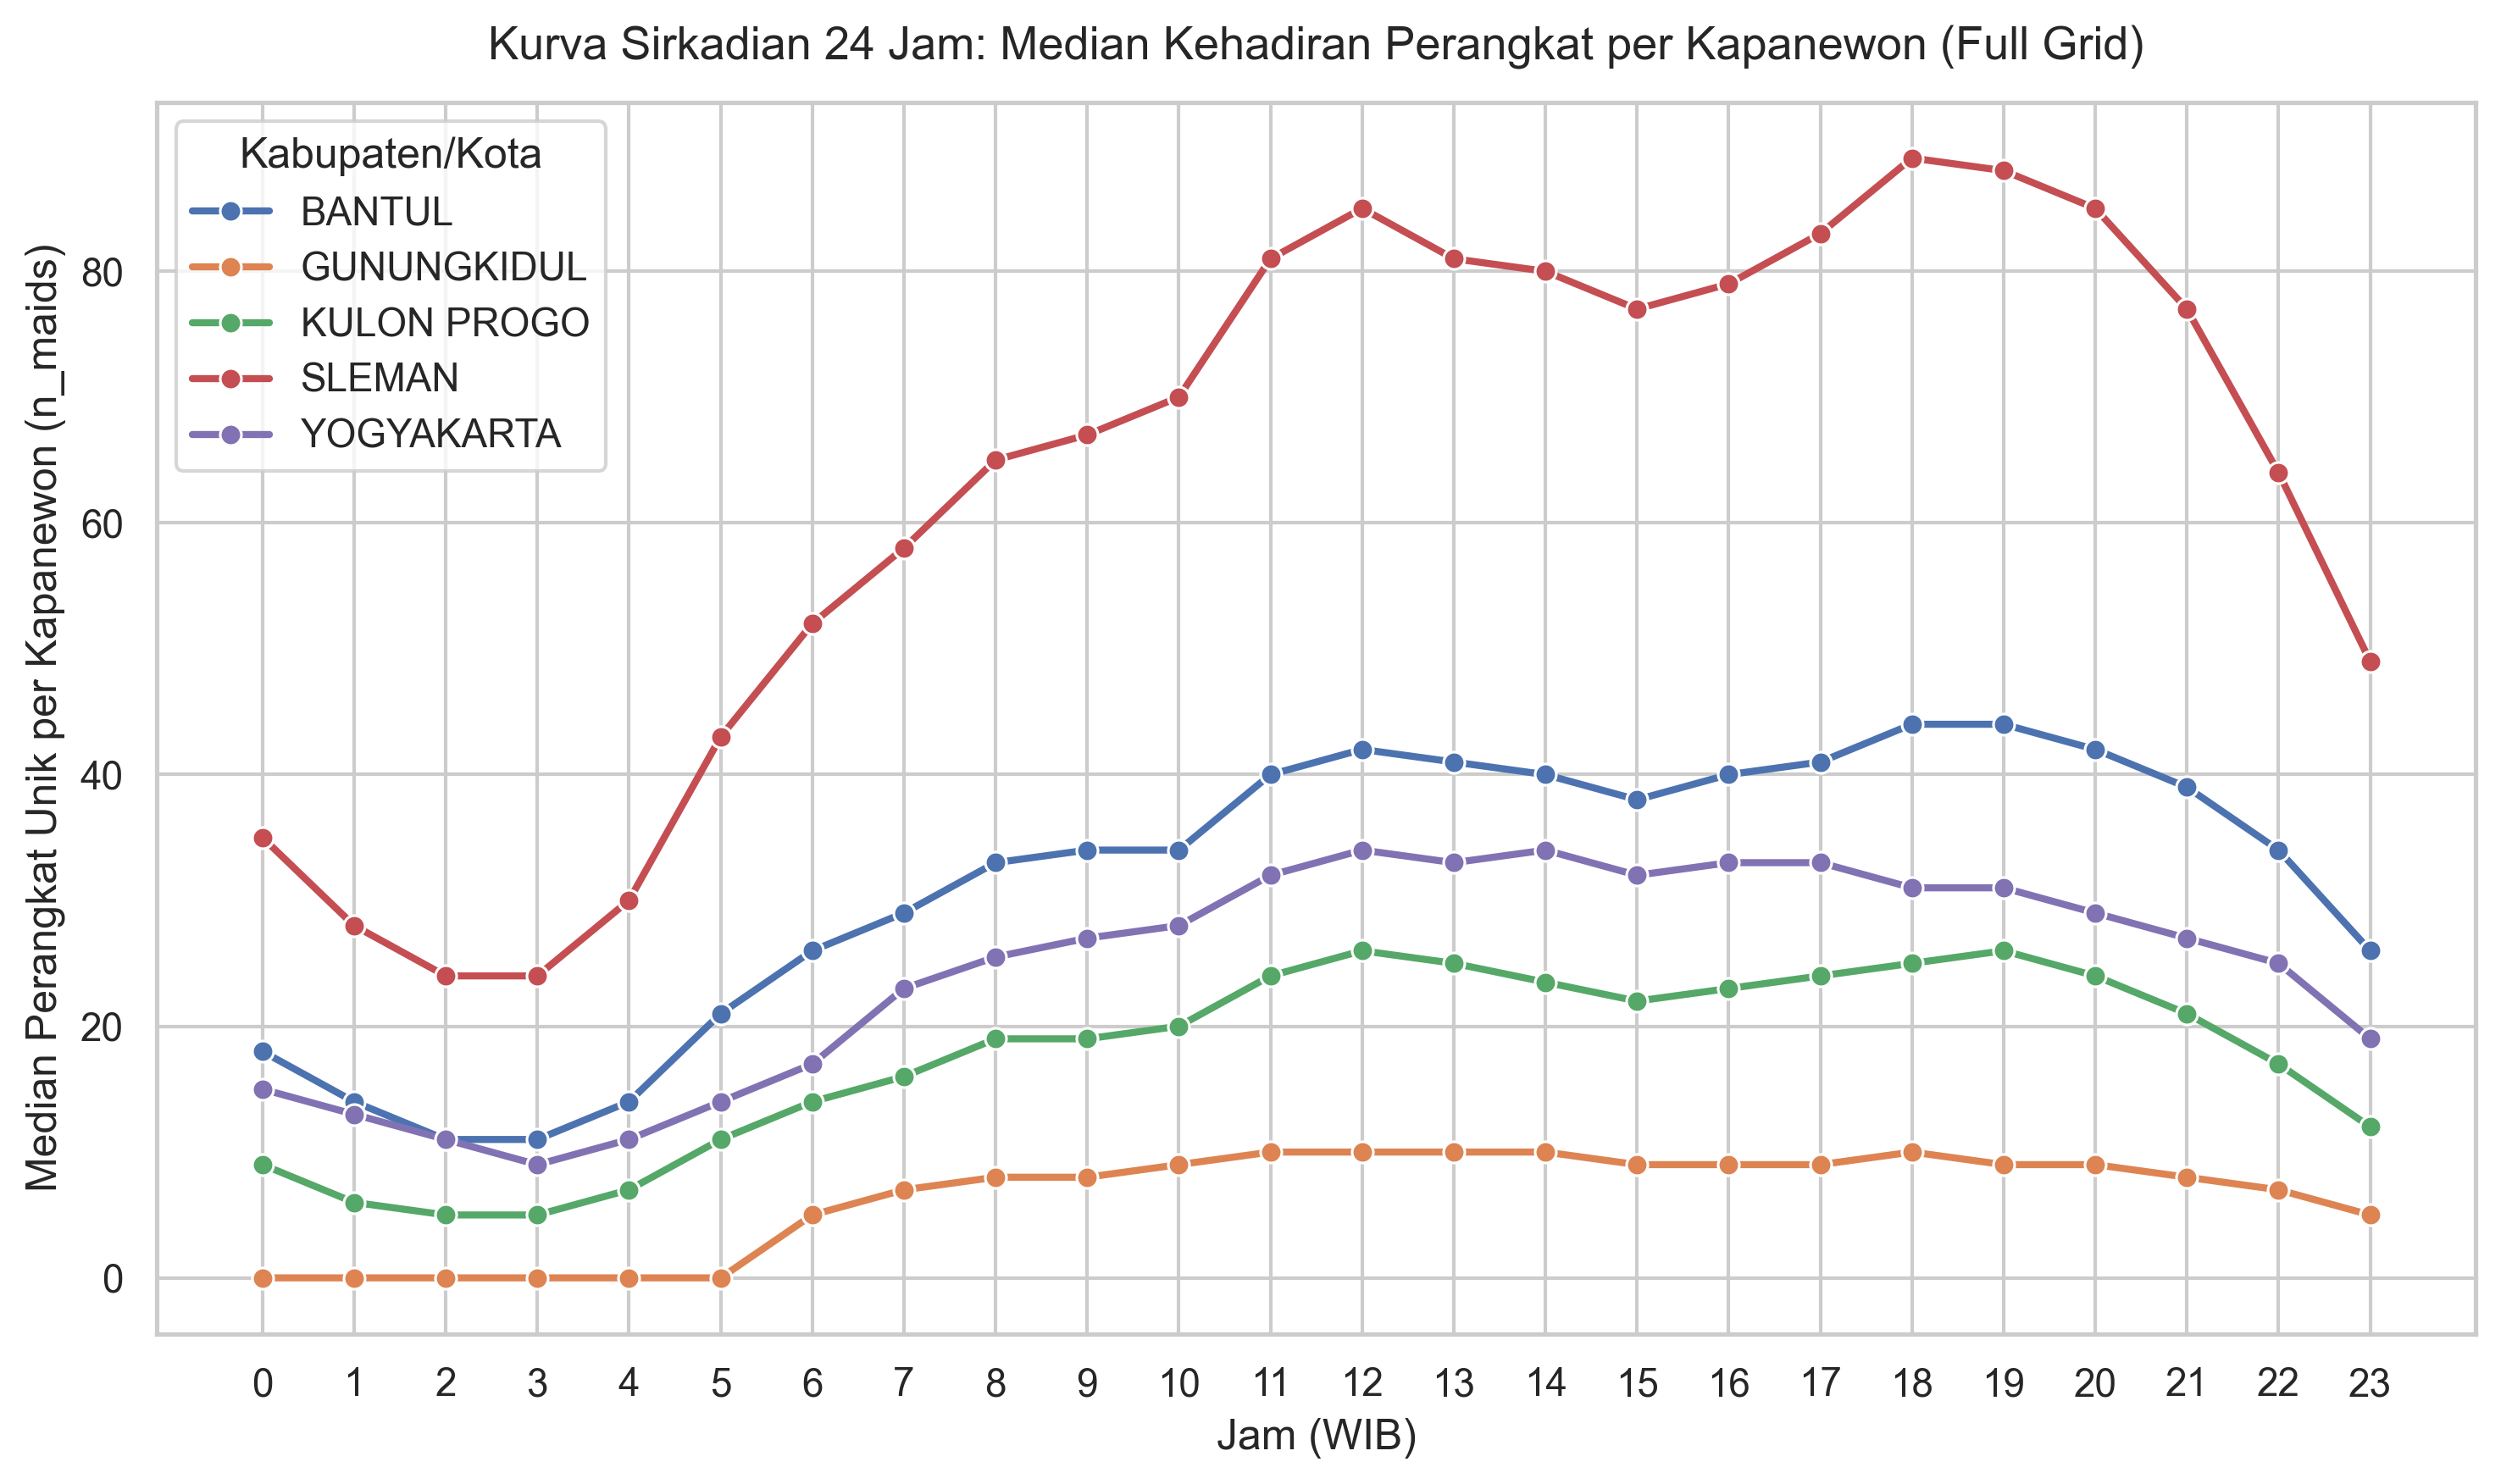

In [3]:
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.lineplot(
    data=circadian_stats,
    x="hour",
    y="median_maids",
    hue="kab_kota",
    marker="o",
    linewidth=2,
    ax=ax,
)
ax.set_title("Kurva Sirkadian 24 Jam: Median Kehadiran Perangkat per Kapanewon (Full Grid)", fontsize=13, pad=12)
ax.set_xlabel("Jam (WIB)")
ax.set_ylabel("Median Perangkat Unik per Kapanewon (n_maids)")
ax.set_xticks(range(0, 24))
ax.legend(title="Kabupaten/Kota", frameon=True)
plt.tight_layout()
plt.savefig("figures/01a_kurva_sirkadian_24jam.png", dpi=300, bbox_inches="tight")
plt.show()

   kab_kota  rasio_siang_malam
GUNUNGKIDUL           4.034861
KULON PROGO           3.283906
     BANTUL           2.576798
     SLEMAN           2.403056
 YOGYAKARTA           1.800091


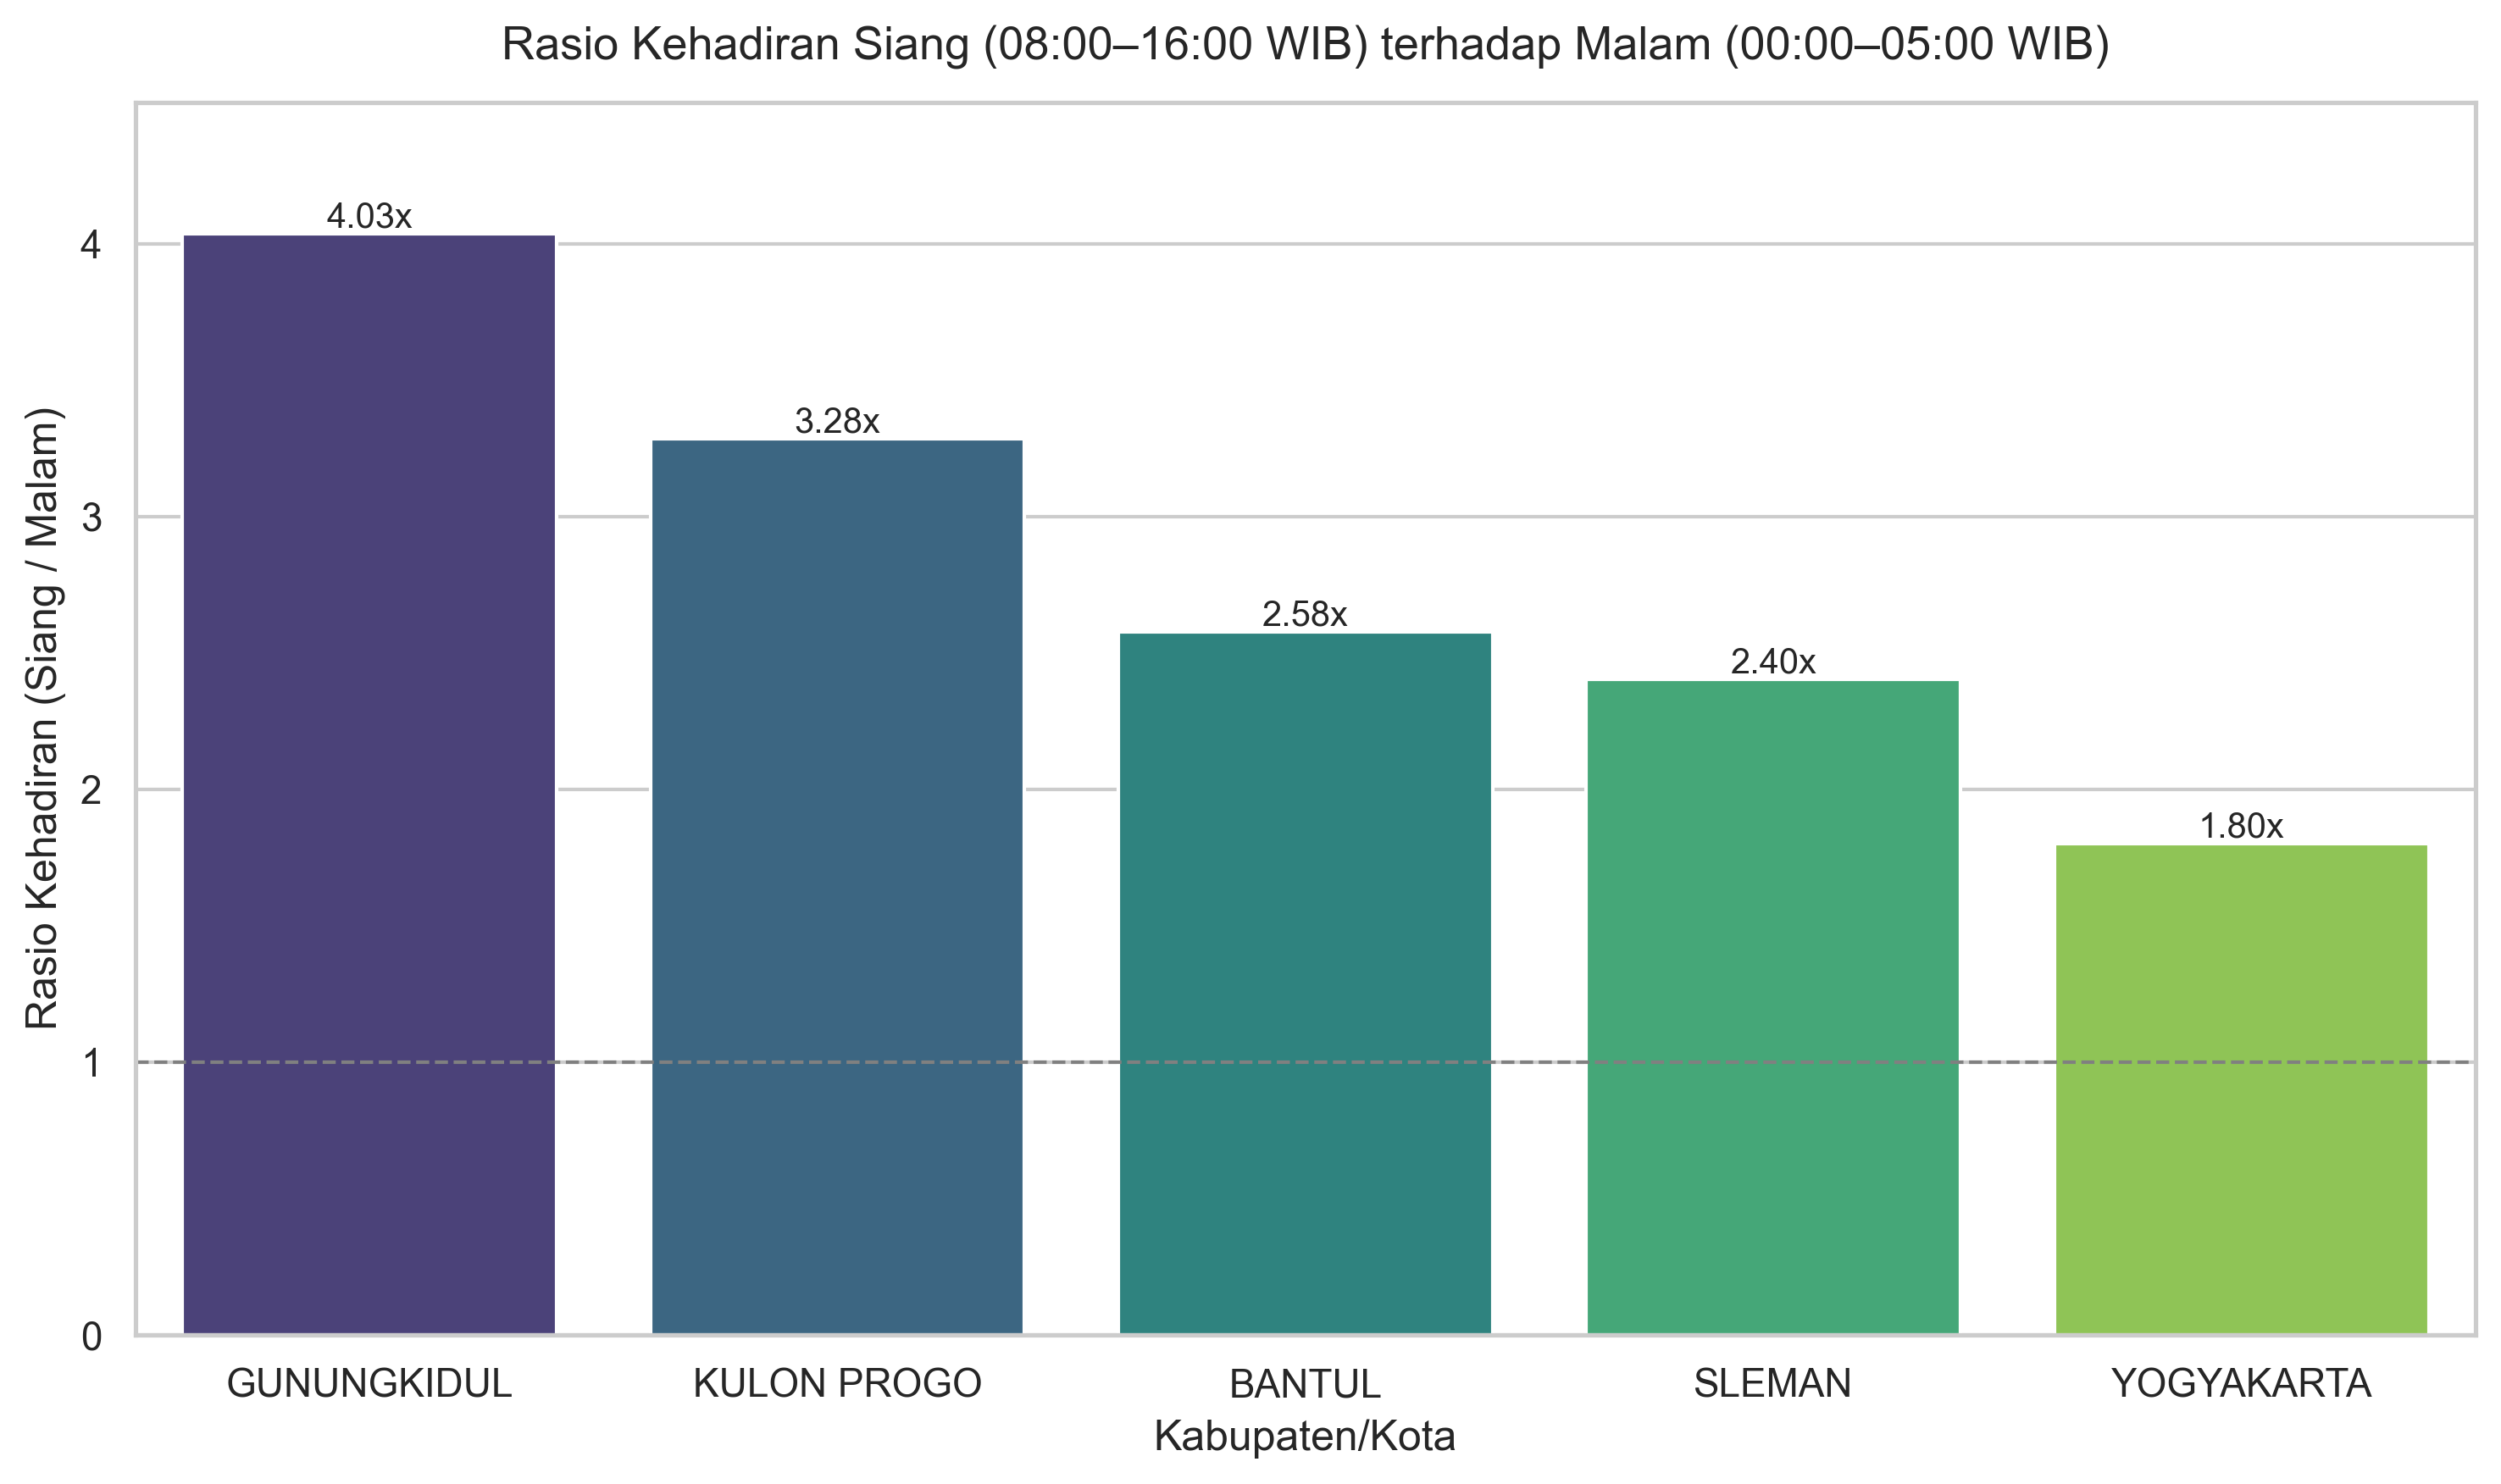

In [4]:
day_mask = kab_hourly["hour"].between(8, 16)
night_mask = kab_hourly["hour"].between(0, 5)

day_mean = kab_hourly[day_mask].groupby("kab_kota")["total_kab_maids"].mean()
night_mean = kab_hourly[night_mask].groupby("kab_kota")["total_kab_maids"].mean()
day_night_ratio = (
    (day_mean / night_mean)
    .sort_values(ascending=False)
    .reset_index(name="rasio_siang_malam")
)
print(day_night_ratio.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.barplot(
    data=day_night_ratio,
    x="kab_kota",
    y="rasio_siang_malam",
    hue="kab_kota",
    palette="viridis",
    legend=False,
    ax=ax,
)
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.2f}x",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
    )
ax.set_title("Rasio Kehadiran Siang (08:00–16:00 WIB) terhadap Malam (00:00–05:00 WIB)", fontsize=13, pad=12)
ax.set_xlabel("Kabupaten/Kota")
ax.set_ylabel("Rasio Kehadiran (Siang / Malam)")
ax.set_ylim(0, day_night_ratio["rasio_siang_malam"].max() * 1.12)
plt.tight_layout()
plt.savefig("figures/01b_rasio_siang_malam.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Bagian 1:**
- Dengan menggunakan **median pada grid lengkap**, ritme sirkadian 5 Kabupaten/Kota menurun secara konsisten menuju titik terendah pada dini hari (`02:00–04:00 WIB`) tanpa distorsi lonjakan palsu pukul `01:00 WIB` di Kota Yogyakarta (yang berasal dari artefak *centroid* di Kemantren Gondomanan), lalu meningkat tajam mulai `05:00 WIB` menuju dataran tinggi aktivitas siang–sore (`11:00–19:00 WIB`).
- Setelah menghilangkan *survivorship bias* jam malam, **Gunungkidul** tercatat memiliki rasio siang/malam paling tajam (**4,03x**), disusul **Kulon Progo (3,28x)**, **Bantul (2,58x)**, **Sleman (2,40x)**, dan **Kota Yogyakarta (1,80x)** yang lebih stabil siang-malam sebagai pusat permukiman dan aktivitas perkotaan.

## Bagian 2: Komparasi Hari Kerja (Weekday) vs Akhir Pekan (Weekend)

Mengelompokkan tanggal menjadi Hari Kerja (Senin–Jumat) dan Akhir Pekan (Sabtu–Minggu) untuk mengidentifikasi 15 kapanewon terpadat (menggunakan `kapanewon_label` yang terdisambiguasi) serta memetakan pola aktivitas mingguan dalam matriks 7 hari × 24 jam.

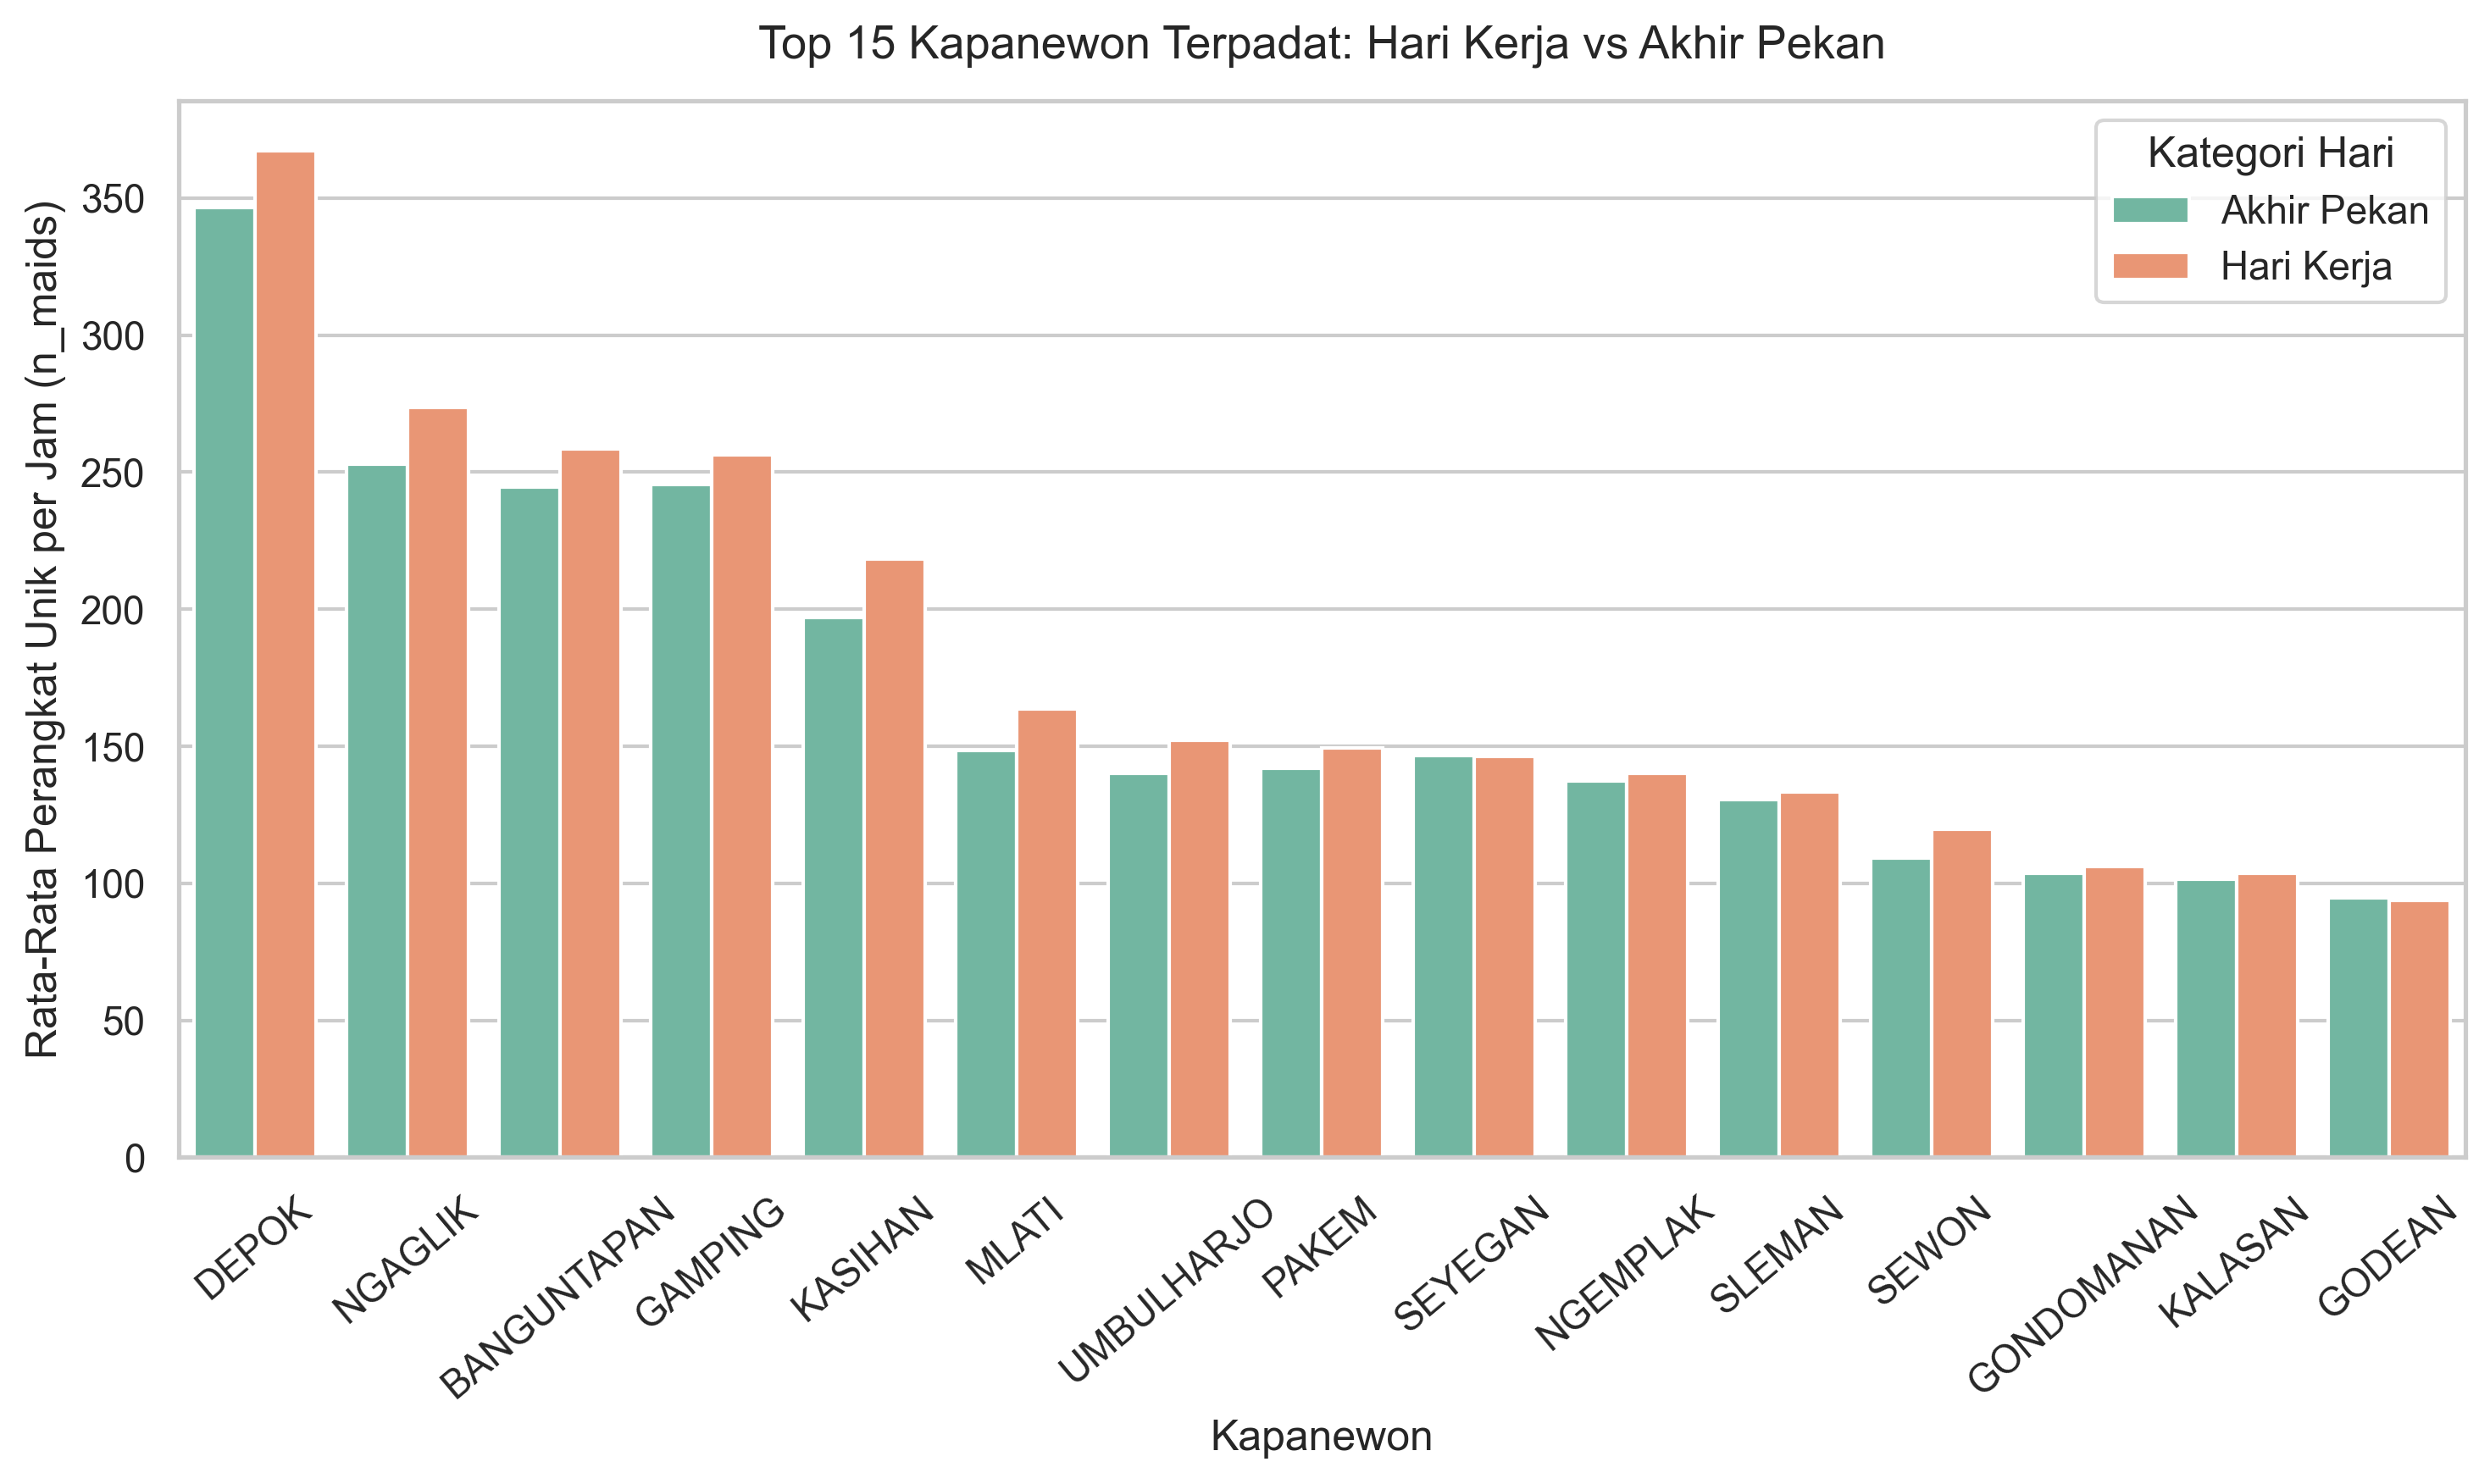

In [5]:
df_presence["dayofweek"] = df_presence["date"].dt.dayofweek
day_map = {
    0: "Senin",
    1: "Selasa",
    2: "Rabu",
    3: "Kamis",
    4: "Jumat",
    5: "Sabtu",
    6: "Minggu",
}
day_order = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
df_presence["nama_hari"] = df_presence["dayofweek"].map(day_map)
df_presence["tipe_hari"] = np.where(df_presence["dayofweek"] < 5, "Hari Kerja", "Akhir Pekan")

kapanewon_daytype = (
    df_presence.groupby(["kapanewon_label", "tipe_hari"])["n_maids"]
    .mean()
    .reset_index()
)
order_top15 = (
    df_presence.groupby("kapanewon_label")["n_maids"]
    .mean()
    .nlargest(15)
    .index
)
top15_df = kapanewon_daytype[kapanewon_daytype["kapanewon_label"].isin(order_top15)].copy()

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.barplot(
    data=top15_df,
    x="kapanewon_label",
    y="n_maids",
    hue="tipe_hari",
    order=order_top15,
    palette="Set2",
    ax=ax,
)
ax.set_title("Top 15 Kapanewon Terpadat: Hari Kerja vs Akhir Pekan", fontsize=13, pad=12)
ax.set_xlabel("Kapanewon")
ax.set_ylabel("Rata-Rata Perangkat Unik per Jam (n_maids)")
ax.tick_params(axis="x", rotation=40)
ax.legend(title="Kategori Hari", frameon=True)
plt.tight_layout()
plt.savefig("figures/02a_top15_kapanewon_weekday_weekend.png", dpi=300, bbox_inches="tight")
plt.show()

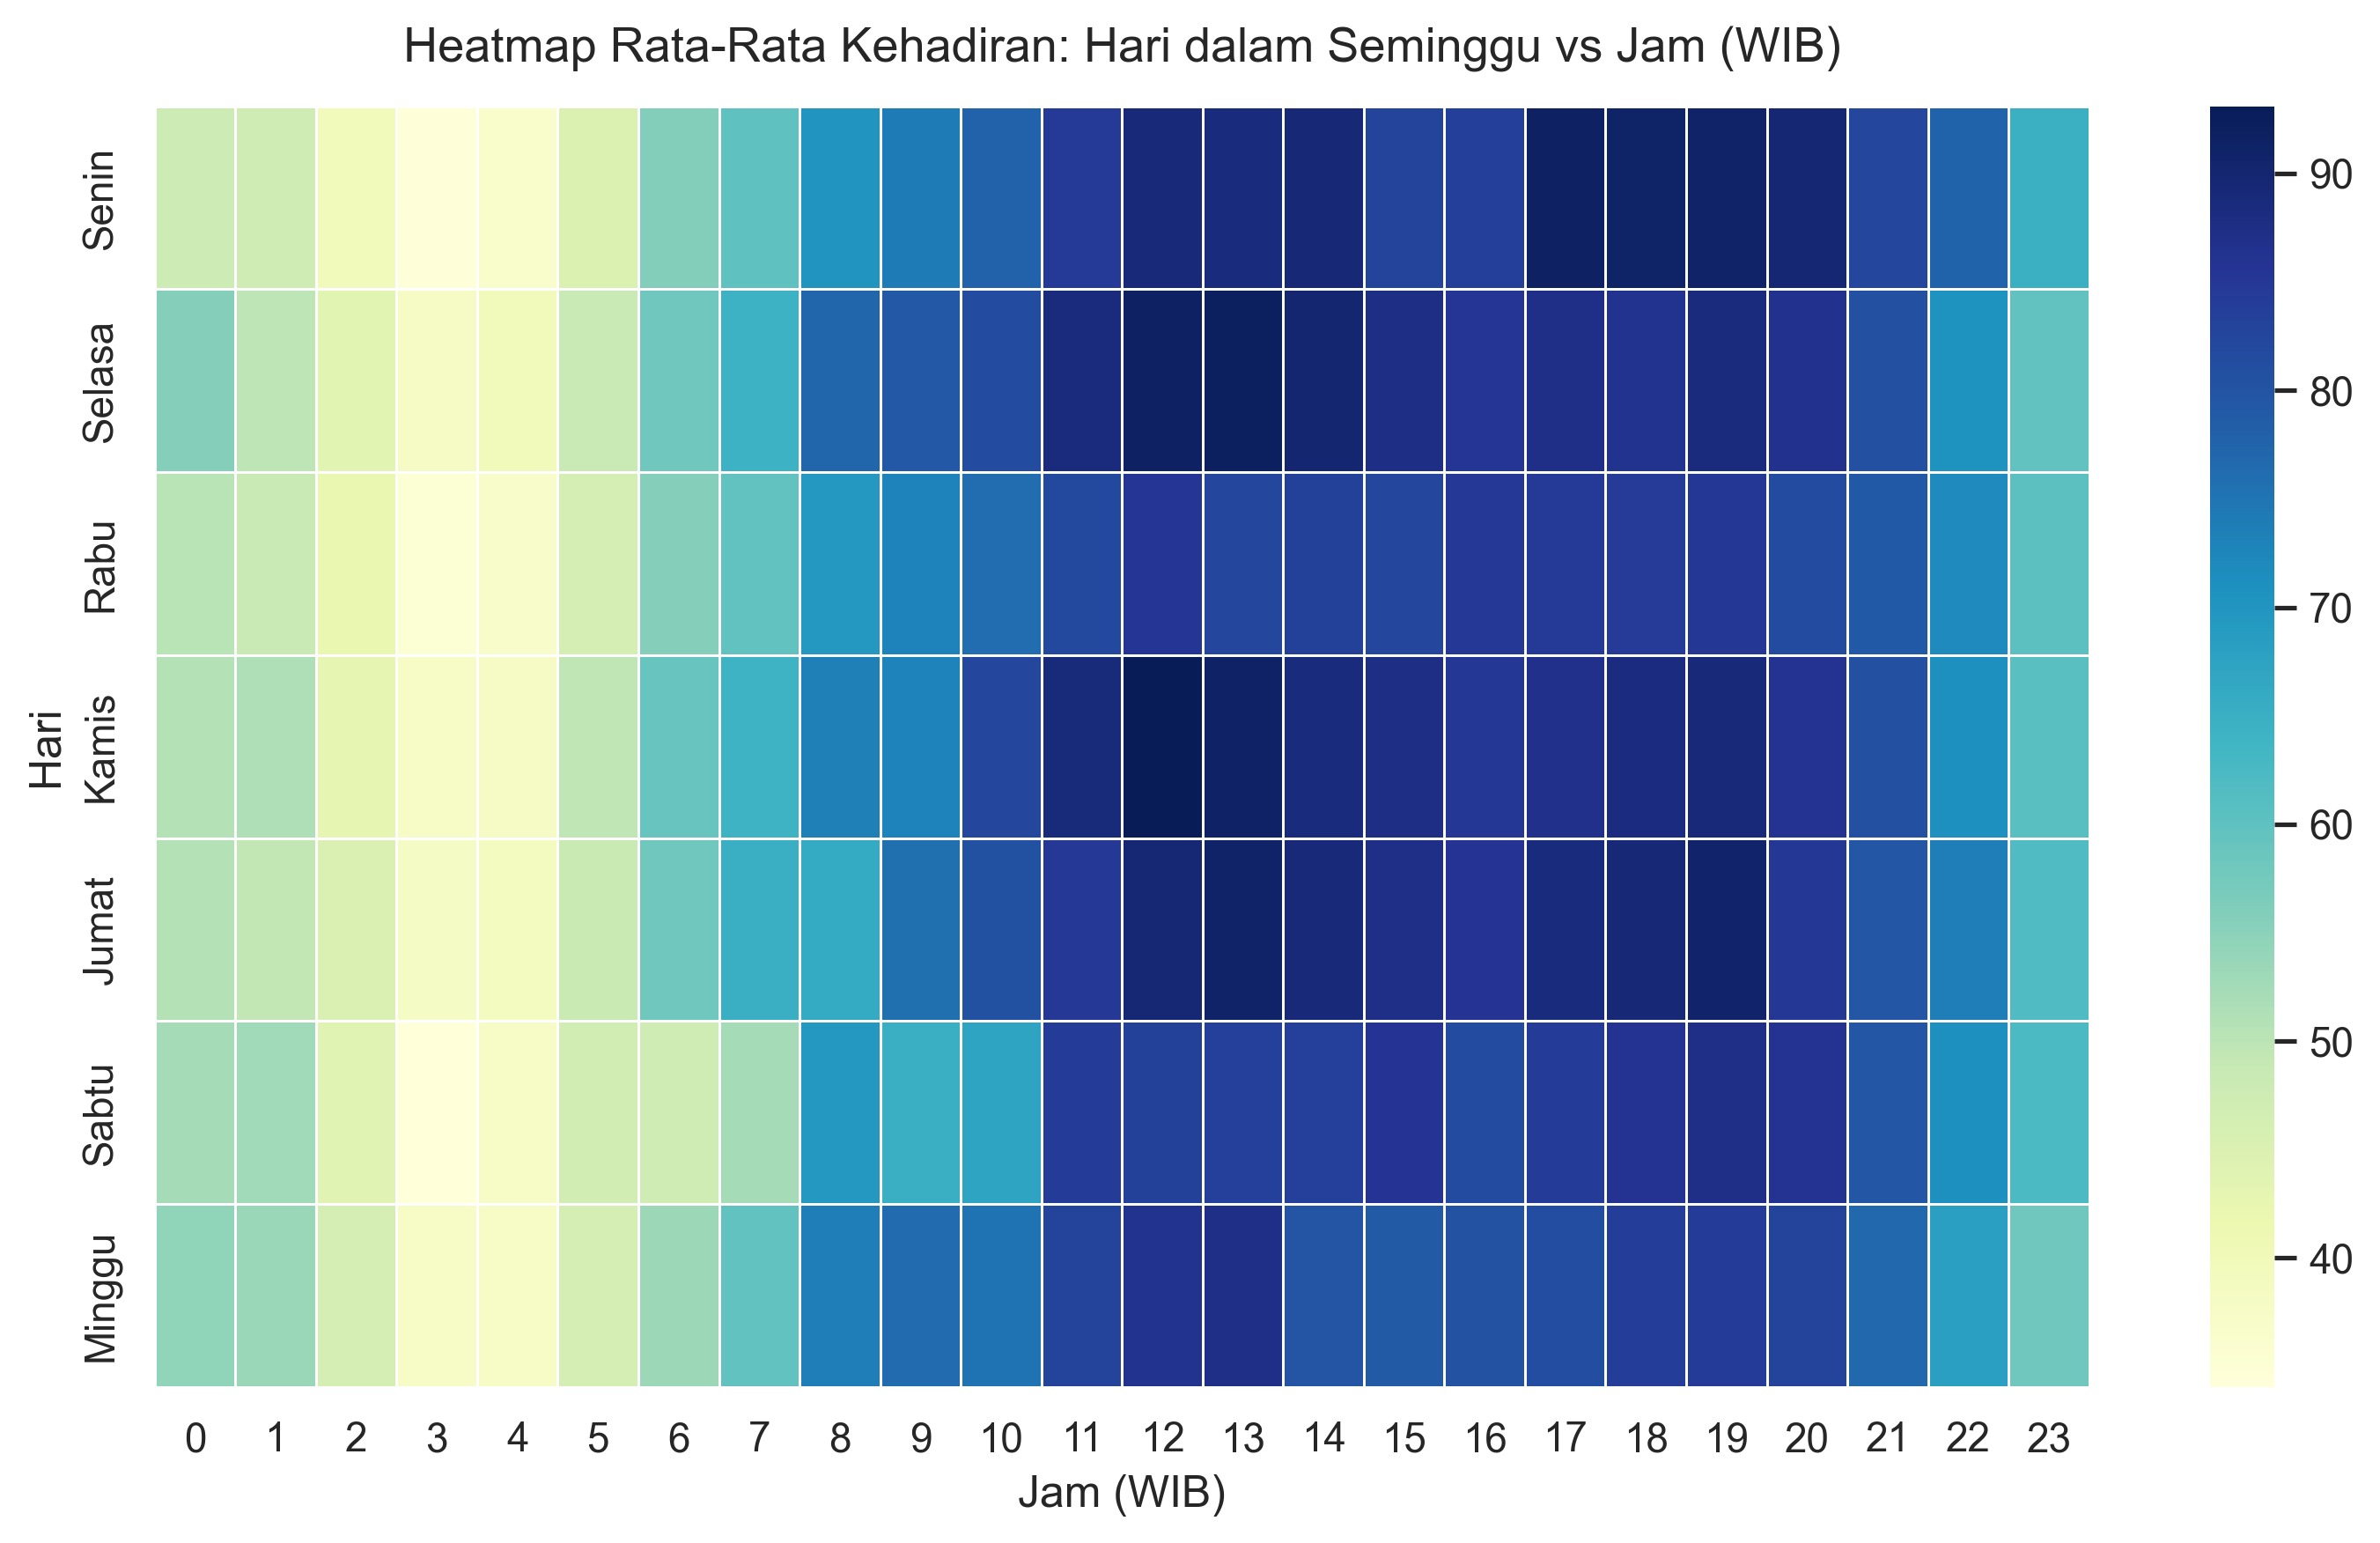

In [6]:
heatmap_day_hour = (
    df_presence.groupby(["nama_hari", "hour"])["n_maids"]
    .mean()
    .unstack(level="hour")
    .reindex(day_order)
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.heatmap(heatmap_day_hour, cmap="YlGnBu", linewidths=0.3, ax=ax)
ax.set_title("Heatmap Rata-Rata Kehadiran: Hari dalam Seminggu vs Jam (WIB)", fontsize=13, pad=12)
ax.set_xlabel("Jam (WIB)")
ax.set_ylabel("Hari")
plt.tight_layout()
plt.savefig("figures/02b_heatmap_hari_vs_jam.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Bagian 2:**
- **Depok (Sleman)** jauh melampaui kapanewon lainnya (~367 perangkat/jam pada hari kerja dan ~346 pada akhir pekan), diikuti oleh kawasan penyangga aglomerasi perkotaan seperti Ngaglik, Banguntapan, Gamping, Kasihan, dan Mlati.
- Sebagian besar kapanewon pusat pendidikan dan perkantoran (Depok, Ngaglik, Kasihan, Mlati, Umbulharjo) mencatat kepadatan lebih tinggi pada **Hari Kerja**, sedangkan beberapa kapanewon pinggiran/semi-suburban (seperti Seyegan dan Godean) relatif seimbang antara hari kerja dan akhir pekan.

## Bagian 3: Tren Longitudinal 151 Hari, Libur Tahun Baru, & Pergeseran Ramadhan

Mengagregasi total kehadiran perangkat-jam harian selama 151 hari (1 Desember 2021 – 30 April 2022) dengan menandai titik awal penurunan sampel data (`16 Februari 2022`), lalu membandingkan **proporsi aktivitas per jam (%)** antara periode **Normal (Desember 2021 – Februari 2022)** dan **Ramadhan 1443 H (April 2022)** agar pergeseran jam aktif tidak tertutupi oleh penurunan volume sampel.

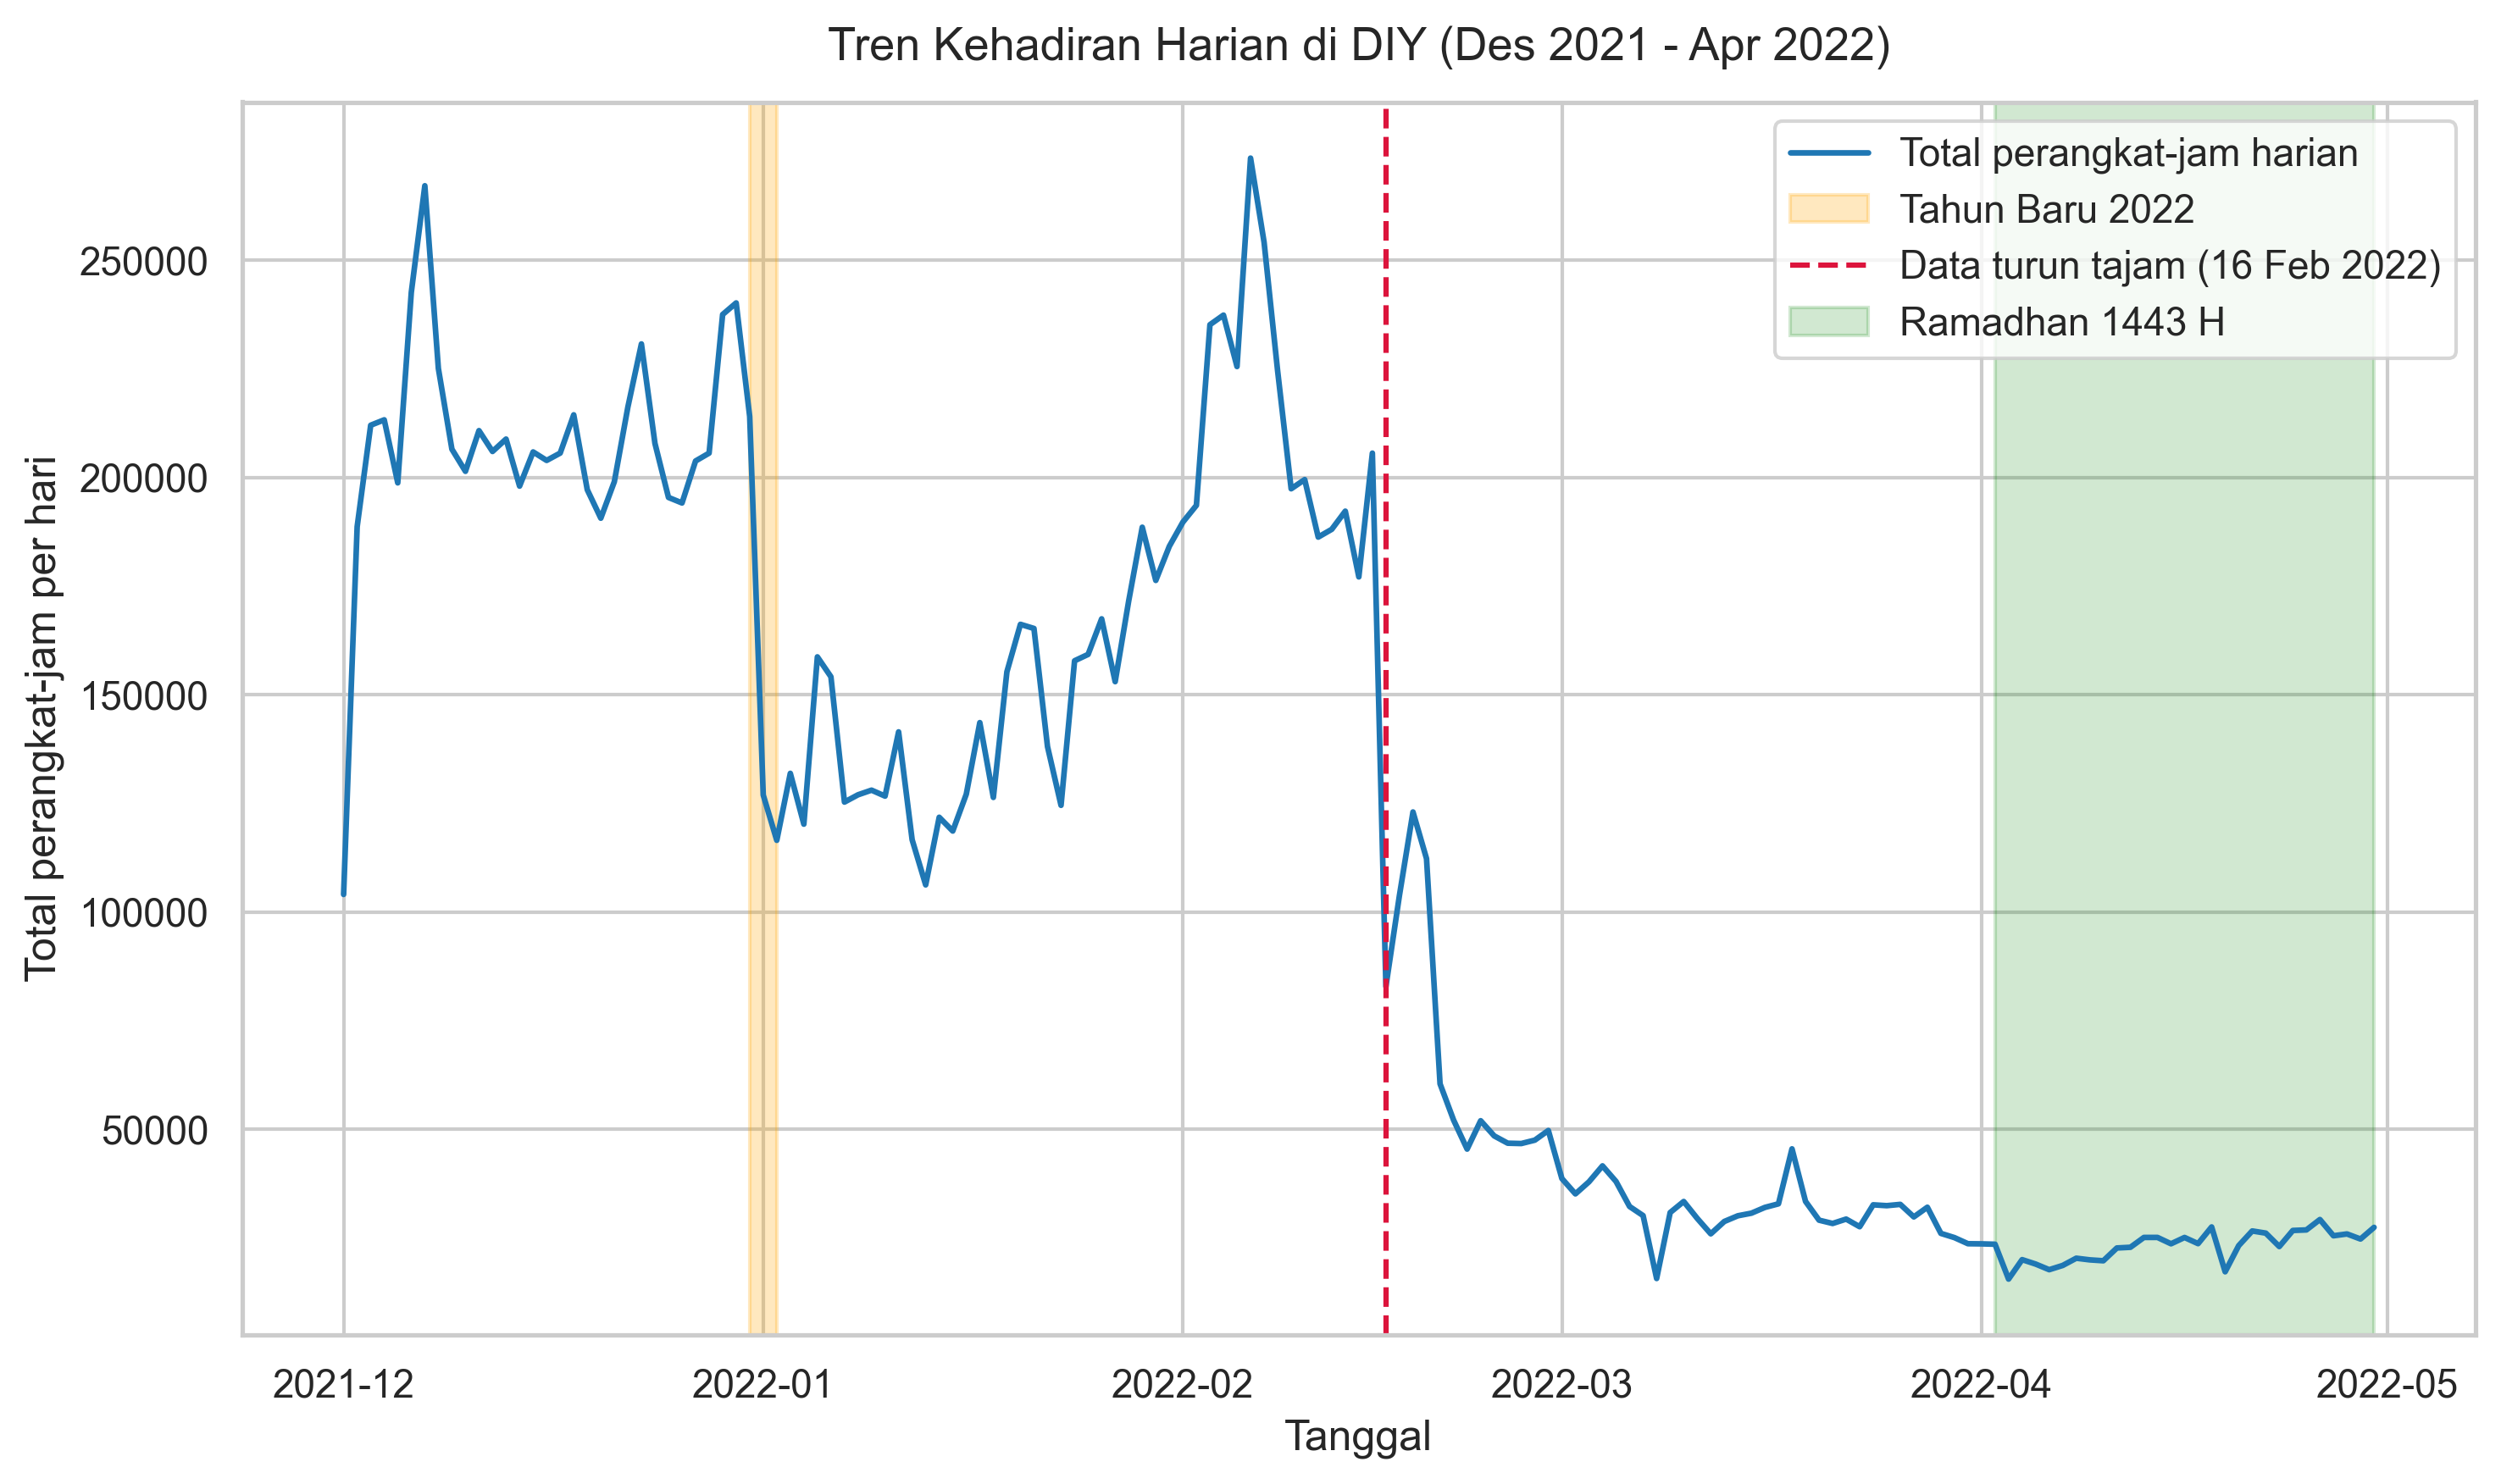

Rata-rata harian per bulan:
date
2021-12    207906.0
2022-01    142749.0
2022-02    144690.0
2022-03     31365.0
2022-04     23254.0
Freq: M, Name: n_maids, dtype: float64

Sekitar Tahun Baru:
date
2021-12-29    237492
2021-12-30    240158
2021-12-31    214019
2022-01-01    126943
2022-01-02    116516
2022-01-03    131931
Name: n_maids, dtype: int64

Sekitar turunnya data:
date
2022-02-14    177125
2022-02-15    205599
2022-02-16     82879
2022-02-17    103856
2022-02-18    123039
2022-02-19    112307
2022-02-20     60491
2022-02-21     52155
2022-02-22     45479
Name: n_maids, dtype: int64


In [4]:
# total n_maids per hari, dipakai sebagai indeks keramaian
daily_trend = df_presence.groupby("date")["n_maids"].sum().reset_index()

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.plot(daily_trend["date"], daily_trend["n_maids"], color="#1f77b4", linewidth=1.6, label="Total perangkat-jam harian")
ax.axvspan(pd.Timestamp("2021-12-31"), pd.Timestamp("2022-01-02"), color="orange", alpha=0.25, label="Tahun Baru 2022")
ax.axvline(pd.Timestamp("2022-02-16"), color="crimson", linestyle="--", linewidth=1.5, label="Data turun tajam (16 Feb 2022)")
ax.axvspan(pd.Timestamp("2022-04-02"), pd.Timestamp("2022-04-30"), color="green", alpha=0.18, label="Ramadhan 1443 H")
ax.set_title("Tren Kehadiran Harian di DIY (Des 2021 - Apr 2022)", fontsize=13, pad=12)
ax.set_xlabel("Tanggal")
ax.set_ylabel("Total perangkat-jam per hari")
ax.legend(frameon=True)
plt.tight_layout()
plt.savefig("figures/03a_tren_harian_151hari.png", dpi=300, bbox_inches="tight")
plt.show()

# angka kasar buat dicek
d = daily_trend.set_index("date")["n_maids"]
print("Rata-rata harian per bulan:")
print(d.groupby(d.index.to_period("M")).mean().round(0))
print("\nSekitar Tahun Baru:")
print(d["2021-12-29":"2022-01-03"])
print("\nSekitar turunnya data:")
print(d["2022-02-14":"2022-02-22"])

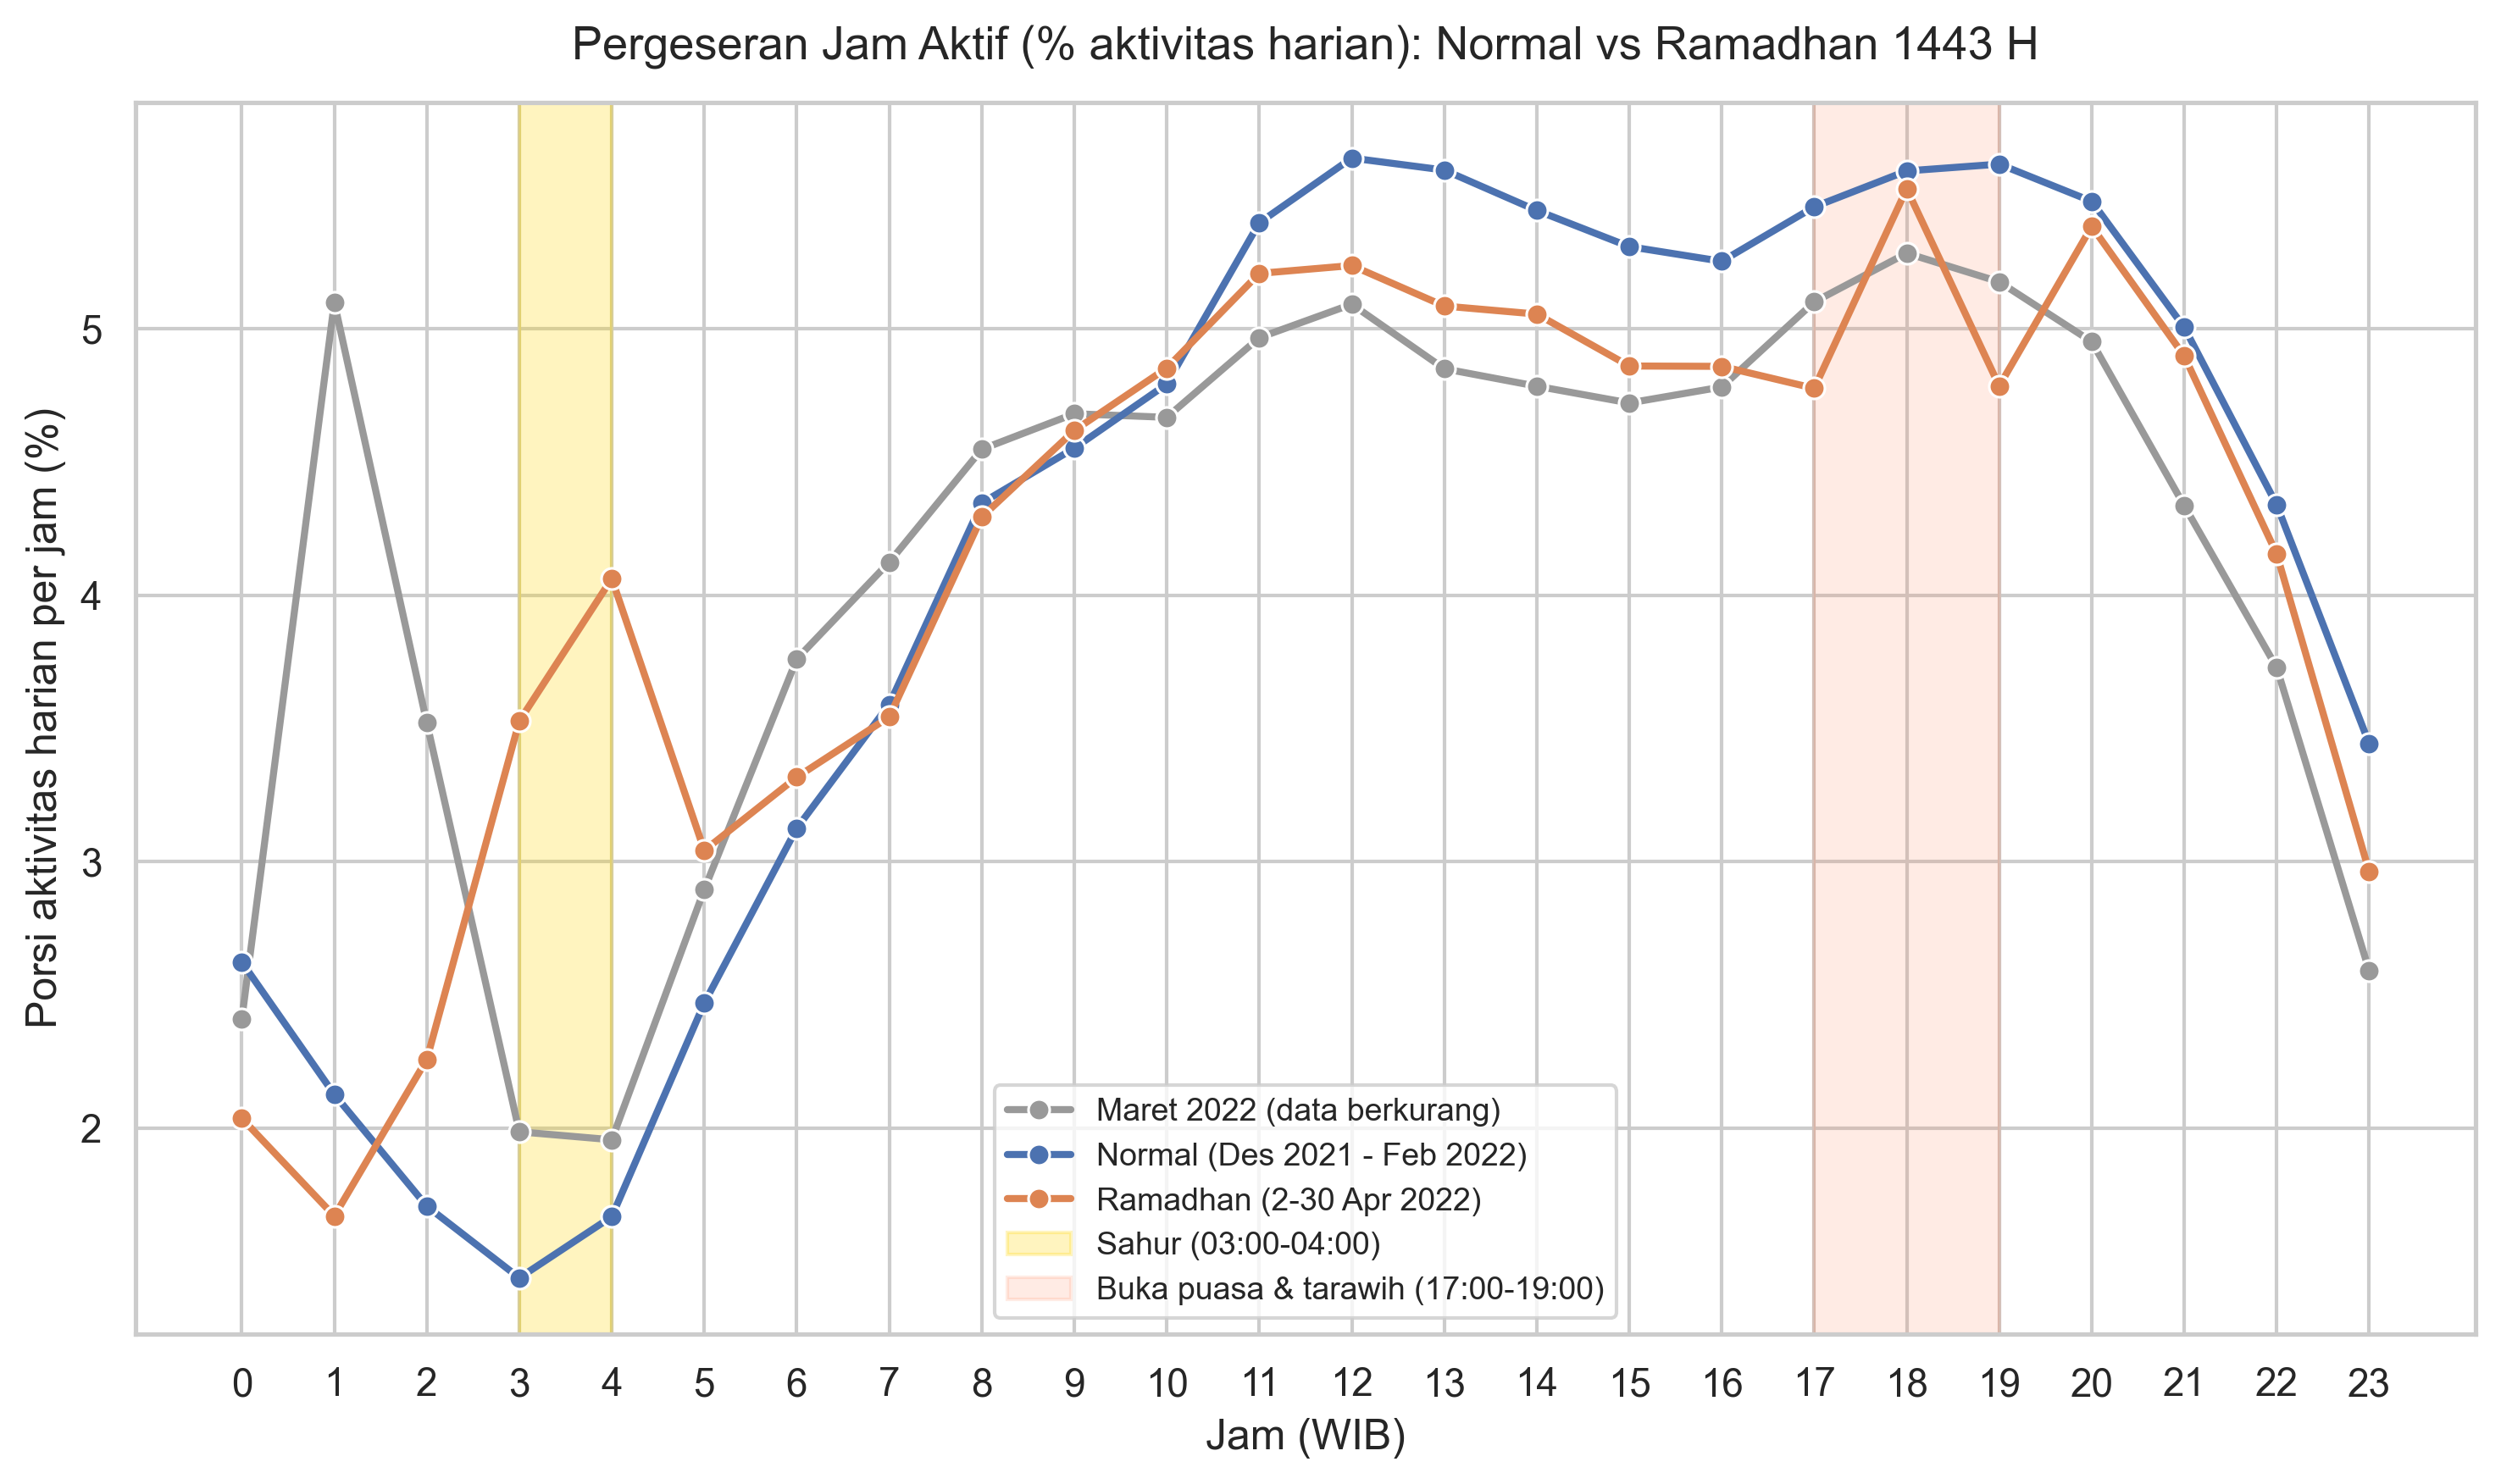

periode  Maret 2022 (data berkurang)  Normal (Des 2021 - Feb 2022)  \
hour                                                                 
2                               3.52                          1.71   
3                               1.99                          1.44   
4                               1.96                          1.67   
5                               2.89                          2.47   
17                              5.10                          5.46   
18                              5.28                          5.59   
19                              5.18                          5.62   
20                              4.95                          5.48   

periode  Ramadhan (2-30 Apr 2022)  
hour                               
2                            2.26  
3                            3.53  
4                            4.06  
5                            3.04  
17                           4.78  
18                           5.53  
19         

In [5]:
# tiga periode: normal (Des-Feb), Maret sebagai pembanding, Ramadhan (2-30 Apr)
d_ = df_presence["date"]
df_per = df_presence.copy()
df_per["periode"] = np.select(
    [d_ < pd.Timestamp("2022-03-01"), d_ < pd.Timestamp("2022-04-01"), d_ >= pd.Timestamp("2022-04-02")],
    ["Normal (Des 2021 - Feb 2022)", "Maret 2022 (data berkurang)", "Ramadhan (2-30 Apr 2022)"],
    default="lainnya",
)
df_per = df_per[df_per["periode"] != "lainnya"]

prof = df_per.groupby(["periode", "hour"])["n_maids"].agg(total="sum", rata2="mean").reset_index()
# ubah ke persen dari total sehari, biar skalanya sama
prof["persen"] = prof["total"] / prof.groupby("periode")["total"].transform("sum") * 100

warna = {
    "Normal (Des 2021 - Feb 2022)": "#4c72b0",
    "Maret 2022 (data berkurang)": "#999999",
    "Ramadhan (2-30 Apr 2022)": "#dd8452",
}

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.lineplot(data=prof, x="hour", y="persen", hue="periode", palette=warna, marker="o", linewidth=2, ax=ax)
ax.axvspan(3, 4, color="gold", alpha=0.25, label="Sahur (03:00-04:00)")
ax.axvspan(17, 19, color="coral", alpha=0.15, label="Buka puasa & tarawih (17:00-19:00)")
ax.set_title("Pergeseran Jam Aktif (% aktivitas harian): Normal vs Ramadhan 1443 H", fontsize=13, pad=12)
ax.set_xlabel("Jam (WIB)")
ax.set_ylabel("Porsi aktivitas harian per jam (%)")
ax.set_xticks(range(0, 24))
ax.legend(frameon=True, fontsize=9)
plt.tight_layout()
plt.savefig("figures/03b_pergeseran_jam_ramadhan.png", dpi=300, bbox_inches="tight")
plt.show()

piv = prof.pivot(index="hour", columns="periode", values="persen").round(2)
print(piv.loc[[2, 3, 4, 5, 17, 18, 19, 20]])

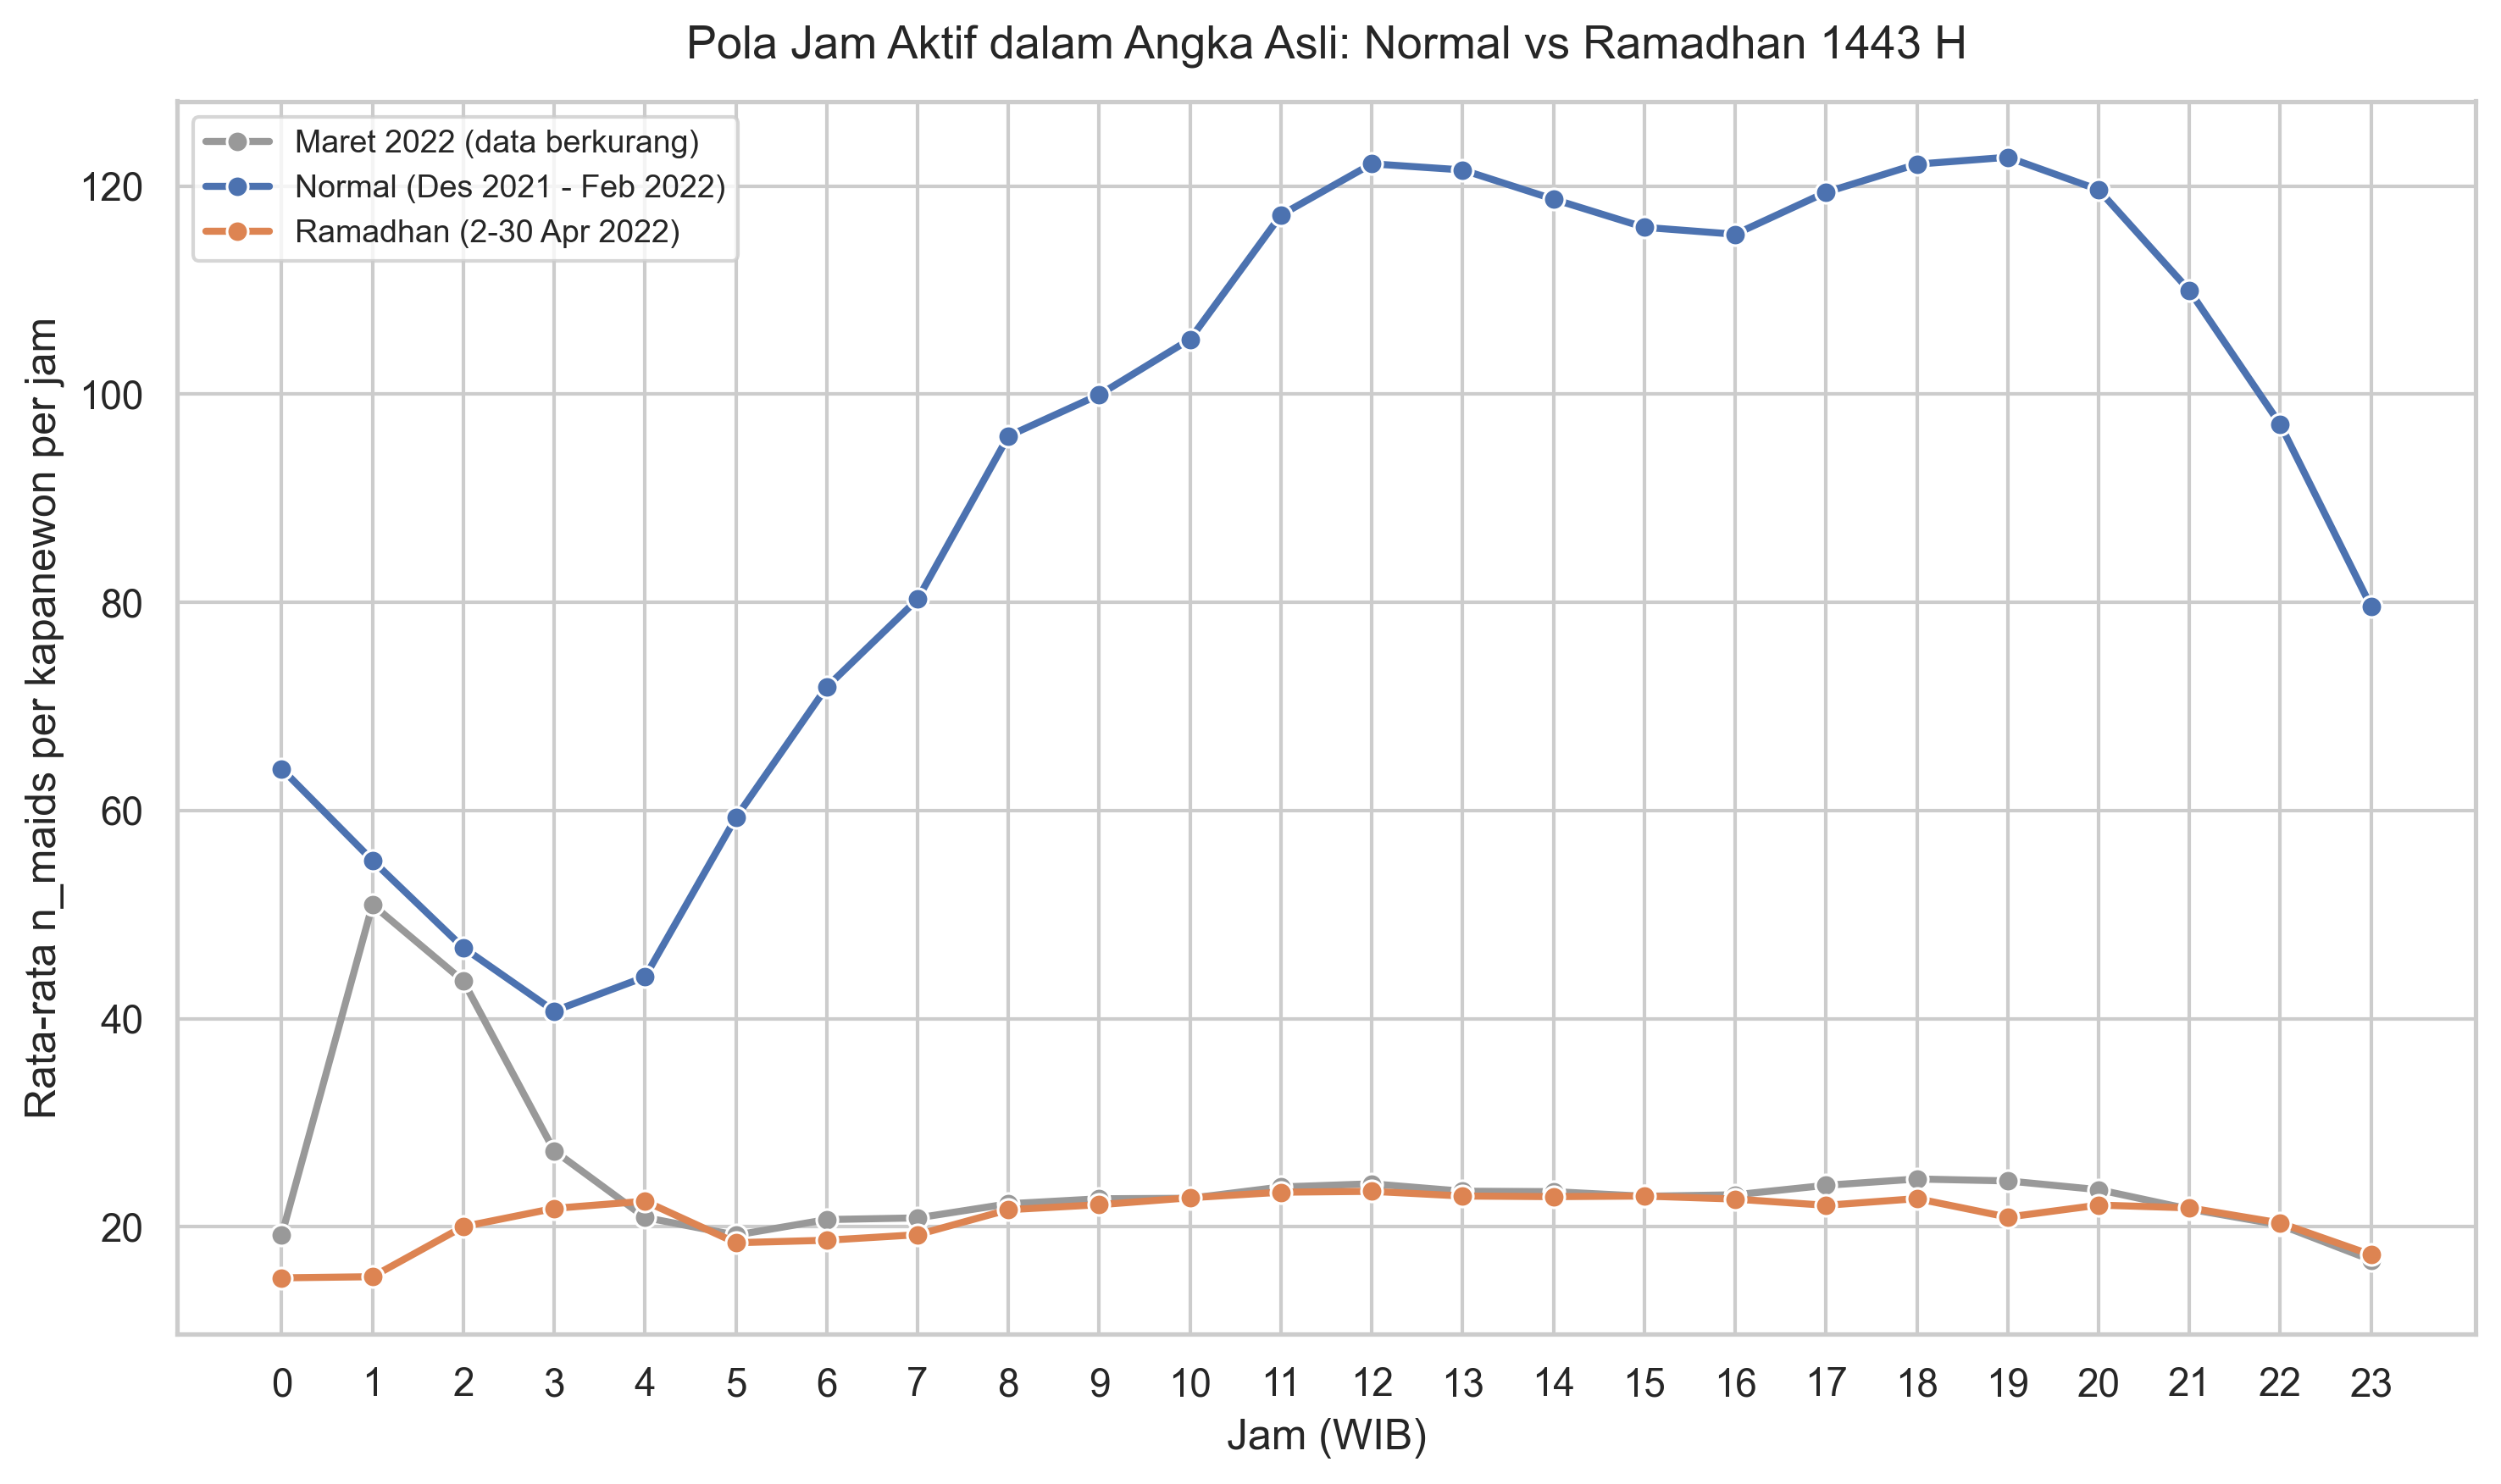

In [6]:
# versi angka asli (tidak dinormalisasi), kelihatan skala April jauh lebih kecil
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.lineplot(data=prof, x="hour", y="rata2", hue="periode", palette=warna, marker="o", linewidth=2, ax=ax)
ax.set_title("Pola Jam Aktif dalam Angka Asli: Normal vs Ramadhan 1443 H", fontsize=13, pad=12)
ax.set_xlabel("Jam (WIB)")
ax.set_ylabel("Rata-rata n_maids per kapanewon per jam")
ax.set_xticks(range(0, 24))
ax.legend(frameon=True, fontsize=9)
plt.tight_layout()
plt.savefig("figures/03c_profil_jam_absolut.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Bagian 3:**
- Aktivitas tinggi dari Desember sampai pertengahan Februari, turun sebentar waktu Tahun Baru (214 ribu di 31 Des jadi 127 ribu di 1 Jan). Lalu sekitar **16 Februari** angkanya jatuh tajam dan tidak pulih. Turunnya terlalu mendadak untuk ukuran perilaku orang, jadi kemungkinan besar karena jumlah sampel data berkurang (sejalan dengan penanda `reduced_quality`).
- Karena itu pola jam dibandingkan dalam persen. Saat Ramadhan, porsi aktivitas jam **03:00-04:00** naik dari sekitar 1,4-1,7% jadi 3,5-4,1% (kira-kira 2,4 kali lipat), kemungkinan terkait sahur.
- Maret 2022 (sama-sama data berkurang) porsi jam 03 dan 04 hanya sekitar 2% per jam (Ramadhan 3,5-4,1%), jadi kenaikan di April tidak cuma efek data yang berkurang. Tapi Maret juga punya lonjakan aneh di jam 01:00 (sekitar 5%), jadi tetap hati-hati, ini belum bisa dibilang pasti gara-gara Ramadhan.
- Sore dan malam: porsi jam 17:00 dan 19:00 turun sekitar 0,7-0,8 poin dibanding normal, sedangkan jam 18:00 dan 20:00 hampir sama.

## Bagian 4: Analisis Intensitas Aktivitas Sinyal (Rasio Pings per Perangkat)

Menghitung metrik `pings_per_maid = n_pings / n_maids` beserta **rata-rata tertimbang (`weighted_pings_per_maid = sum(n_pings) / sum(n_maids)`)** untuk menghindari bias bobot yang sama antara baris bersampel kecil dan baris padat perangkat, serta memetakan korelasi tingkat kapanewon pada **78 titik wilayah**.

In [9]:
df_presence["pings_per_maid"] = np.where(
    df_presence["n_maids"] > 0,
    df_presence["n_pings"] / df_presence["n_maids"],
    np.nan,
)

ping_summary = (
    df_presence.groupby("kab_kota")
    .agg(
        mean_maids=("n_maids", "mean"),
        mean_pings=("n_pings", "mean"),
        mean_pings_per_maid=("pings_per_maid", "mean"),
        median_pings_per_maid=("pings_per_maid", "median"),
        total_maids=("n_maids", "sum"),
        total_pings=("n_pings", "sum"),
    )
)
ping_summary["weighted_pings_per_maid"] = (
    ping_summary["total_pings"] / ping_summary["total_maids"]
)
ping_summary = ping_summary[
    ["mean_maids", "mean_pings", "mean_pings_per_maid", "median_pings_per_maid", "weighted_pings_per_maid"]
].round(2)
ping_summary

,mean_maids,mean_pings,mean_pings_per_maid,median_pings_per_maid,weighted_pings_per_maid
kab_kota,,,,,
BANTUL,78.83,191.01,2.50,2.33,2.42
GUNUNGKIDUL,24.53,63.21,2.63,2.33,2.58
KULON PROGO,36.46,98.56,2.62,2.40,2.70
SLEMAN,132.99,363.44,2.64,2.45,2.73
YOGYAKARTA,53.34,151.62,2.65,2.41,2.84


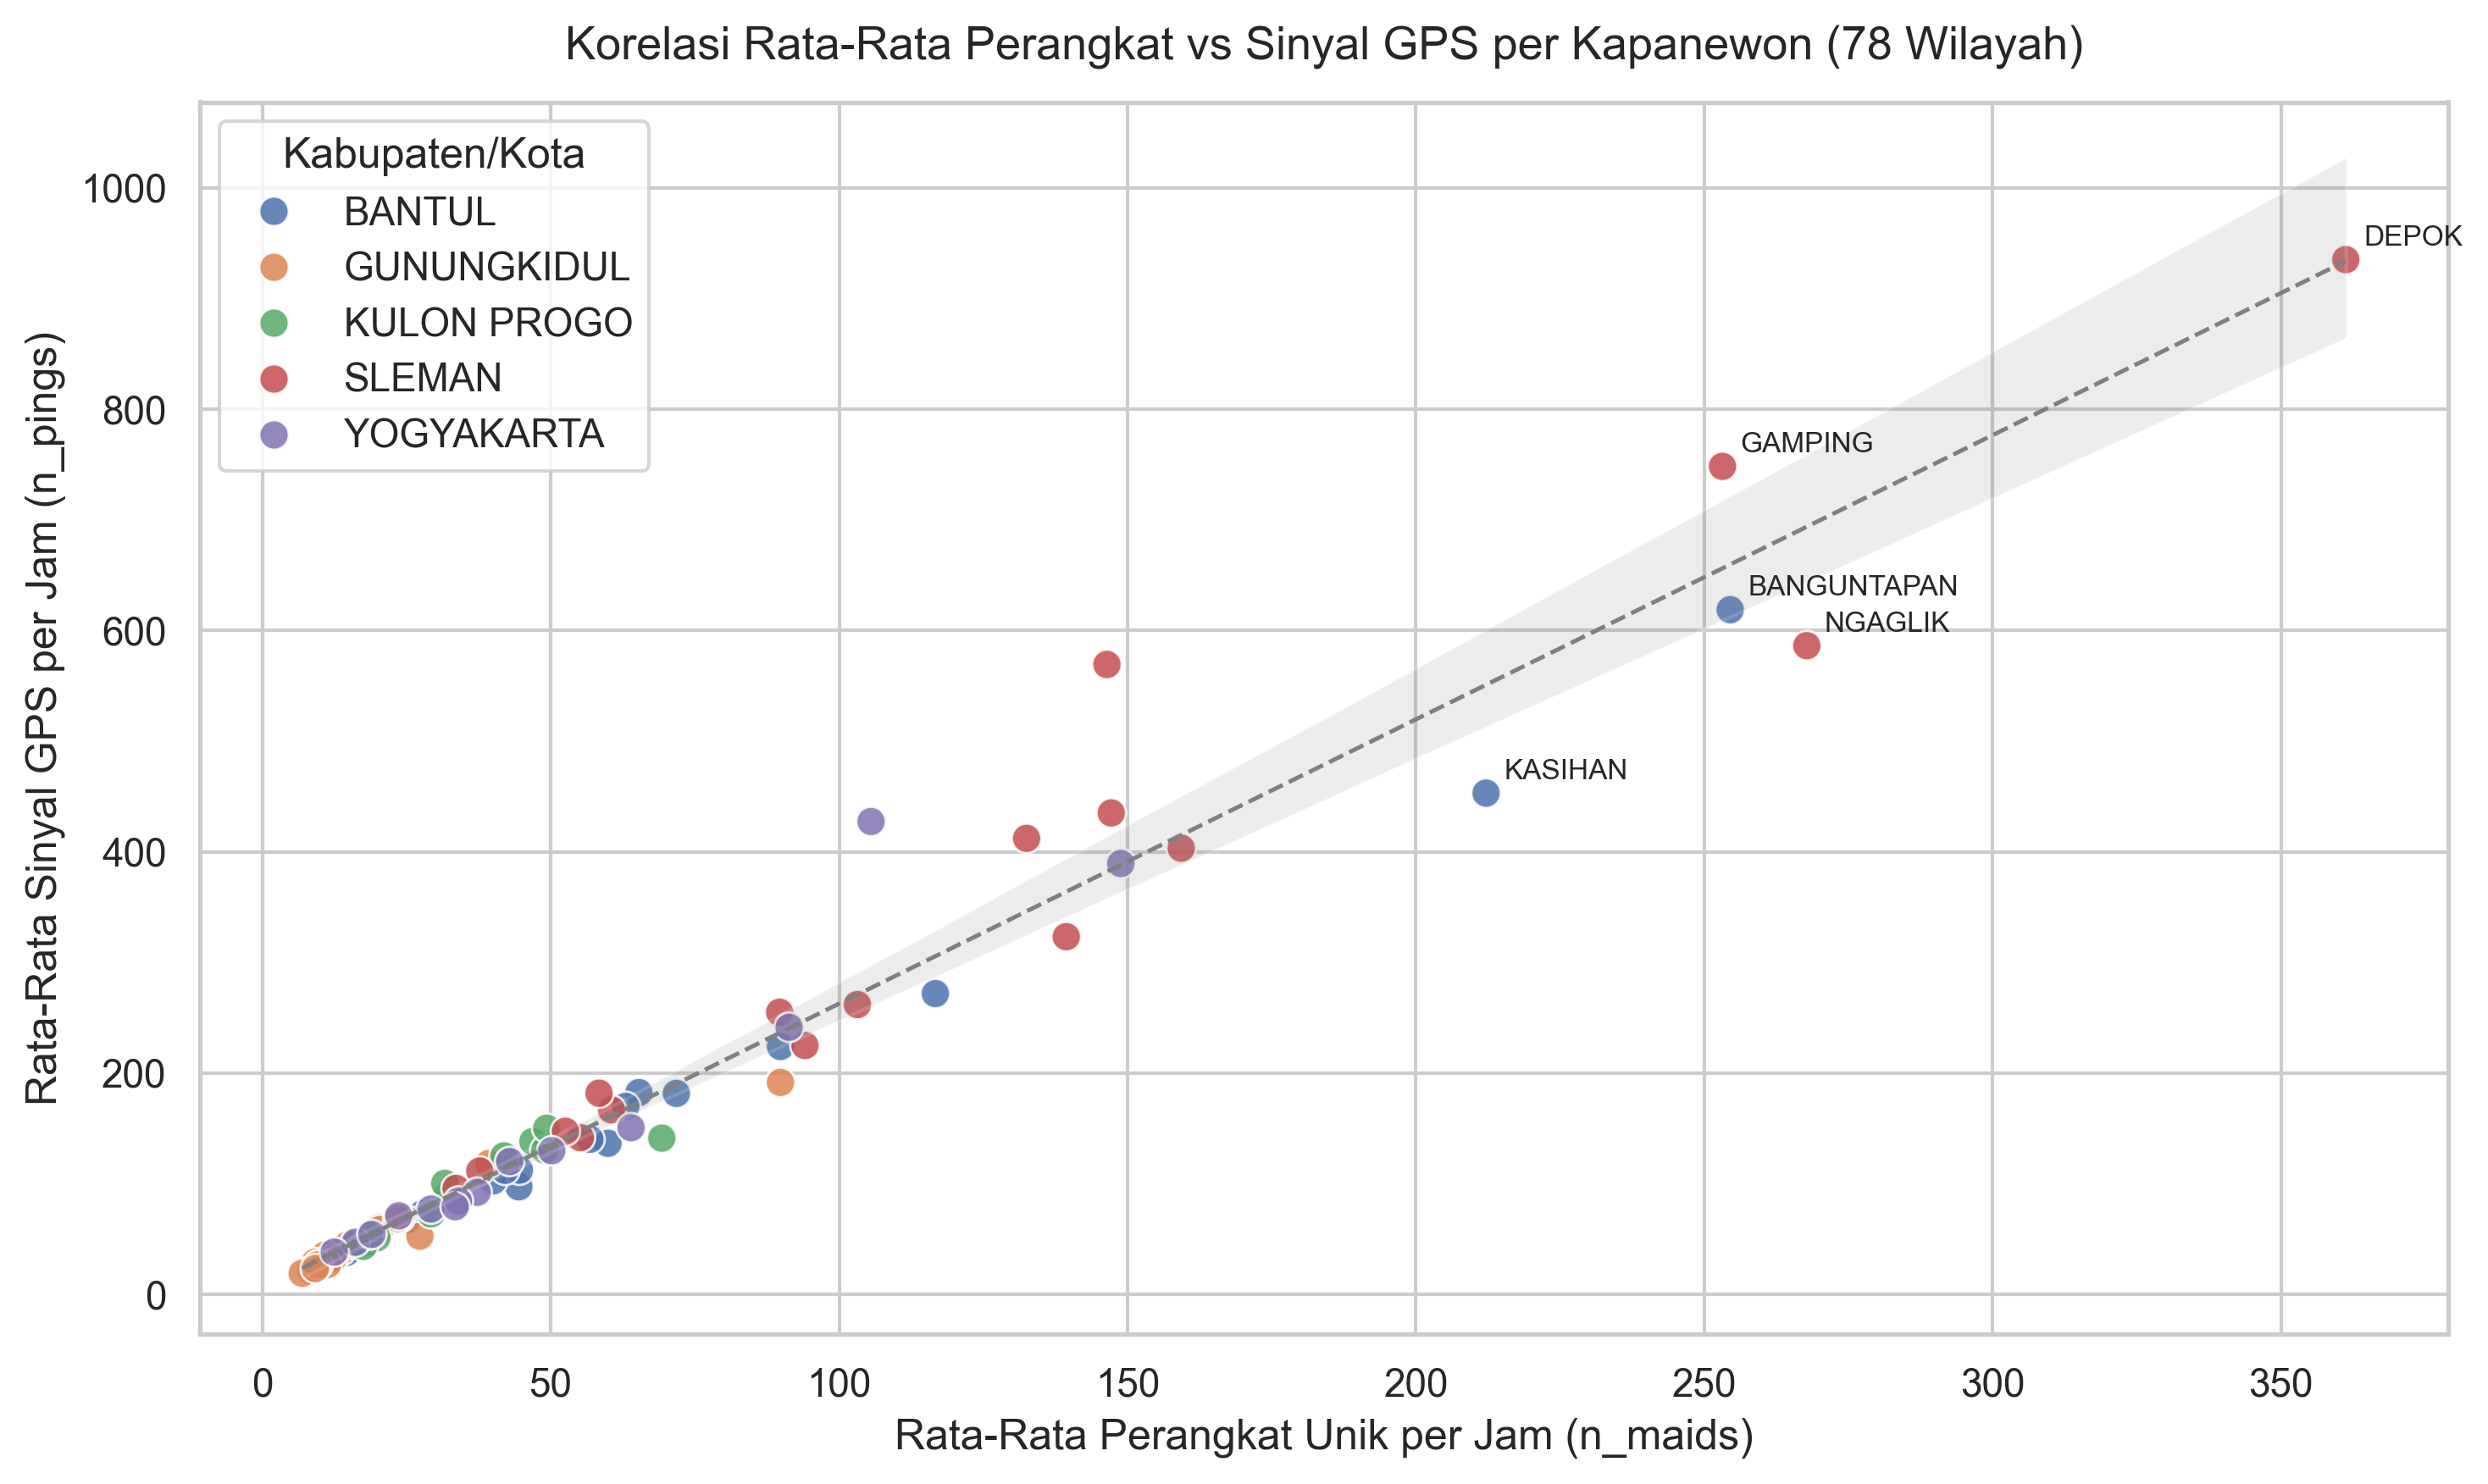

In [10]:
kapanewon_agg = (
    df_presence.groupby(["kab_kota", "kapanewon_code", "kapanewon_label"])[["n_maids", "n_pings"]]
    .mean()
    .reset_index()
)
assert len(kapanewon_agg) == 78

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.scatterplot(
    data=kapanewon_agg,
    x="n_maids",
    y="n_pings",
    hue="kab_kota",
    s=70,
    alpha=0.85,
    ax=ax,
)
sns.regplot(
    data=kapanewon_agg,
    x="n_maids",
    y="n_pings",
    scatter=False,
    color="gray",
    line_kws={"linestyle": "--", "linewidth": 1.2},
    ax=ax,
)

for _, row in kapanewon_agg.nlargest(5, "n_maids").iterrows():
    ax.annotate(
        row["kapanewon_label"],
        (row["n_maids"], row["n_pings"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8,
    )

ax.set_title("Korelasi Rata-Rata Perangkat vs Sinyal GPS per Kapanewon (78 Wilayah)", fontsize=13, pad=12)
ax.set_xlabel("Rata-Rata Perangkat Unik per Jam (n_maids)")
ax.set_ylabel("Rata-Rata Sinyal GPS per Jam (n_pings)")
ax.legend(title="Kabupaten/Kota", frameon=True)
plt.tight_layout()
plt.savefig("figures/04a_scatter_maids_vs_pings.png", dpi=300, bbox_inches="tight")
plt.show()

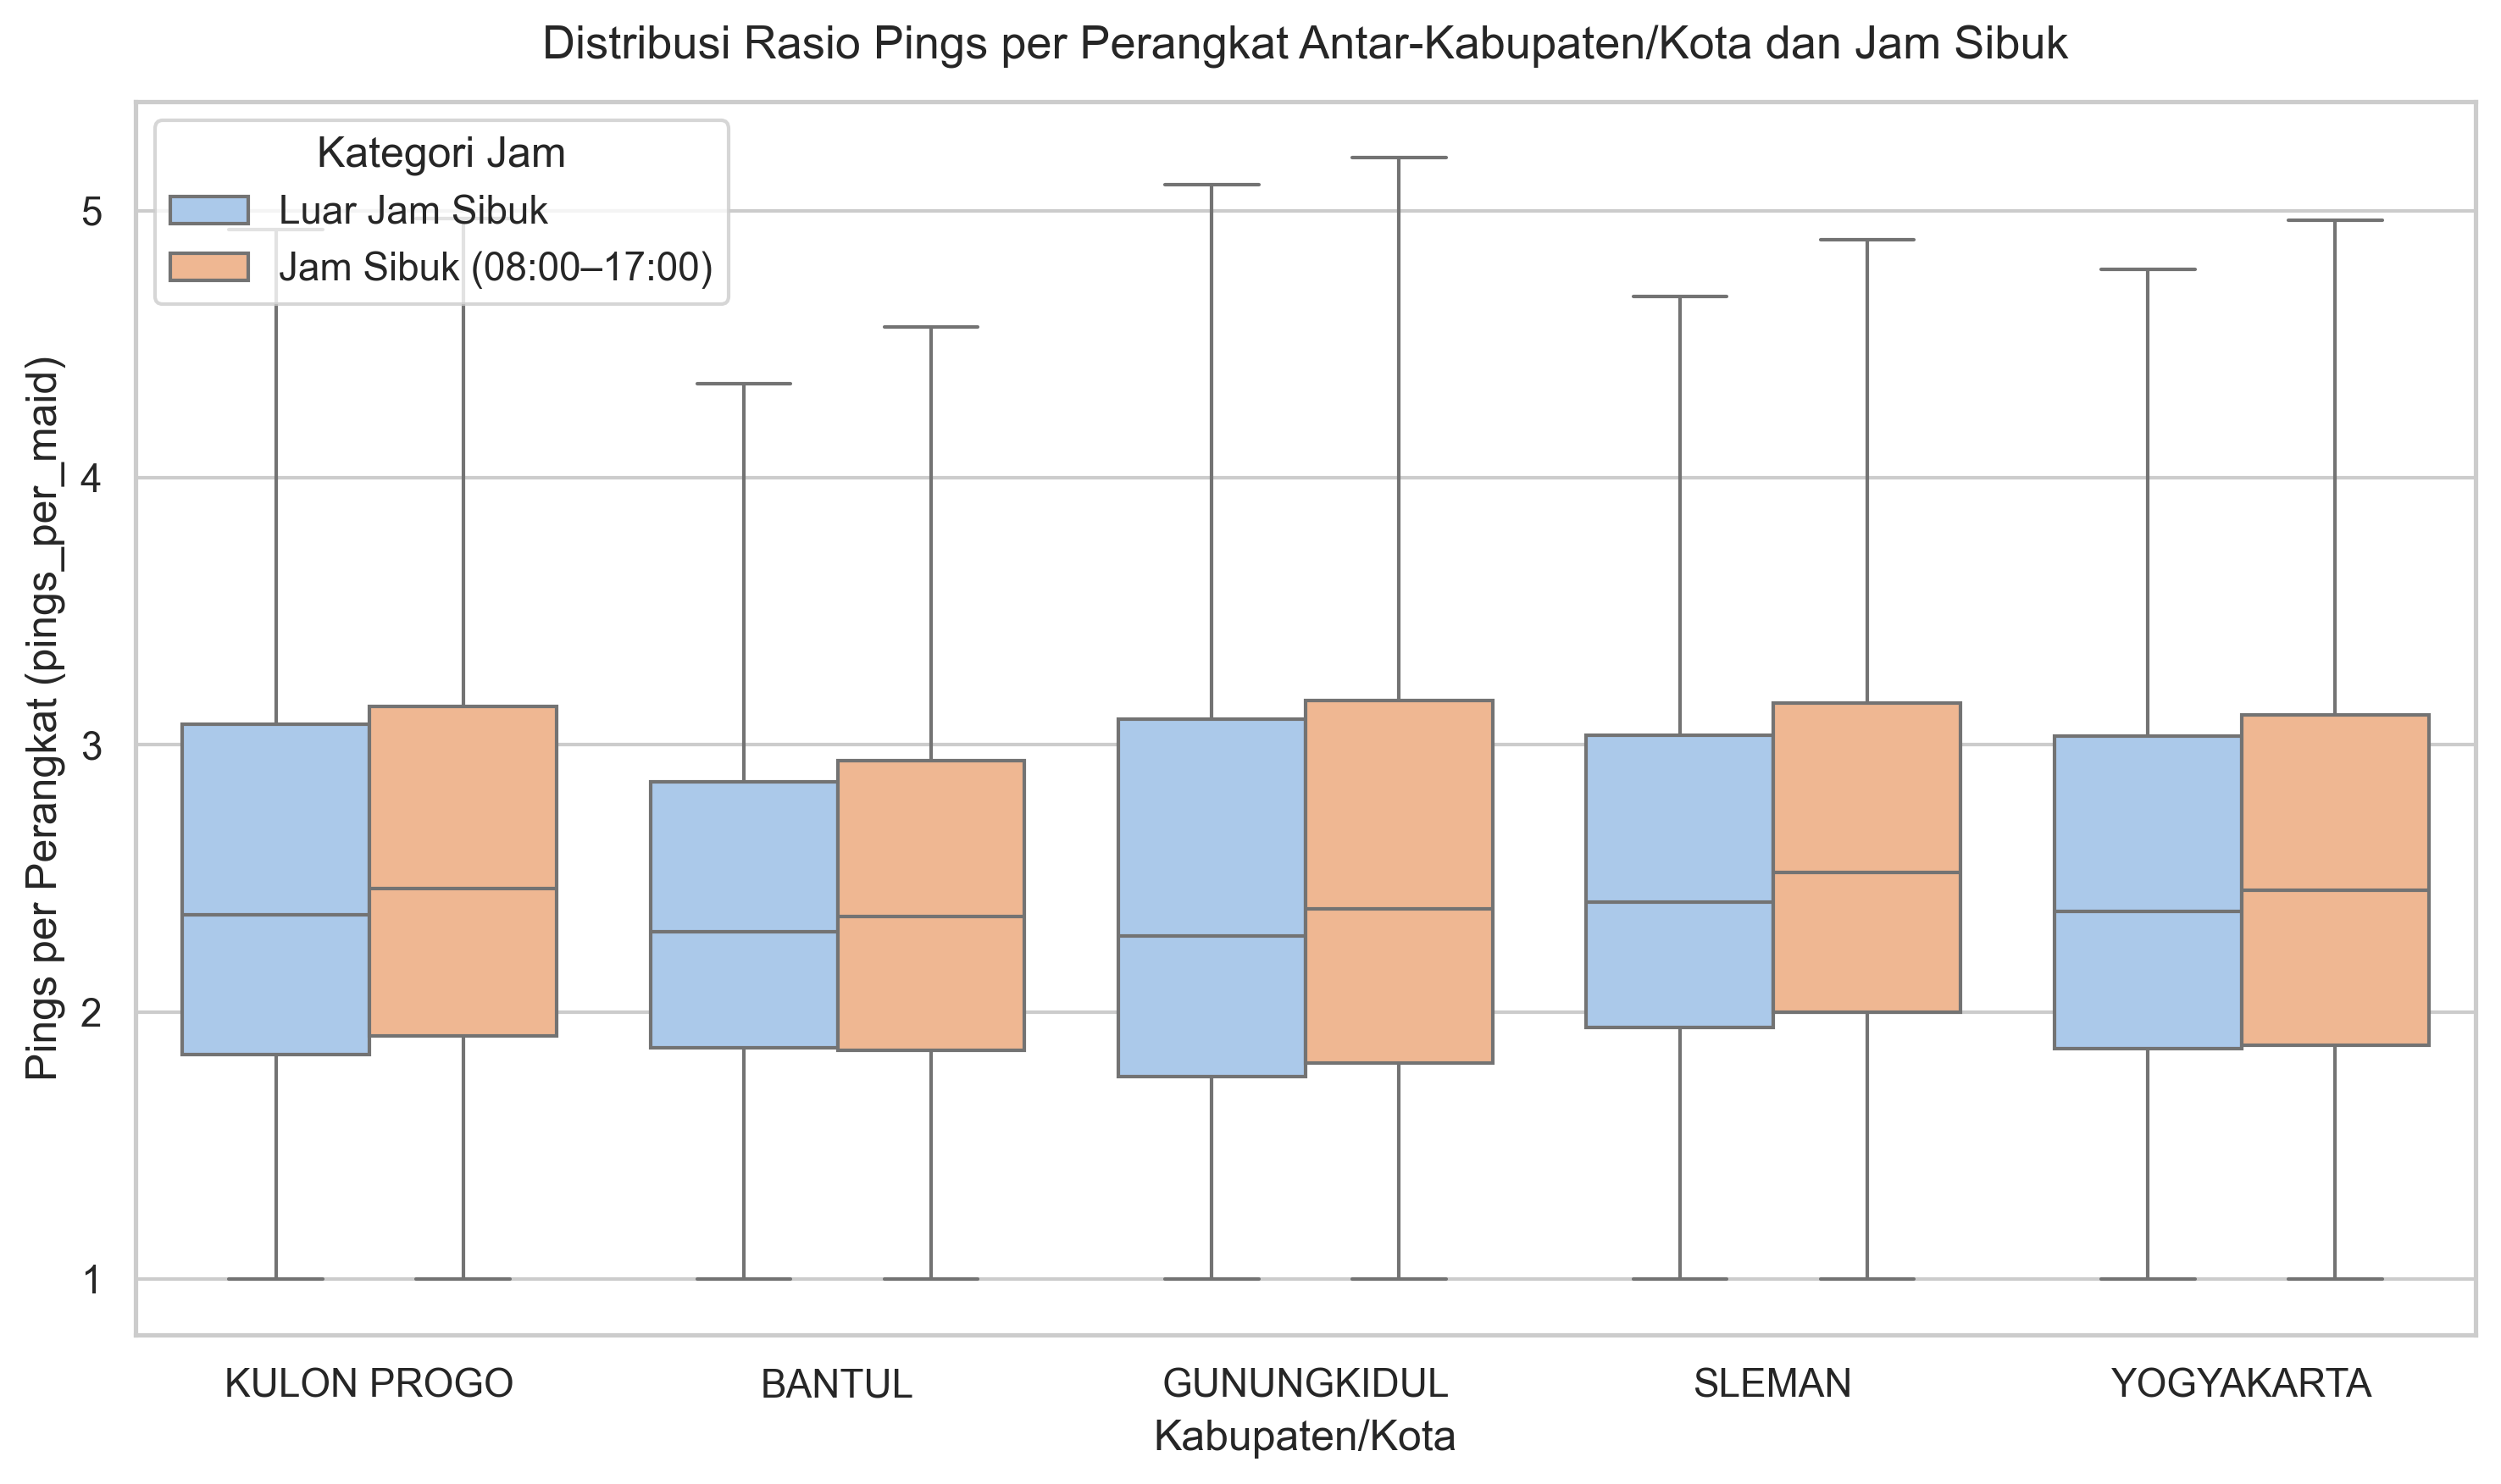

In [11]:
jam_sibuk = df_presence["hour"].between(8, 17)
df_presence["kategori_jam"] = np.where(jam_sibuk, "Jam Sibuk (08:00–17:00)", "Luar Jam Sibuk")

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.boxplot(
    data=df_presence,
    x="kab_kota",
    y="pings_per_maid",
    hue="kategori_jam",
    showfliers=False,
    palette="pastel",
    ax=ax,
)
ax.set_title("Distribusi Rasio Pings per Perangkat Antar-Kabupaten/Kota dan Jam Sibuk", fontsize=13, pad=12)
ax.set_xlabel("Kabupaten/Kota")
ax.set_ylabel("Pings per Perangkat (pings_per_maid)")
ax.legend(title="Kategori Jam", frameon=True)
plt.tight_layout()
plt.savefig("figures/04b_boxplot_pings_per_maid.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Bagian 4:**
- Bila hanya dihitung rata-rata tak-tertimbang (`mean_pings_per_maid`), Gunungkidul (`2,63`) tampak setara dengan Sleman (`2,64`) dan Kota Yogyakarta (`2,65`) karena baris bervolume kecil memiliki bobot sama besar dengan pusat kota. Dengan metrik tertimbang (`weighted_pings_per_maid = total_pings / total_maids`), intensitas sinyal GPS tertinggi berada di **Kota Yogyakarta (`2,84`)** dan **Sleman (`2,73`)**, disusul **Kulon Progo (`2,70`)**, **Gunungkidul (`2,58`)**, dan **Bantul (`2,42`)**.
- Korelasi antara `n_maids` dan `n_pings` di 78 kapanewon bersifat sangat linear, dengan Depok, Ngaglik, Banguntapan, Gamping, dan Kasihan menempati posisi lima besar tertinggi.

## Bagian 5: Matriks Origin-Destination (OD) Makro Antar-Kabupaten/Kota

Mengagregasi `n_maids` berdasarkan kabupaten/kota asal dan tujuan pada **periode utama Desember 2021–Februari 2022**, lalu menampilkan proporsi hitungan OD **intra-kabupaten/kota** vs **lintas kabupaten/kota**. Intra-kabupaten/kota mencakup pasangan dalam kapanewon yang sama maupun berbeda; kategori ini tidak berarti perangkat tidak bergerak.


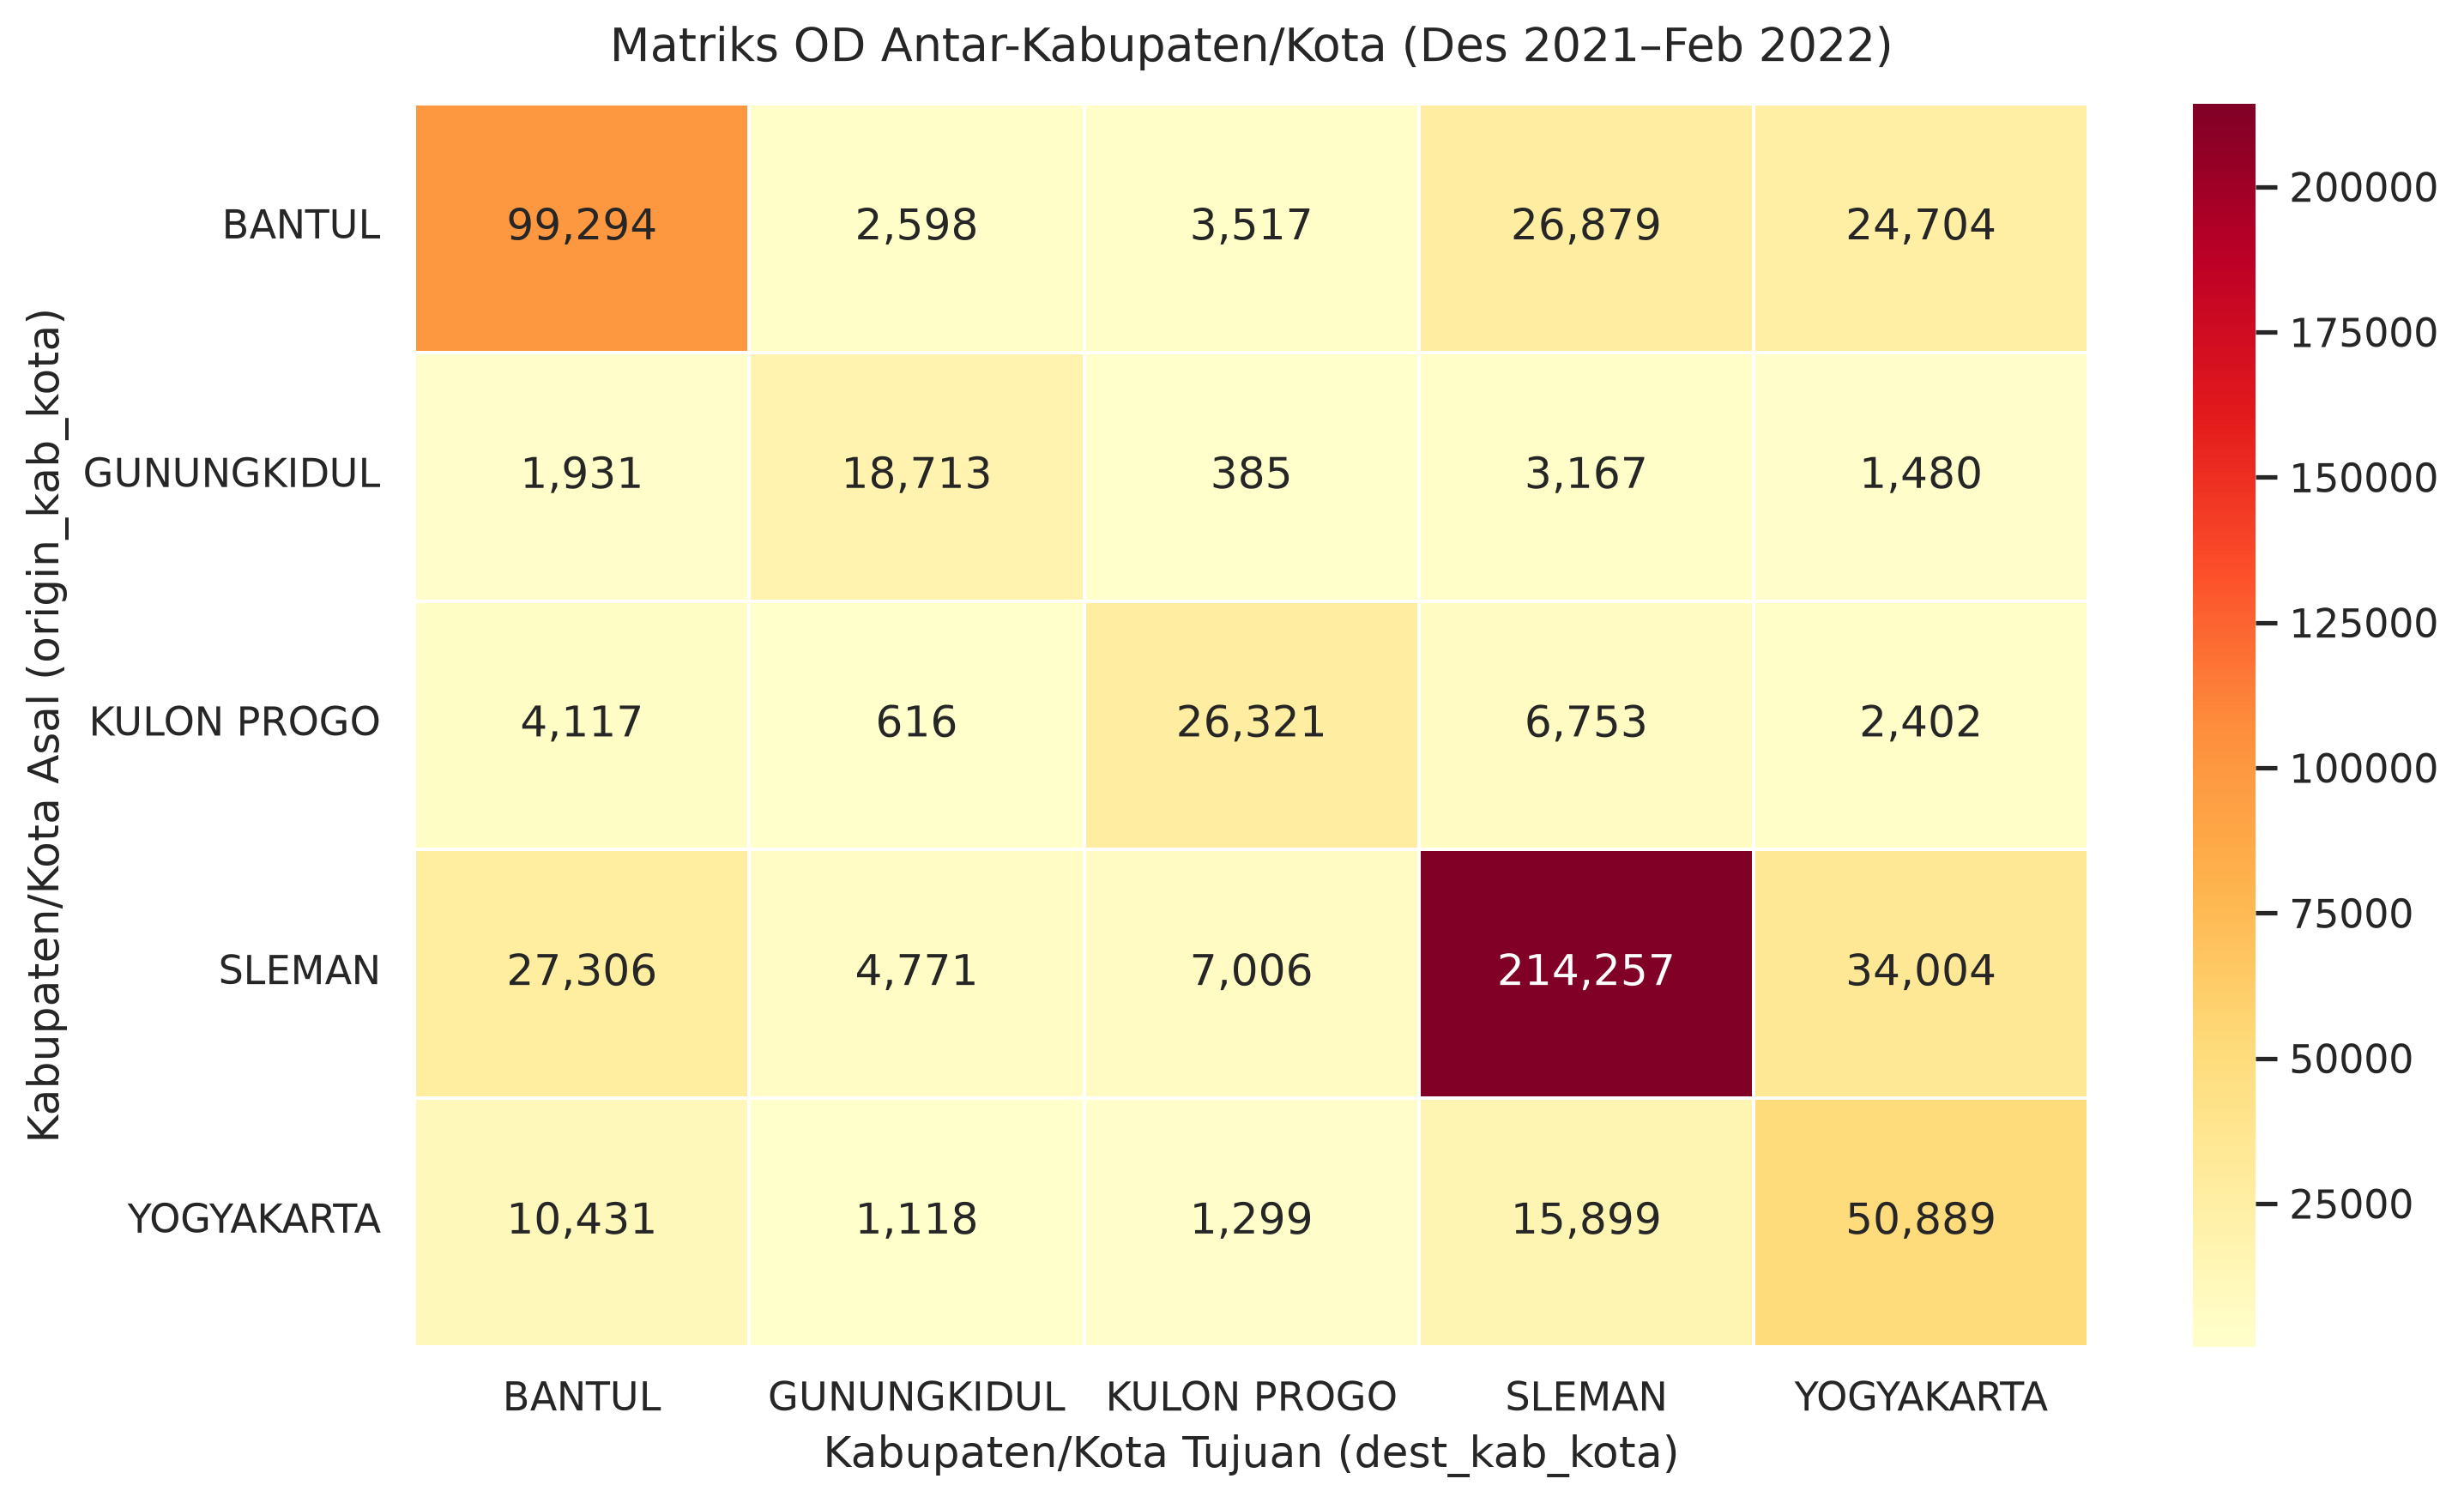

In [12]:
df_od_main = df_od[df_od["month"].isin(["2021-12", "2022-01", "2022-02"])].copy()
assert df_od_main["month"].nunique() == 3
assert not df_od_main["reduced_quality"].any()

od_kab_matrix = (
    df_od_main.groupby(["origin_kab_kota", "dest_kab_kota"])["n_maids"]
    .sum()
    .unstack(fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.heatmap(od_kab_matrix, annot=True, fmt=",.0f", cmap="YlOrRd", linewidths=0.5, ax=ax)
ax.set_title("Matriks OD Antar-Kabupaten/Kota (Des 2021–Feb 2022)", fontsize=13, pad=12)
ax.set_xlabel("Kabupaten/Kota Tujuan (dest_kab_kota)")
ax.set_ylabel("Kabupaten/Kota Asal (origin_kab_kota)")
plt.tight_layout()
plt.savefig("figures/05a_heatmap_od_5x5_kabkota.png", dpi=300, bbox_inches="tight")
plt.show()

Proporsi Hitungan OD Des 2021–Feb 2022 (%):
tipe_pergerakan  Intra-Kabupaten/Kota  Lintas Kabupaten/Kota
origin_kab_kota                                             
BANTUL                           63.2                   36.8
GUNUNGKIDUL                      72.9                   27.1
KULON PROGO                      65.5                   34.5
SLEMAN                           74.6                   25.4
YOGYAKARTA                       63.9                   36.1


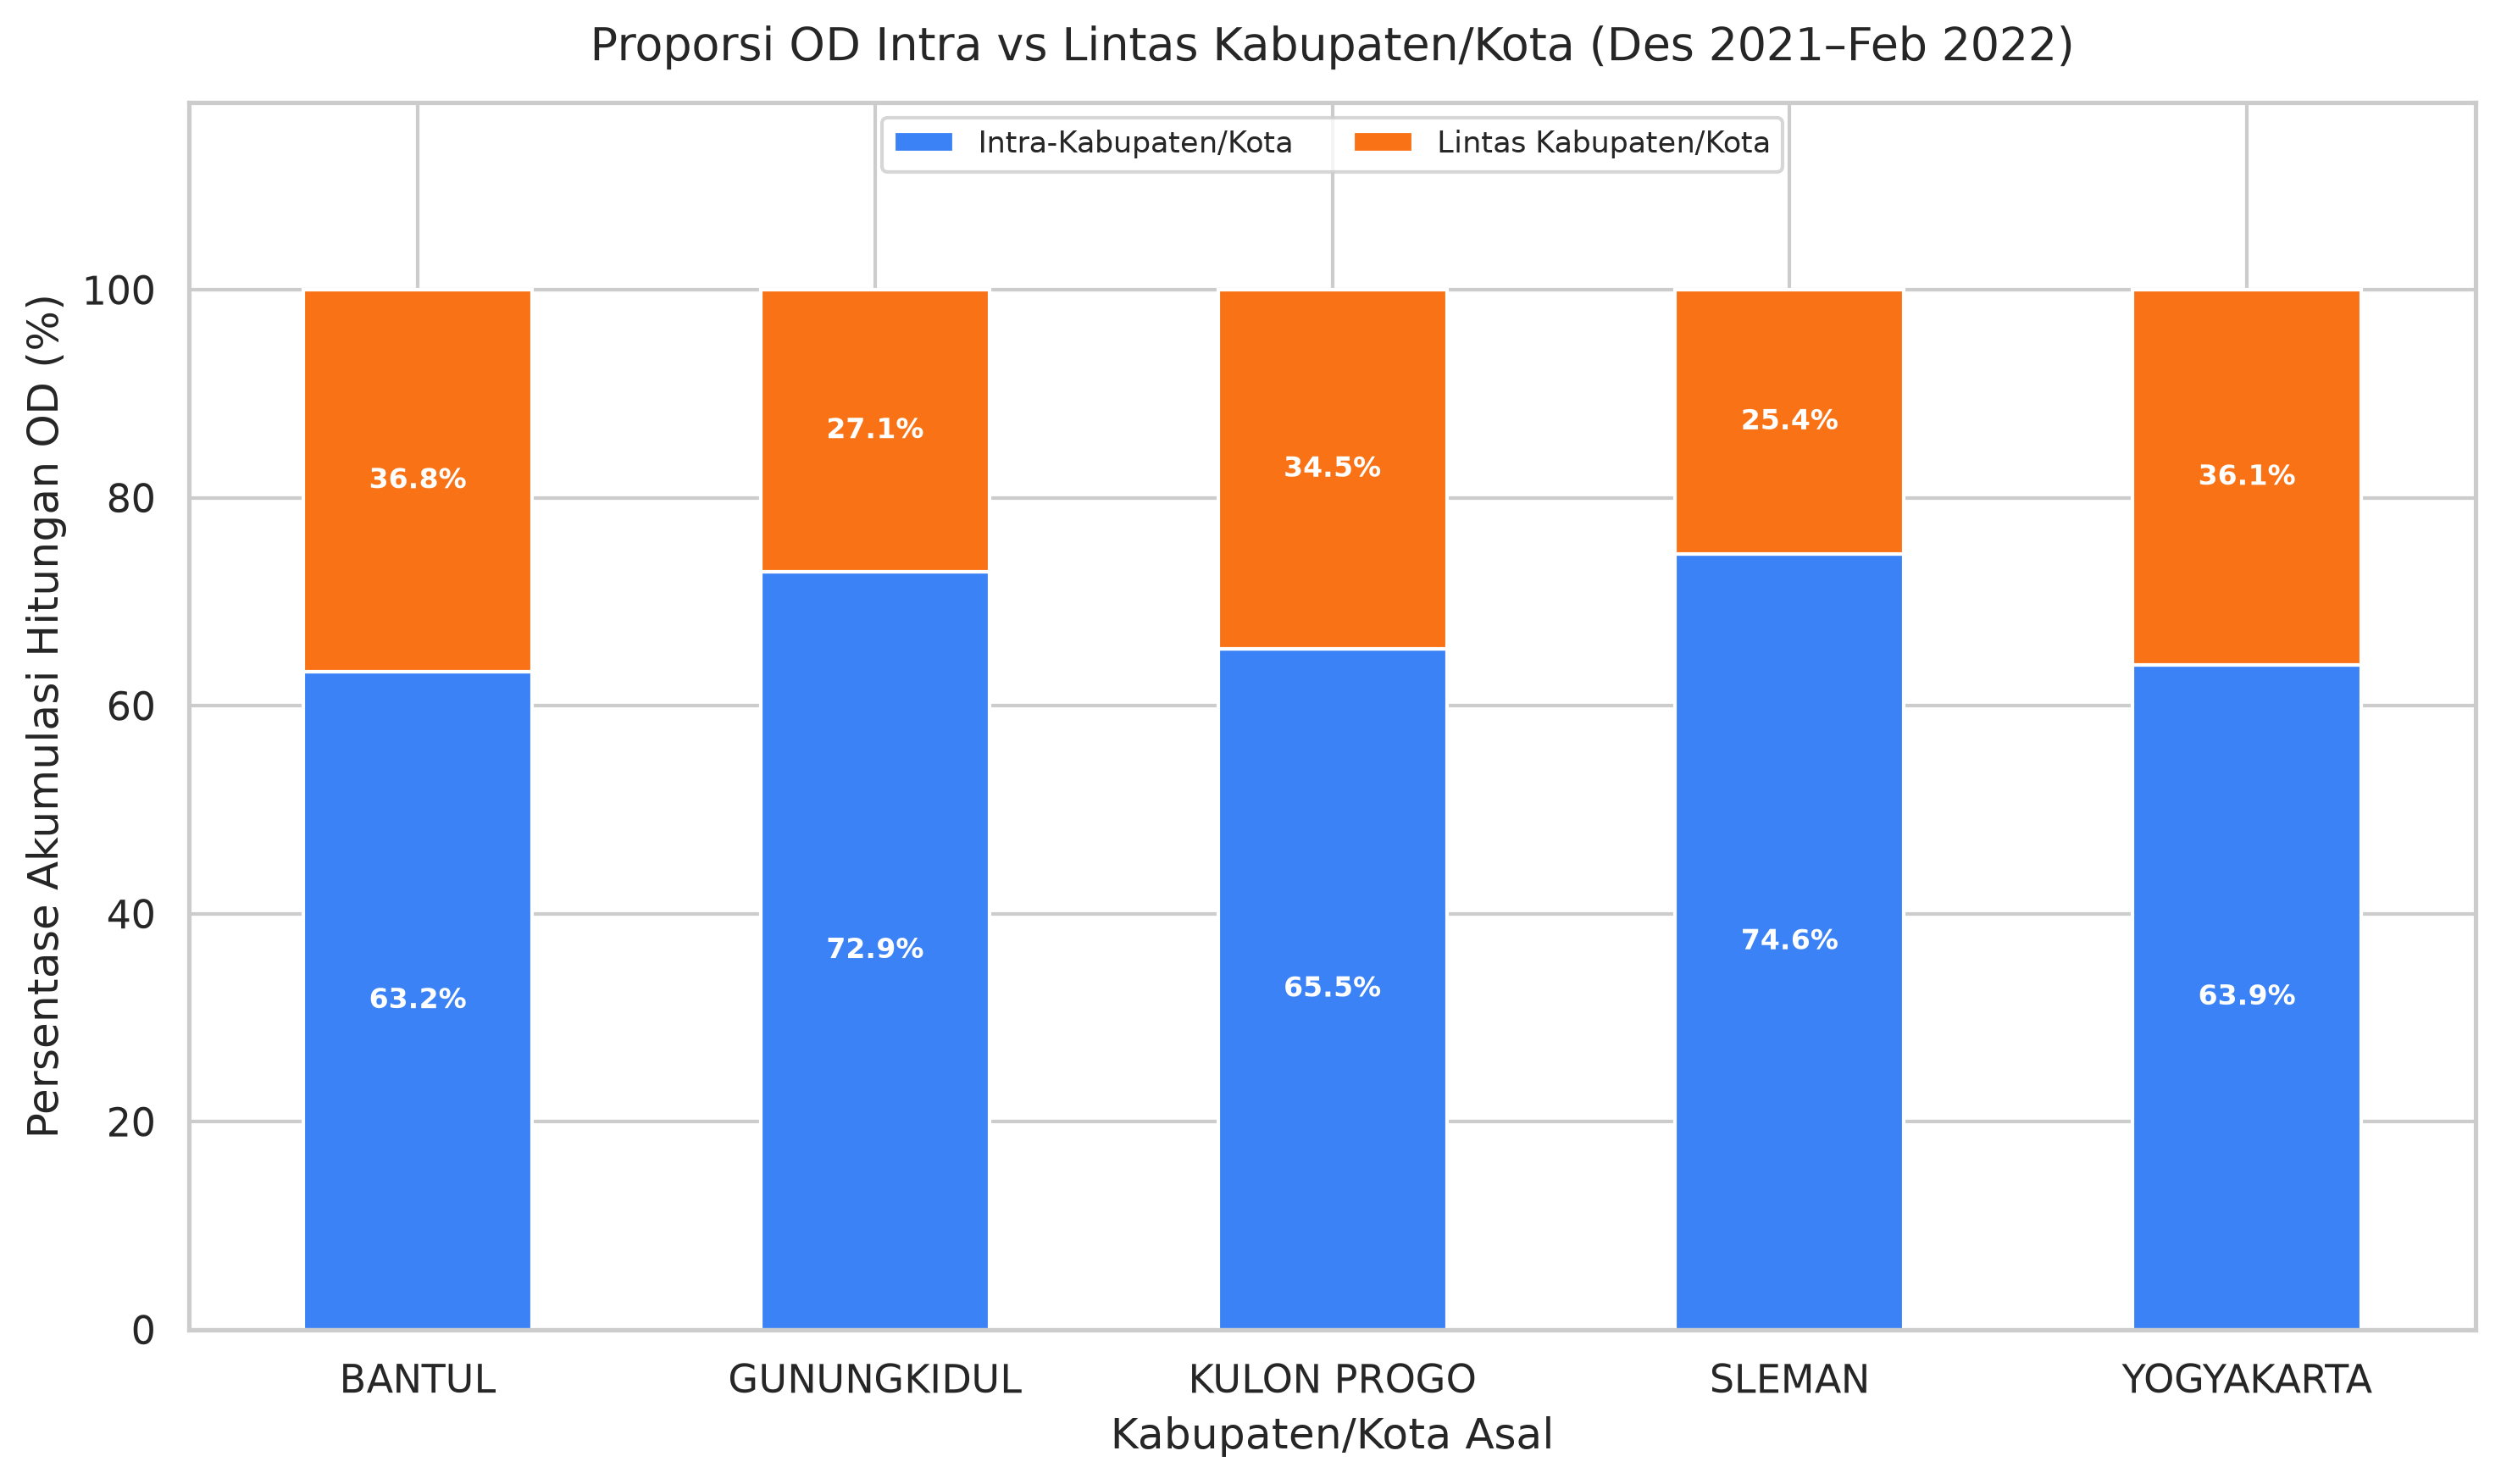

In [13]:
df_od_main["tipe_pergerakan"] = np.where(
    df_od_main["origin_kab_kota"] == df_od_main["dest_kab_kota"],
    "Intra-Kabupaten/Kota",
    "Lintas Kabupaten/Kota",
)
kat_order = ["Intra-Kabupaten/Kota", "Lintas Kabupaten/Kota"]
prop_df = (
    df_od_main.groupby(["origin_kab_kota", "tipe_pergerakan"])["n_maids"]
    .sum()
    .unstack(fill_value=0)[kat_order]
)
prop_pct = prop_df.div(prop_df.sum(axis=1), axis=0) * 100
assert np.allclose(prop_pct.sum(axis=1), 100)
print("Proporsi Hitungan OD Des 2021–Feb 2022 (%):")
print(prop_pct.round(1))

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
prop_pct.plot(kind="bar", stacked=True, color=["#3b82f6", "#f97316"], ax=ax)
for container in ax.containers:
    labels = [f"{v:.1f}%" if v >= 8 else "" for v in container.datavalues]
    ax.bar_label(container, labels=labels, label_type="center", fontsize=8, color="white", fontweight="bold")

ax.set_title("Proporsi OD Intra vs Lintas Kabupaten/Kota (Des 2021–Feb 2022)", fontsize=13, pad=12)
ax.set_xlabel("Kabupaten/Kota Asal")
ax.set_ylabel("Persentase Akumulasi Hitungan OD (%)")
ax.set_ylim(0, 118)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.tick_params(axis="x", rotation=0)
ax.legend(title="", loc="upper center", ncol=2, frameon=True, fontsize=8.5)
plt.tight_layout()
plt.savefig("figures/05b_proporsi_intra_vs_inter_kabkota.png", dpi=300, bbox_inches="tight")
plt.show()


**Insight Bagian 5:**
- Hitungan OD intra-kabupaten/kota mendominasi pada kelima wilayah asal: **Sleman 74,6%**, **Gunungkidul 72,9%**, **Kulon Progo 65,5%**, **Kota Yogyakarta 63,9%**, dan **Bantul 63,2%**. Ini mencakup pasangan dalam kapanewon yang sama.
- Proporsi dihitung dari akumulasi hitungan OD Desember 2021–Februari 2022, termasuk pasangan dalam kapanewon yang sama.
- Proporsi intra-kabupaten/kota mengukur lokasi asal dan tujuan yang berada dalam kabupaten/kota yang sama; tidak menunjukkan perangkat diam atau tidak melakukan perjalanan.


## Bagian 6: Analisis Pasangan OD Mikro Lintas-Kapanewon

Memfilter pasangan lintas-kapanewon (`origin_code != dest_code`) pada **periode utama Desember 2021–Februari 2022**, dengan label wilayah terdisambiguasi. Periode yang sama digunakan untuk **Top 20 pasangan OD (6A)** dan **Top 10 wilayah asal serta tujuan (6B)**. Grafik menggunakan akumulasi hitungan perangkat-bulanan, bukan jumlah perjalanan atau perangkat unik sepanjang periode.


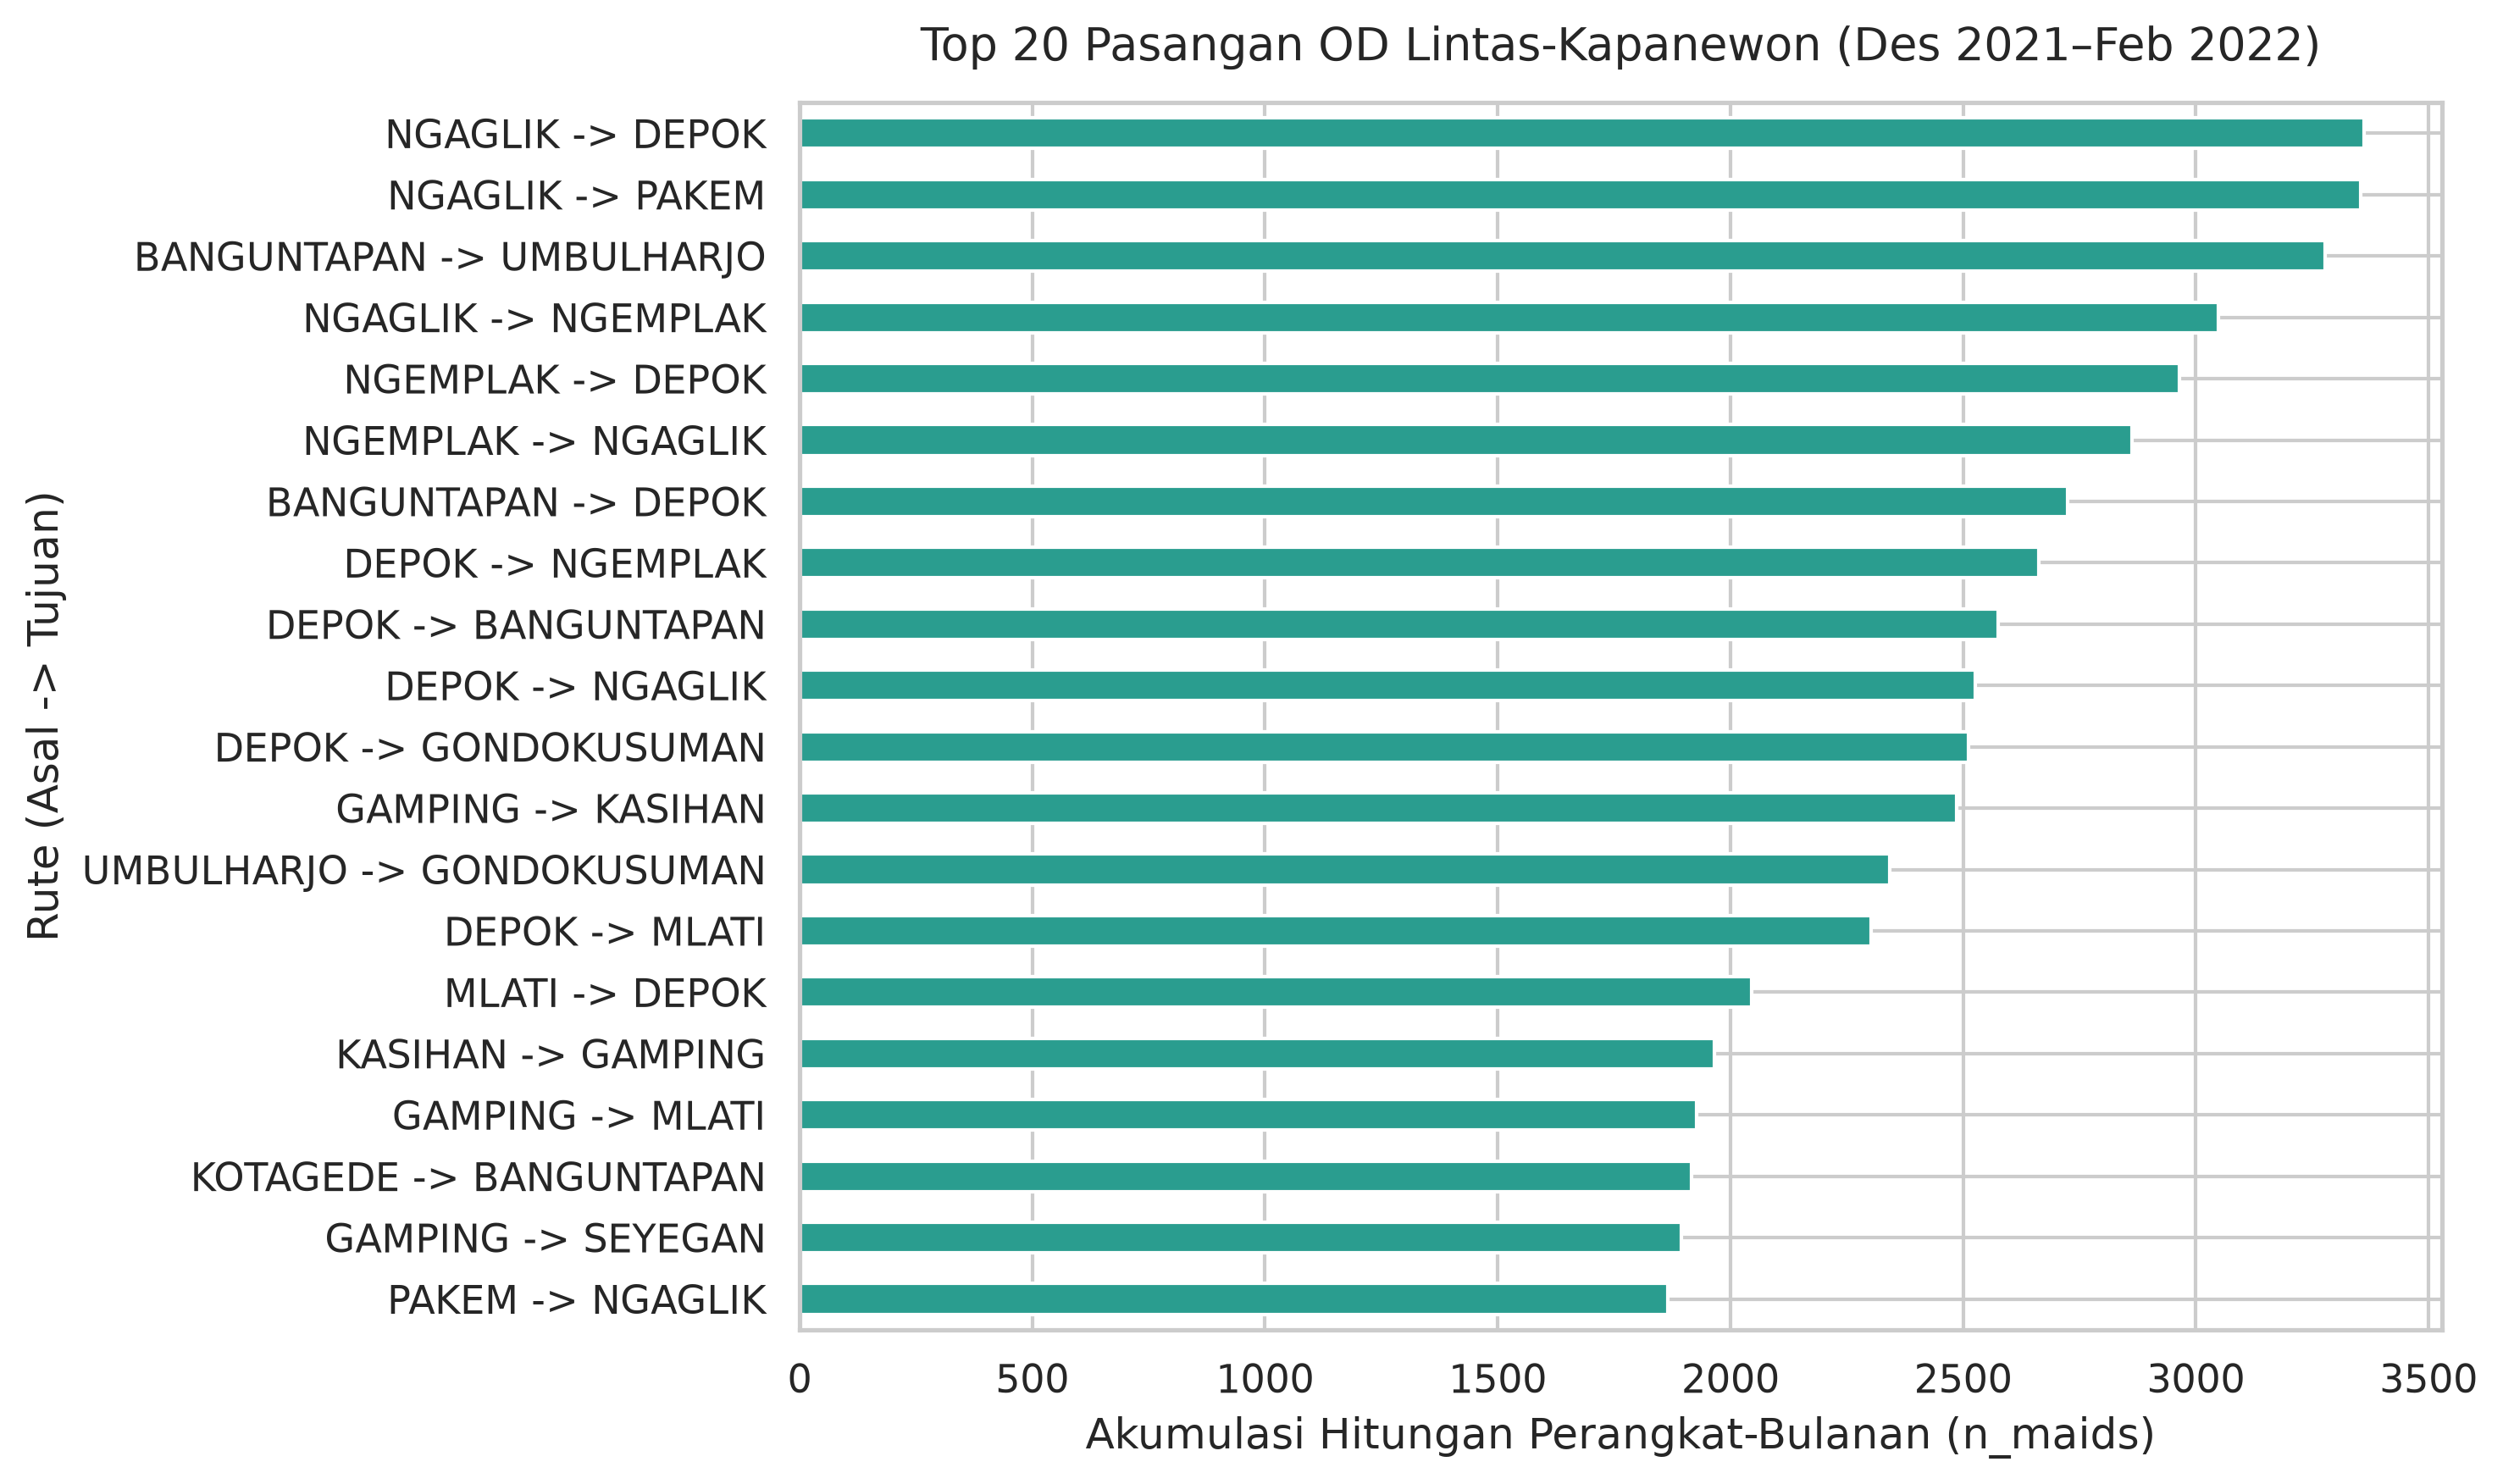

In [14]:
df_od_lintas = df_od_main[df_od_main["origin_code"] != df_od_main["dest_code"]].copy()
df_od_lintas["rute"] = (
    df_od_lintas["origin_kapanewon_label"] + " -> " + df_od_lintas["dest_kapanewon_label"]
)
top20_rute = (
    df_od_lintas.groupby("rute")["n_maids"]
    .sum()
    .nlargest(20)
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
top20_rute.plot(kind="barh", color="#2a9d8f", ax=ax)
ax.set_title("Top 20 Pasangan OD Lintas-Kapanewon (Des 2021–Feb 2022)", fontsize=13, pad=12)
ax.set_xlabel("Akumulasi Hitungan Perangkat-Bulanan (n_maids)")
ax.set_ylabel("Rute (Asal -> Tujuan)")
plt.tight_layout()
plt.savefig("figures/06a_top20_rute_lintas_kapanewon.png", dpi=300, bbox_inches="tight")
plt.show()

Top 10 Penerima Kunjungan (Terdisambiguasi):
dest_kapanewon_label
DEPOK           27529
BANGUNTAPAN     18306
NGAGLIK         17813
GAMPING         16437
UMBULHARJO      14807
GONDOKUSUMAN    14801
MLATI           14707
KASIHAN         13939
PAKEM           12762
NGEMPLAK        11612
Name: n_maids, dtype: int64


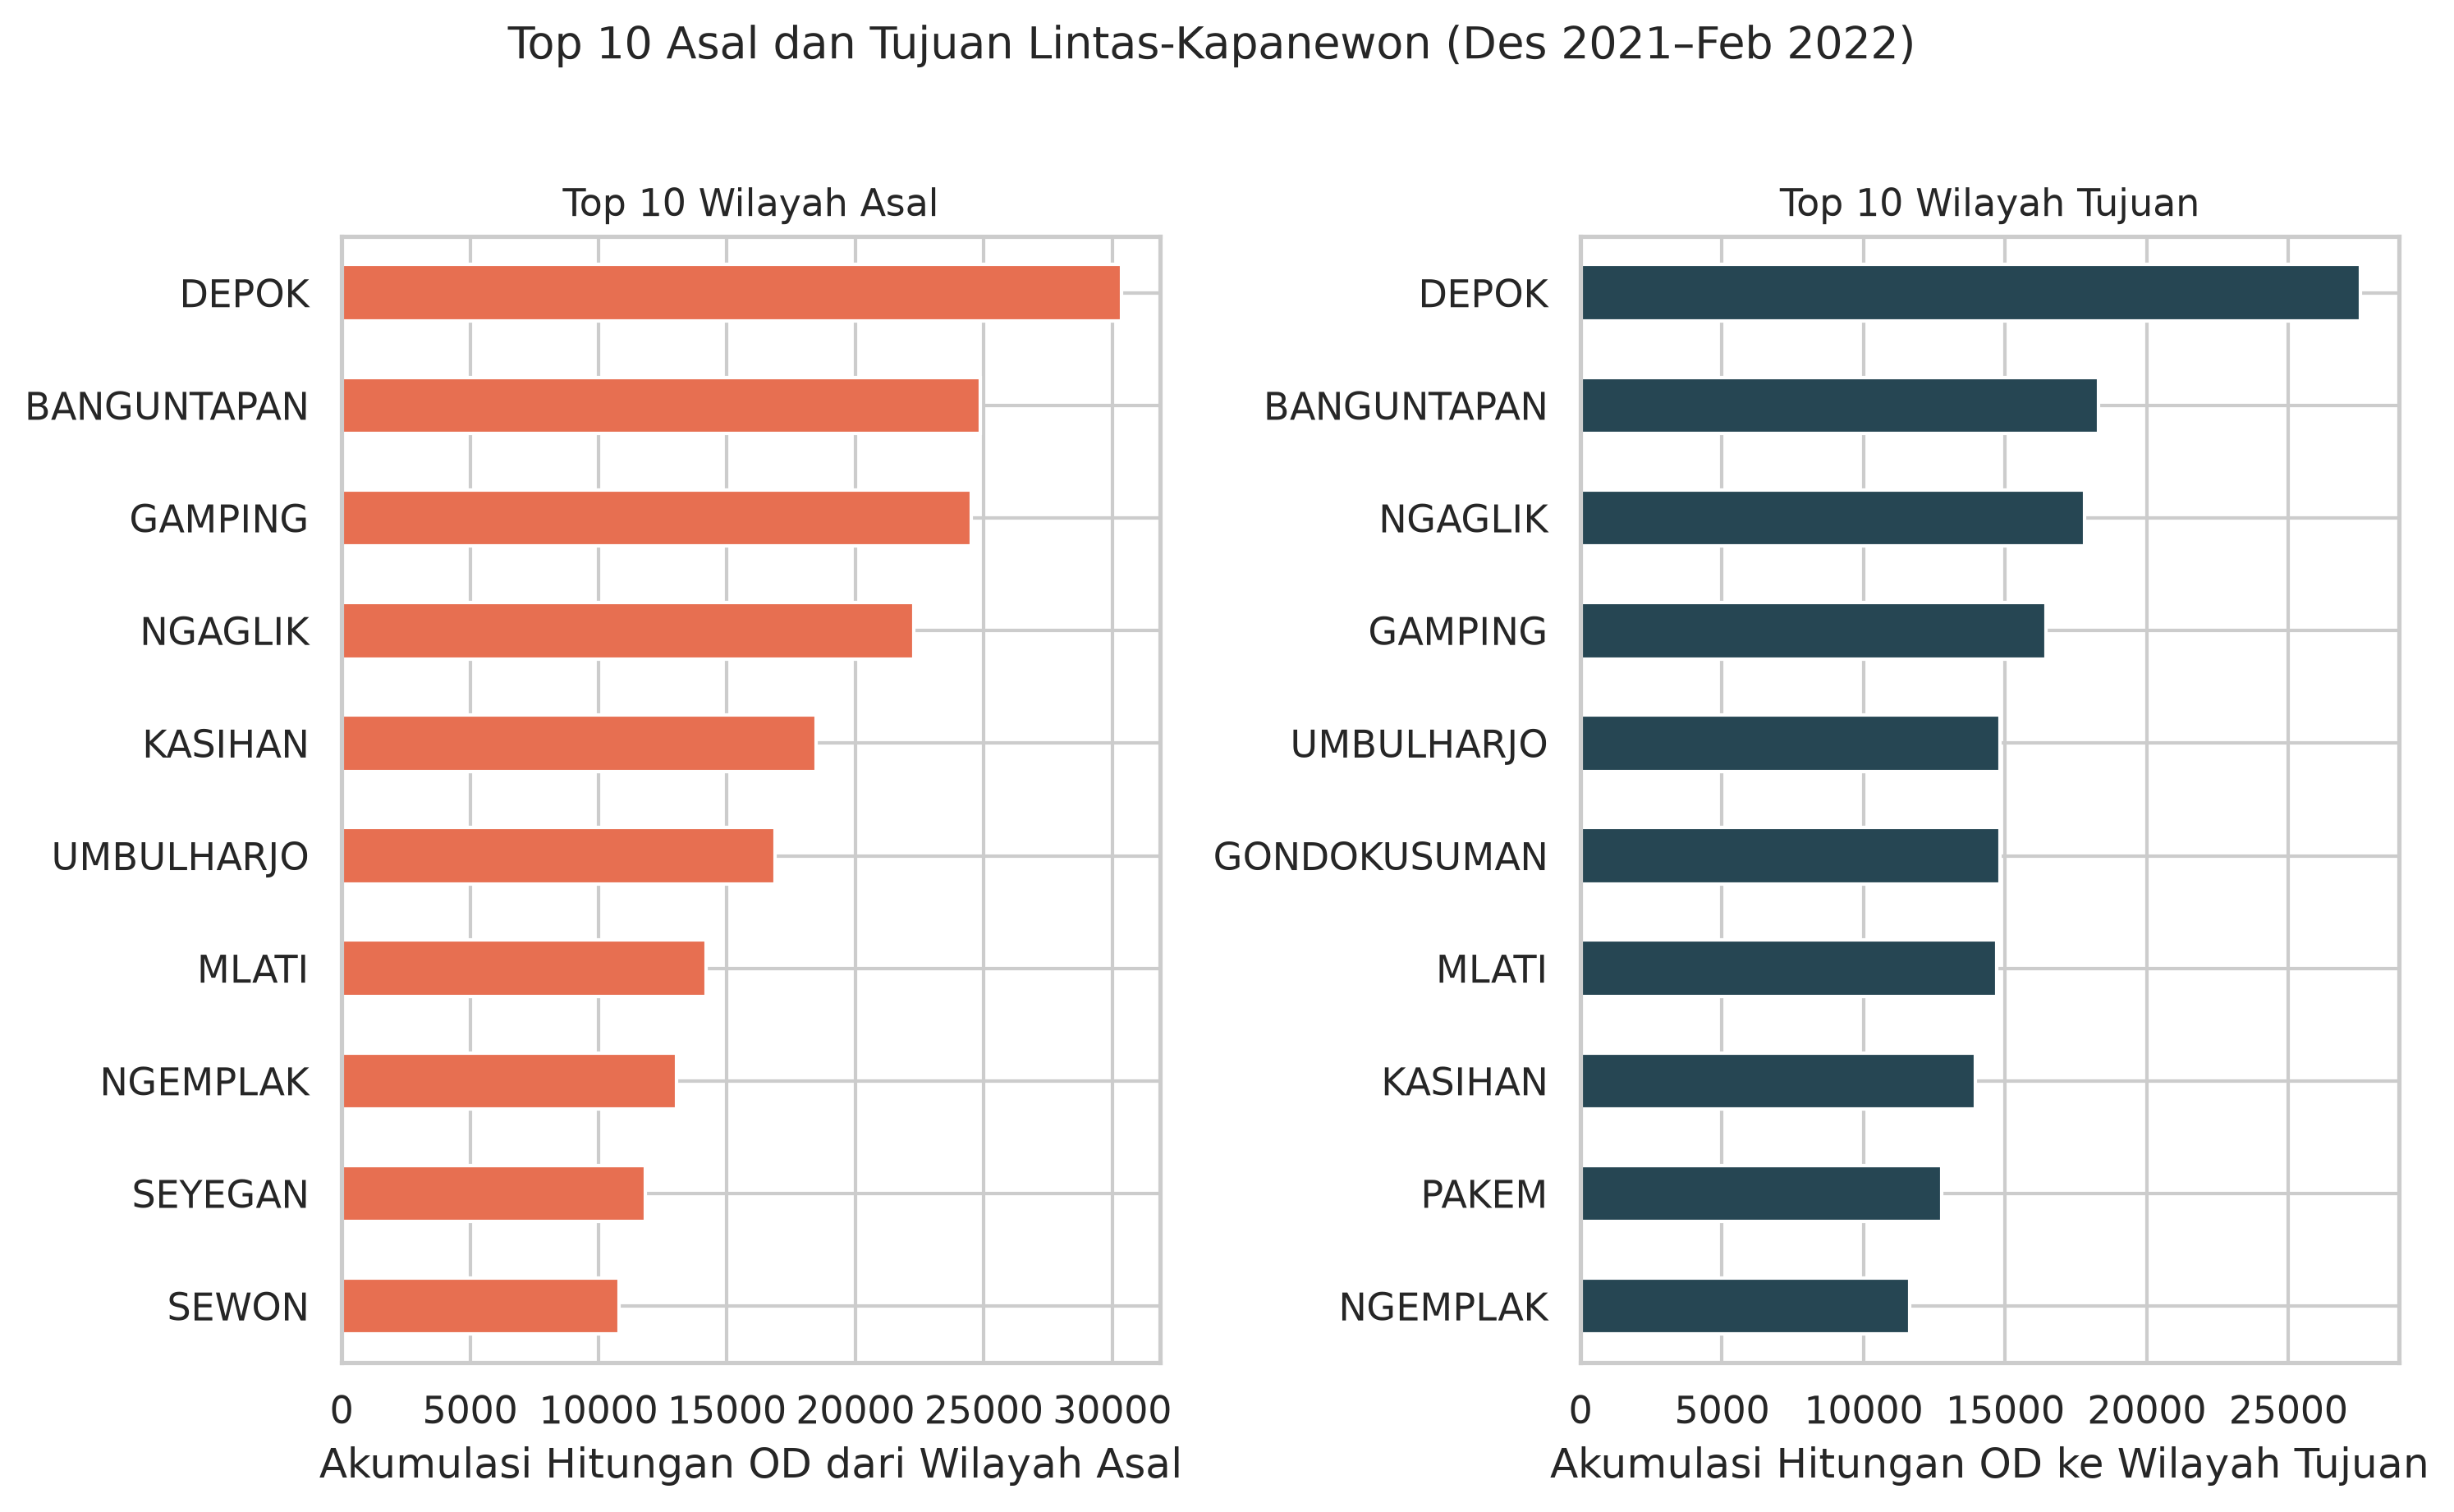

In [15]:
top10_pengirim = (
    df_od_lintas.groupby("origin_kapanewon_label")["n_maids"]
    .sum()
    .nlargest(10)
    .sort_values()
)
top10_penerima = (
    df_od_lintas.groupby("dest_kapanewon_label")["n_maids"]
    .sum()
    .nlargest(10)
    .sort_values()
)
print("Top 10 Penerima Kunjungan (Terdisambiguasi):")
print(top10_penerima.sort_values(ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 6), dpi=300)
top10_pengirim.plot(kind="barh", color="#e76f51", ax=axes[0])
axes[0].set_title("Top 10 Wilayah Asal", fontsize=11)
axes[0].set_xlabel("Akumulasi Hitungan OD dari Wilayah Asal")
axes[0].set_ylabel("")

top10_penerima.plot(kind="barh", color="#264653", ax=axes[1])
axes[1].set_title("Top 10 Wilayah Tujuan", fontsize=11)
axes[1].set_xlabel("Akumulasi Hitungan OD ke Wilayah Tujuan")
axes[1].set_ylabel("")

fig.suptitle("Top 10 Asal dan Tujuan Lintas-Kapanewon (Des 2021–Feb 2022)", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig("figures/06b_top10_pengirim_vs_penerima.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Bagian 6:**
- Pada Desember 2021–Februari 2022, tiga pasangan OD teratas adalah **Ngaglik → Depok (3.361)**, **Ngaglik → Pakem (3.354)**, dan **Banguntapan → Umbulharjo (3.278)** hitungan perangkat-bulanan.
- Setelah kedua Jetis dipisahkan, keduanya tidak masuk Top 10 wilayah tujuan. **Ngemplak** menempati peringkat ke-10 dengan **11.612** hitungan perangkat-bulanan.
- Satu perangkat dapat tercatat pada beberapa tujuan dalam satu bulan. Total sisi asal tidak boleh dianggap jumlah perangkat unik atau dikurangkan dengan sisi tujuan untuk menyatakan arus bersih.


## Bagian 7: Pemodelan Jaringan Graf (Network Centrality) 78 Kapanewon

Membangun graf berarah berbobot dari seluruh pasangan OD lintas-kapanewon yang terpublikasi pada **Desember 2021–Februari 2022**, menggunakan 78 label wilayah terdisambiguasi tanpa self-loop. Weighted In-Degree, Weighted Out-Degree, dan PageRank dihitung pada graf lengkap. Grafik 7A menampilkan 15 koridor utama dengan ukuran simpul berdasarkan PageRank graf lengkap yang sama; grafik 7B menampilkan 15 wilayah dengan PageRank tertinggi.


In [16]:
edge_agg = (
    df_od_lintas.groupby(["origin_kapanewon_label", "dest_kapanewon_label"])["n_maids"]
    .sum()
    .reset_index()
)

G = nx.DiGraph()
for _, row in edge_agg.iterrows():
    G.add_edge(row["origin_kapanewon_label"], row["dest_kapanewon_label"], weight=row["n_maids"])

assert G.number_of_nodes() == 78, f"Seharusnya 78 simpul, terbaca {G.number_of_nodes()}"
assert nx.number_of_selfloops(G) == 0, "Masih terdapat self-loop pada graf!"

in_deg = dict(G.in_degree(weight="weight"))
out_deg = dict(G.out_degree(weight="weight"))
pagerank = nx.pagerank(G, weight="weight")

centrality_df = pd.DataFrame({
    "kapanewon": list(G.nodes()),
    "weighted_in_degree": [in_deg[n] for n in G.nodes()],
    "weighted_out_degree": [out_deg[n] for n in G.nodes()],
    "pagerank": [pagerank[n] for n in G.nodes()],
}).sort_values("pagerank", ascending=False).reset_index(drop=True)

print(f"Total simpul graf: {G.number_of_nodes()} | Total sisi: {G.number_of_edges()} | Self-loops: {nx.number_of_selfloops(G)}")
centrality_df.head(15)

Total simpul graf: 78 | Total sisi: 3228 | Self-loops: 0


,kapanewon,weighted_in_degree,weighted_out_degree,pagerank
0,DEPOK,27529,30347,0.065340
1,BANGUNTAPAN,18306,24872,0.046128
2,NGAGLIK,17813,22271,0.041569
3,UMBULHARJO,14807,16866,0.039231
4,GAMPING,16437,24498,0.038342
5,GONDOKUSUMAN,14801,6760,0.036849
6,KASIHAN,13939,18483,0.035386
7,MLATI,14707,14175,0.033049
8,PAKEM,12762,10057,0.027348
9,NGEMPLAK,11612,13039,0.025414


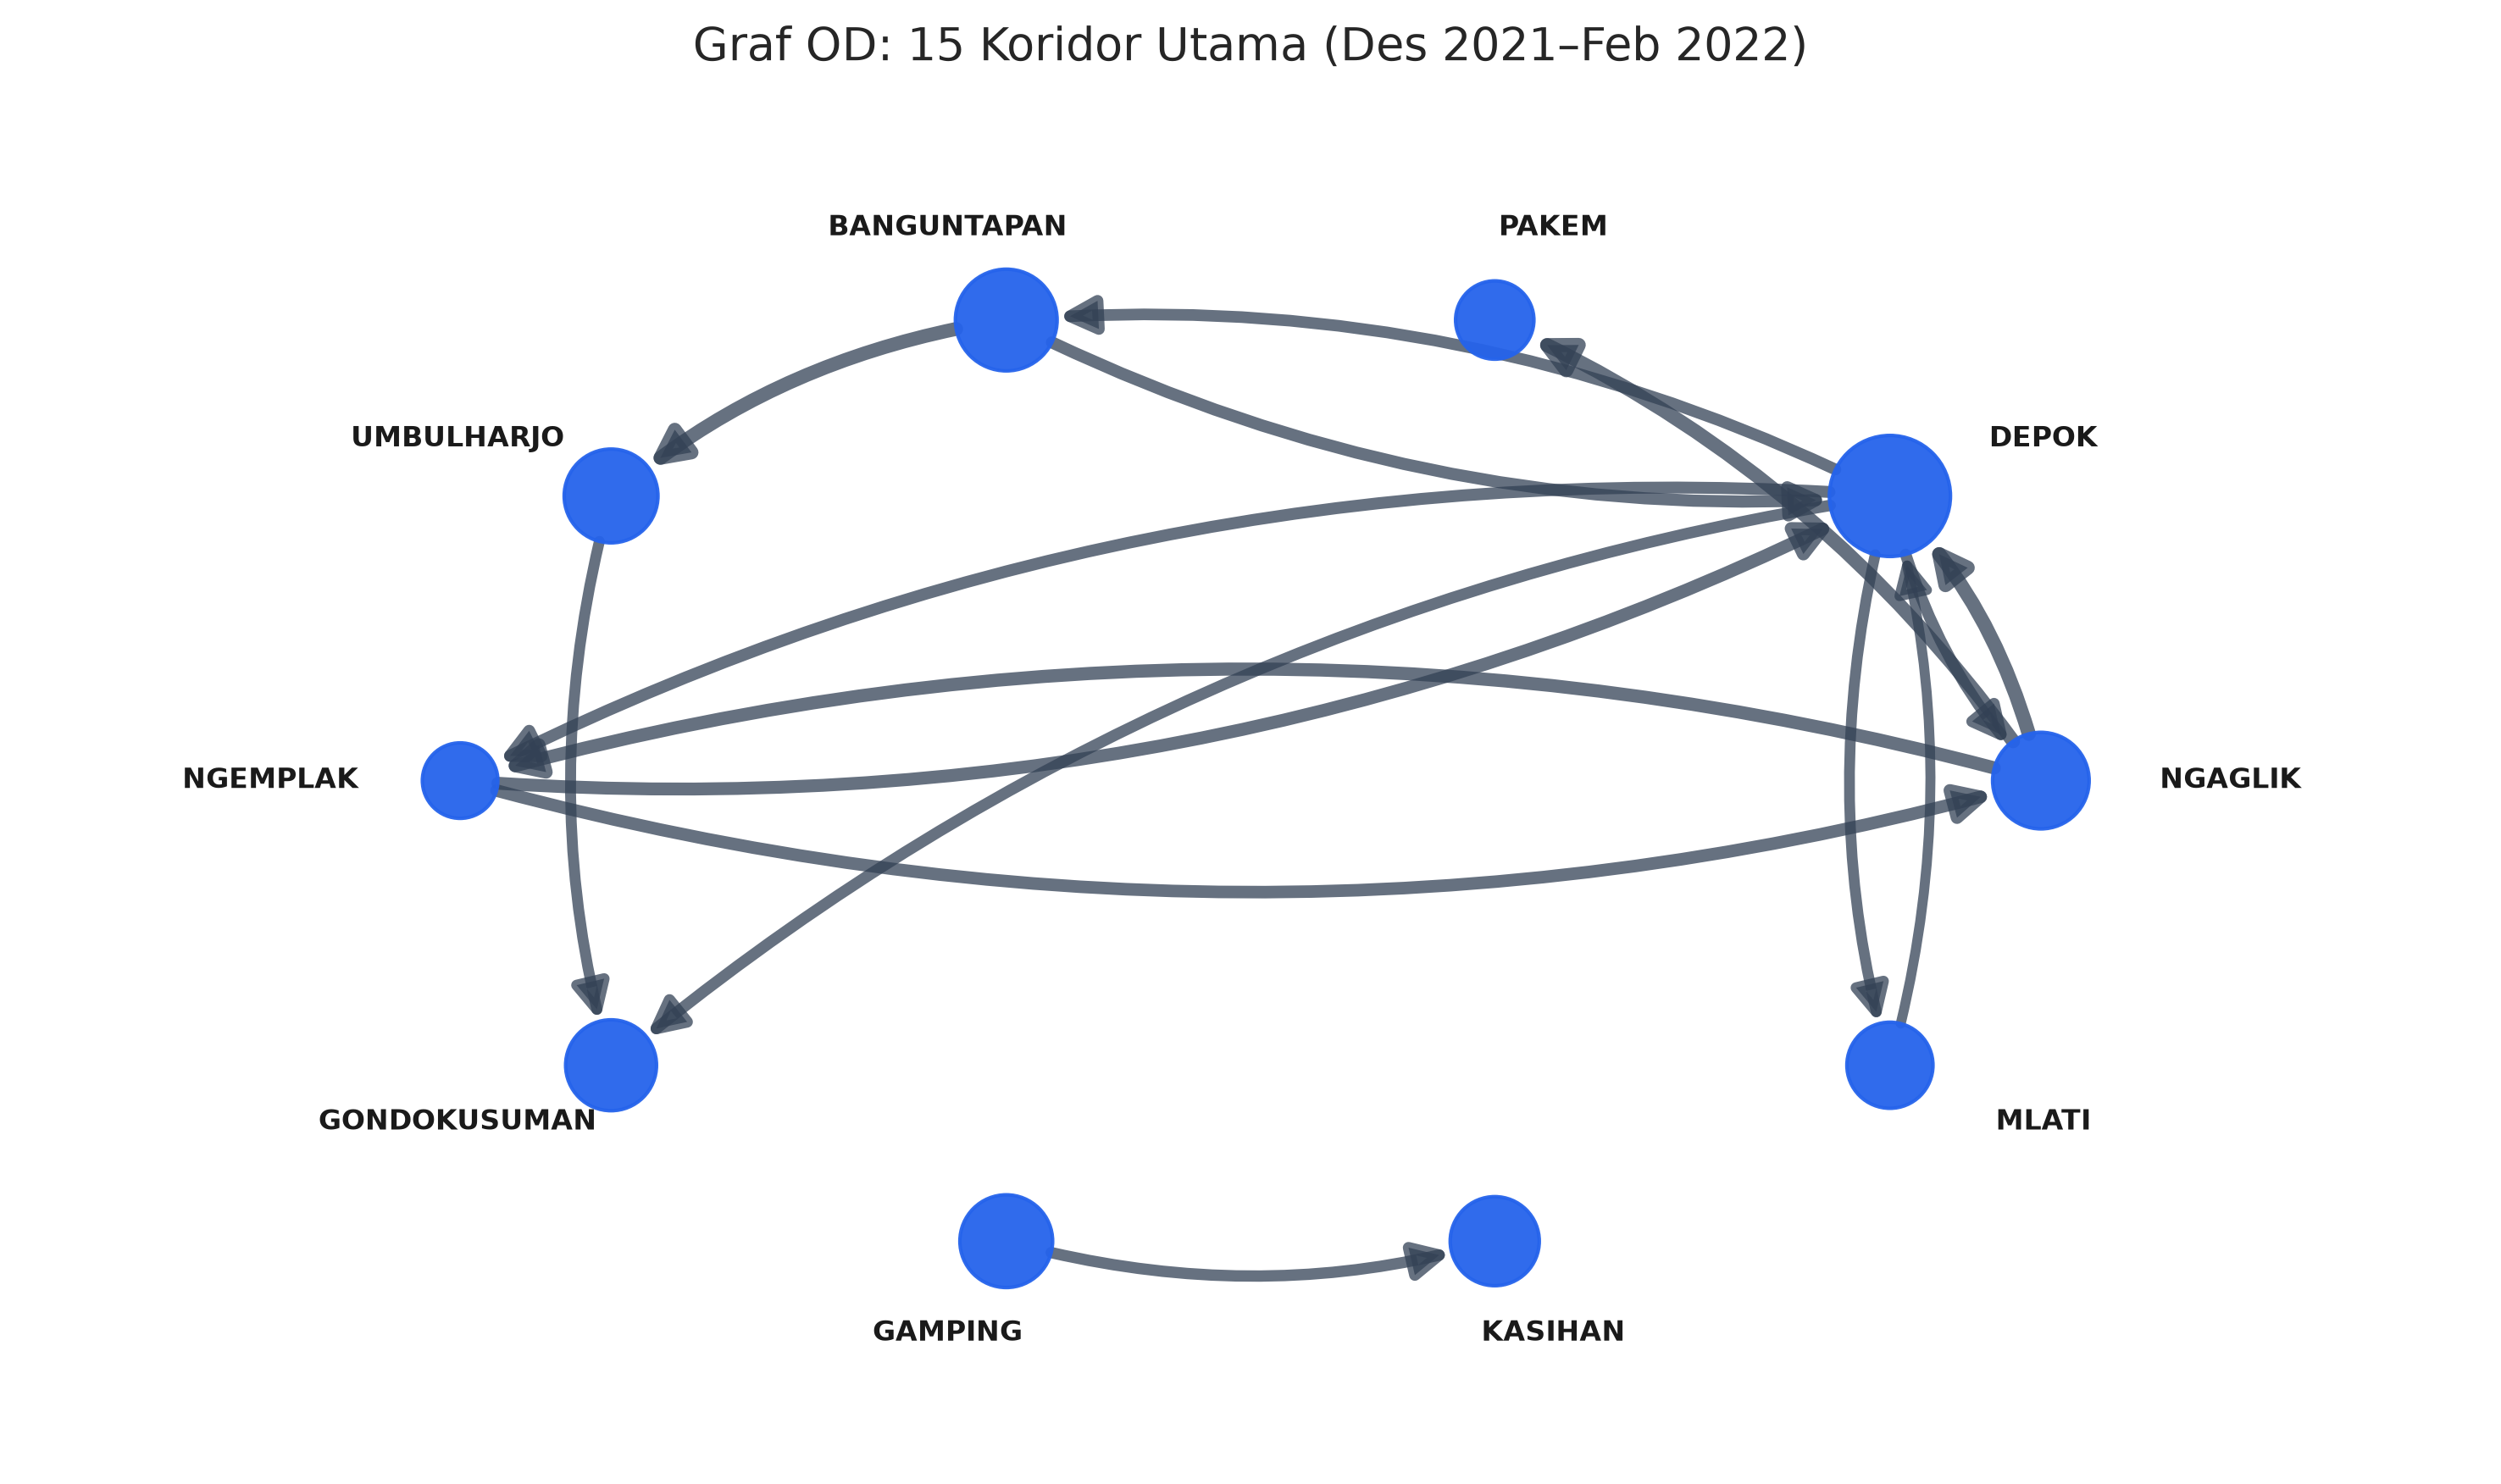

In [17]:
top_edges = edge_agg.nlargest(15, "n_maids")
G_vis = nx.DiGraph()
for _, row in top_edges.iterrows():
    G_vis.add_edge(row["origin_kapanewon_label"], row["dest_kapanewon_label"], weight=row["n_maids"])

pos = nx.circular_layout(G_vis)
node_sizes = [pagerank.get(n, 0.005) * 18000 for n in G_vis.nodes()]
max_w = top_edges["n_maids"].max()
edge_widths = [1.0 + 3.0 * (d["weight"] / max_w) for _, _, d in G_vis.edges(data=True)]

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
nx.draw_networkx_nodes(G_vis, pos, node_size=node_sizes, node_color="#2563eb", alpha=0.95, ax=ax)
nx.draw_networkx_edges(
    G_vis,
    pos,
    node_size=node_sizes,
    width=edge_widths,
    alpha=0.75,
    edge_color="#334155",
    arrows=True,
    arrowstyle="-|>",
    arrowsize=20,
    min_target_margin=12,
    connectionstyle="arc3,rad=0.14",
    ax=ax,
)

label_pos = {k: (v[0] * 1.24, v[1] * 1.20) for k, v in pos.items()}
nx.draw_networkx_labels(G_vis, label_pos, font_size=8, font_weight="bold", ax=ax)

ax.set_xlim(-1.55, 1.55)
ax.set_ylim(-1.40, 1.40)
ax.set_title("Graf OD: 15 Koridor Utama (Des 2021–Feb 2022)", fontsize=13, pad=12)
ax.axis("off")
plt.tight_layout()
plt.savefig("figures/07a_network_graph_od.png", dpi=300, bbox_inches="tight")
plt.show()

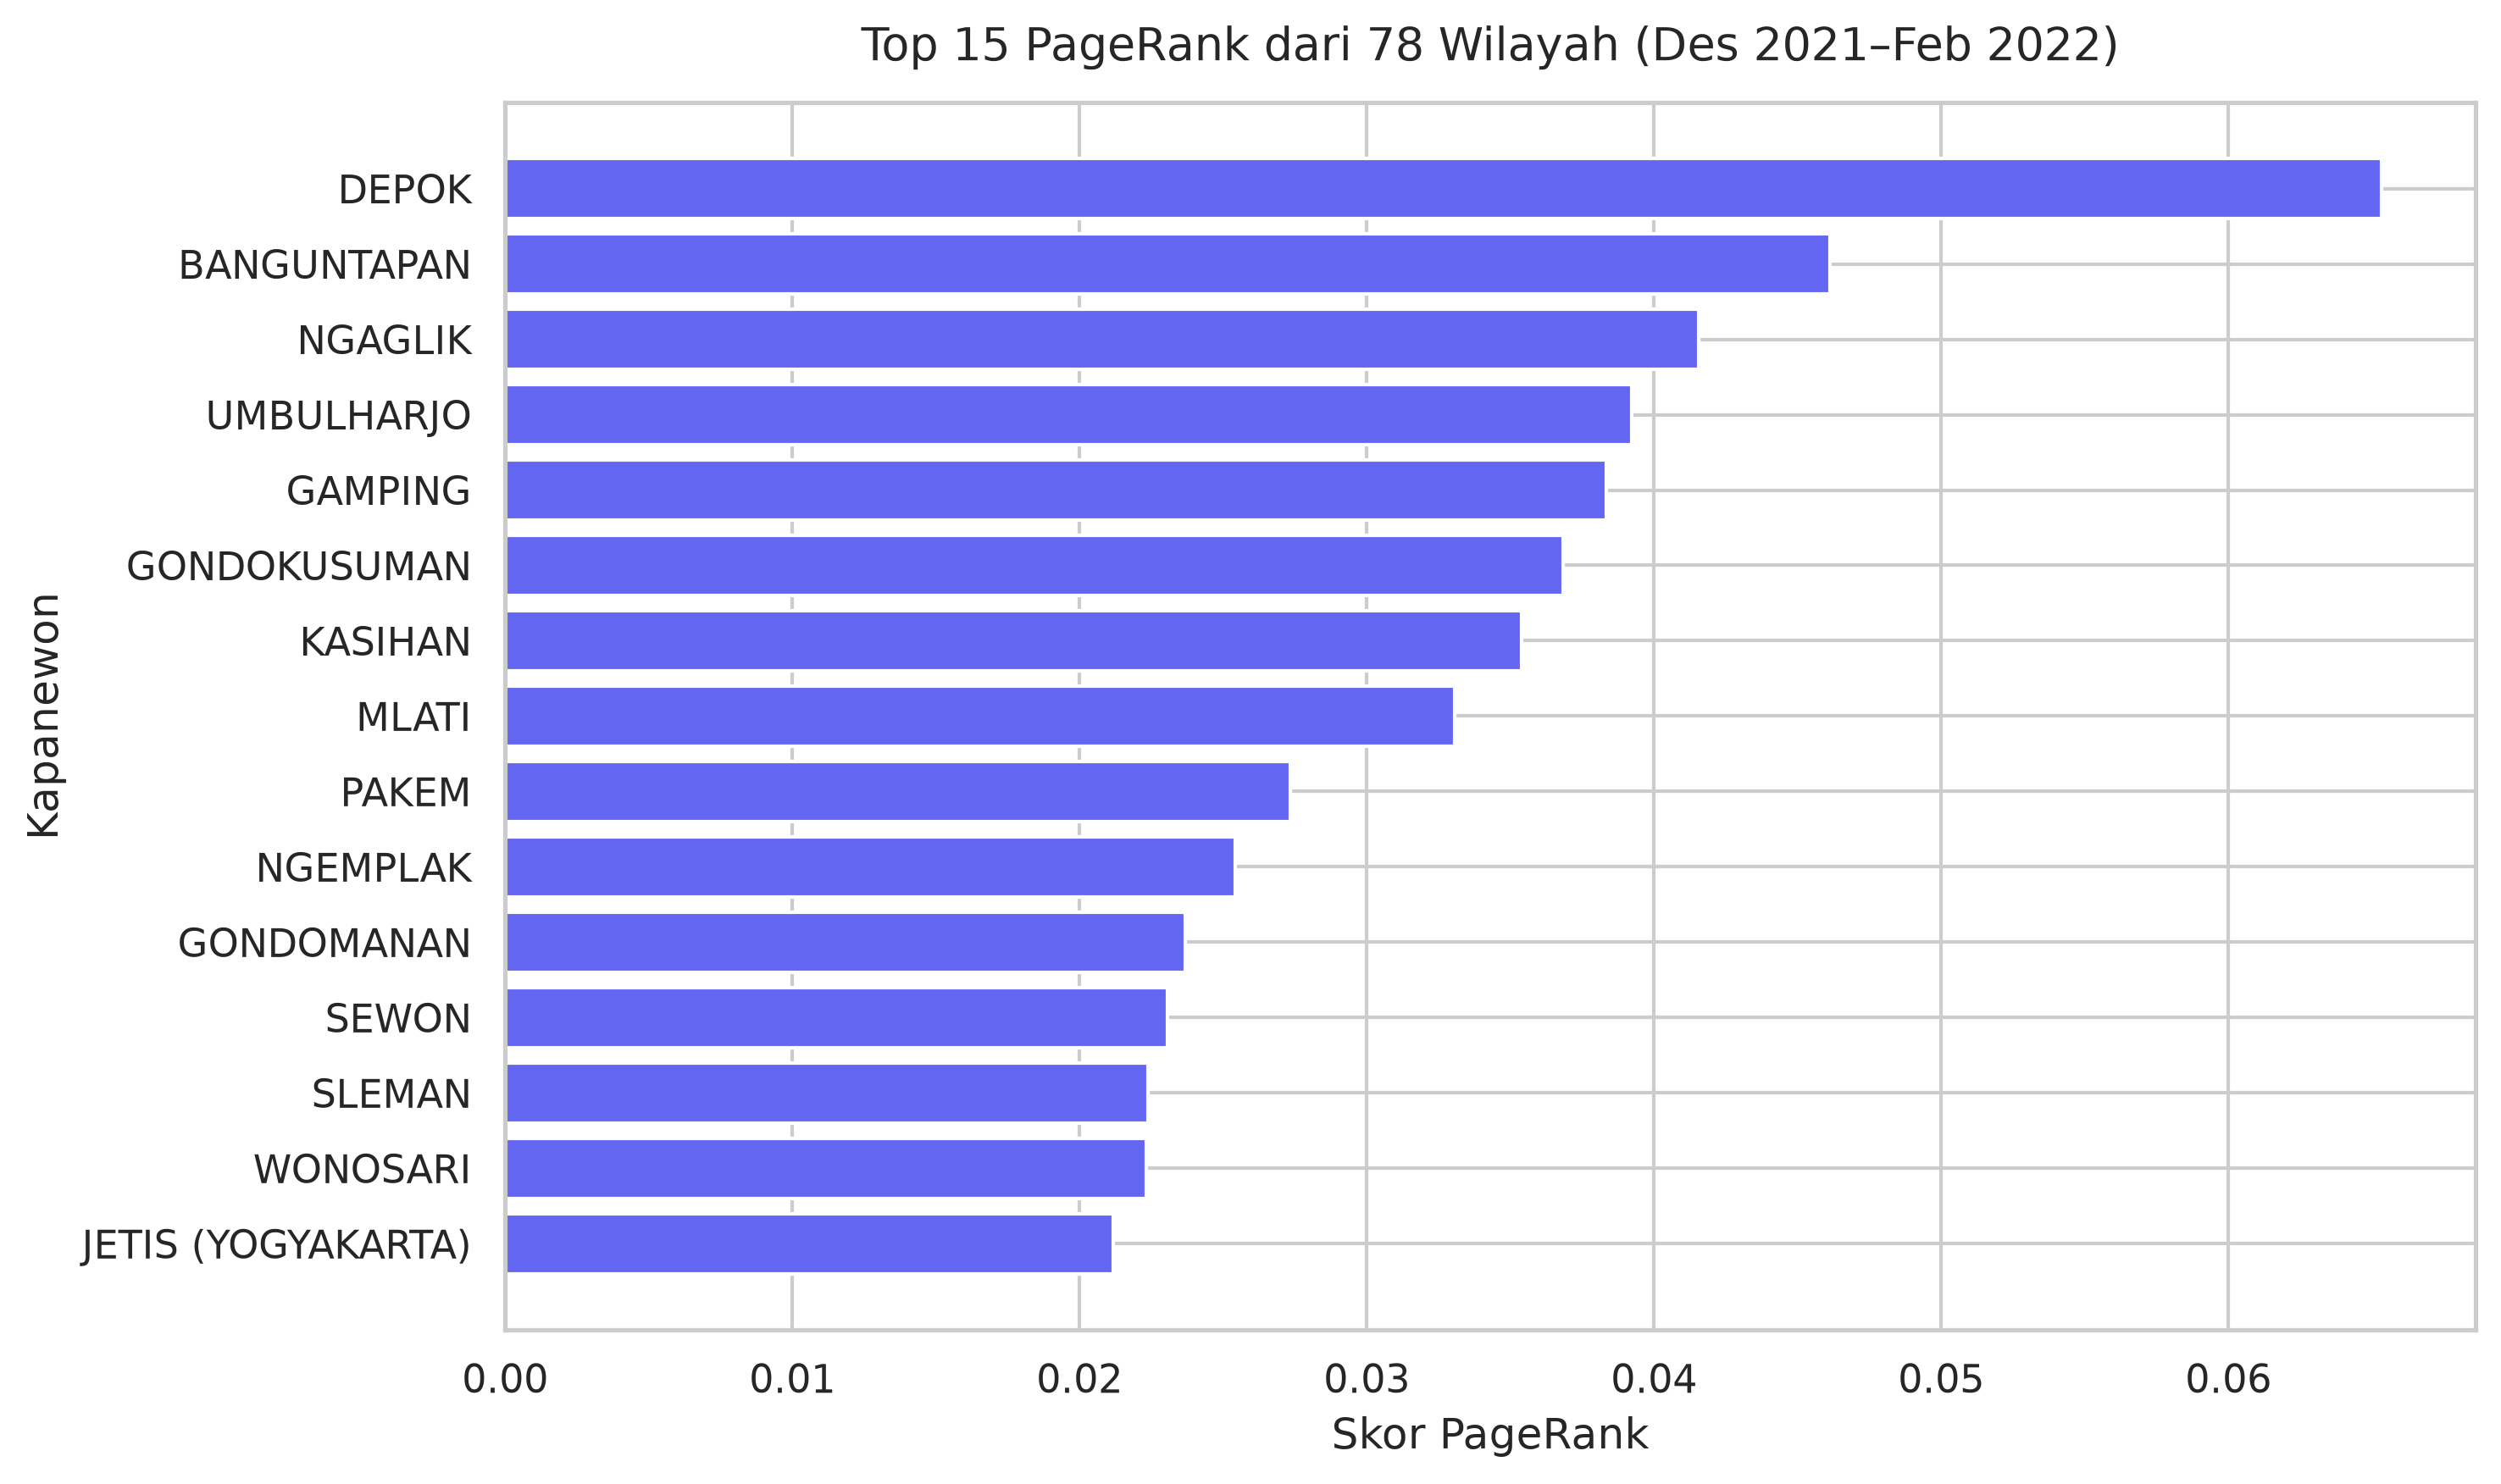

In [18]:
top15_pr = centrality_df.head(15).sort_values("pagerank", ascending=True)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.barh(top15_pr["kapanewon"], top15_pr["pagerank"], color="#6366f1")
ax.set_title("Top 15 PageRank dari 78 Wilayah (Des 2021–Feb 2022)", fontsize=13, pad=12)
ax.set_xlabel("Skor PageRank")
ax.set_ylabel("Kapanewon")
plt.tight_layout()
plt.savefig("figures/07b_top15_pagerank_kapanewon.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Bagian 7:**
- Graf lengkap periode utama memiliki **78 simpul**, dengan dua Jetis terpisah dan **0 self-loop**.
- Lima skor PageRank tertinggi pada periode utama adalah **Depok (0,065340)**, **Banguntapan (0,046128)**, **Ngaglik (0,041569)**, **Umbulharjo (0,039231)**, dan **Gamping (0,038342)**. **Jetis (Yogyakarta)** berada di peringkat ke-15 (**0,021161**), sedangkan **Jetis (Bantul)** di peringkat ke-28 (**0,012239**).
- PageRank merangkum posisi wilayah dalam jaringan OD terpublikasi yang berbobot `n_maids`. Grafik 7A hanya menampilkan sebagian koridor, tetapi PageRank tetap dihitung dari seluruh graf periode utama.


## Bagian 8: Tren OD Bulanan & Evaluasi Kualitas Data (`reduced_quality`)

Menggunakan seluruh **lima bulan, Desember 2021–April 2022**, untuk tren bulanan per kabupaten/kota tujuan dan perbandingan kualitas data. Jumlah pasangan OD terpublikasi dirata-ratakan per bulan agar durasi tiga bulan periode utama dan dua bulan reduced_quality dapat dibandingkan. Pasangan yang tidak terpublikasi dapat tersupresi dan tidak otomatis tidak aktif.


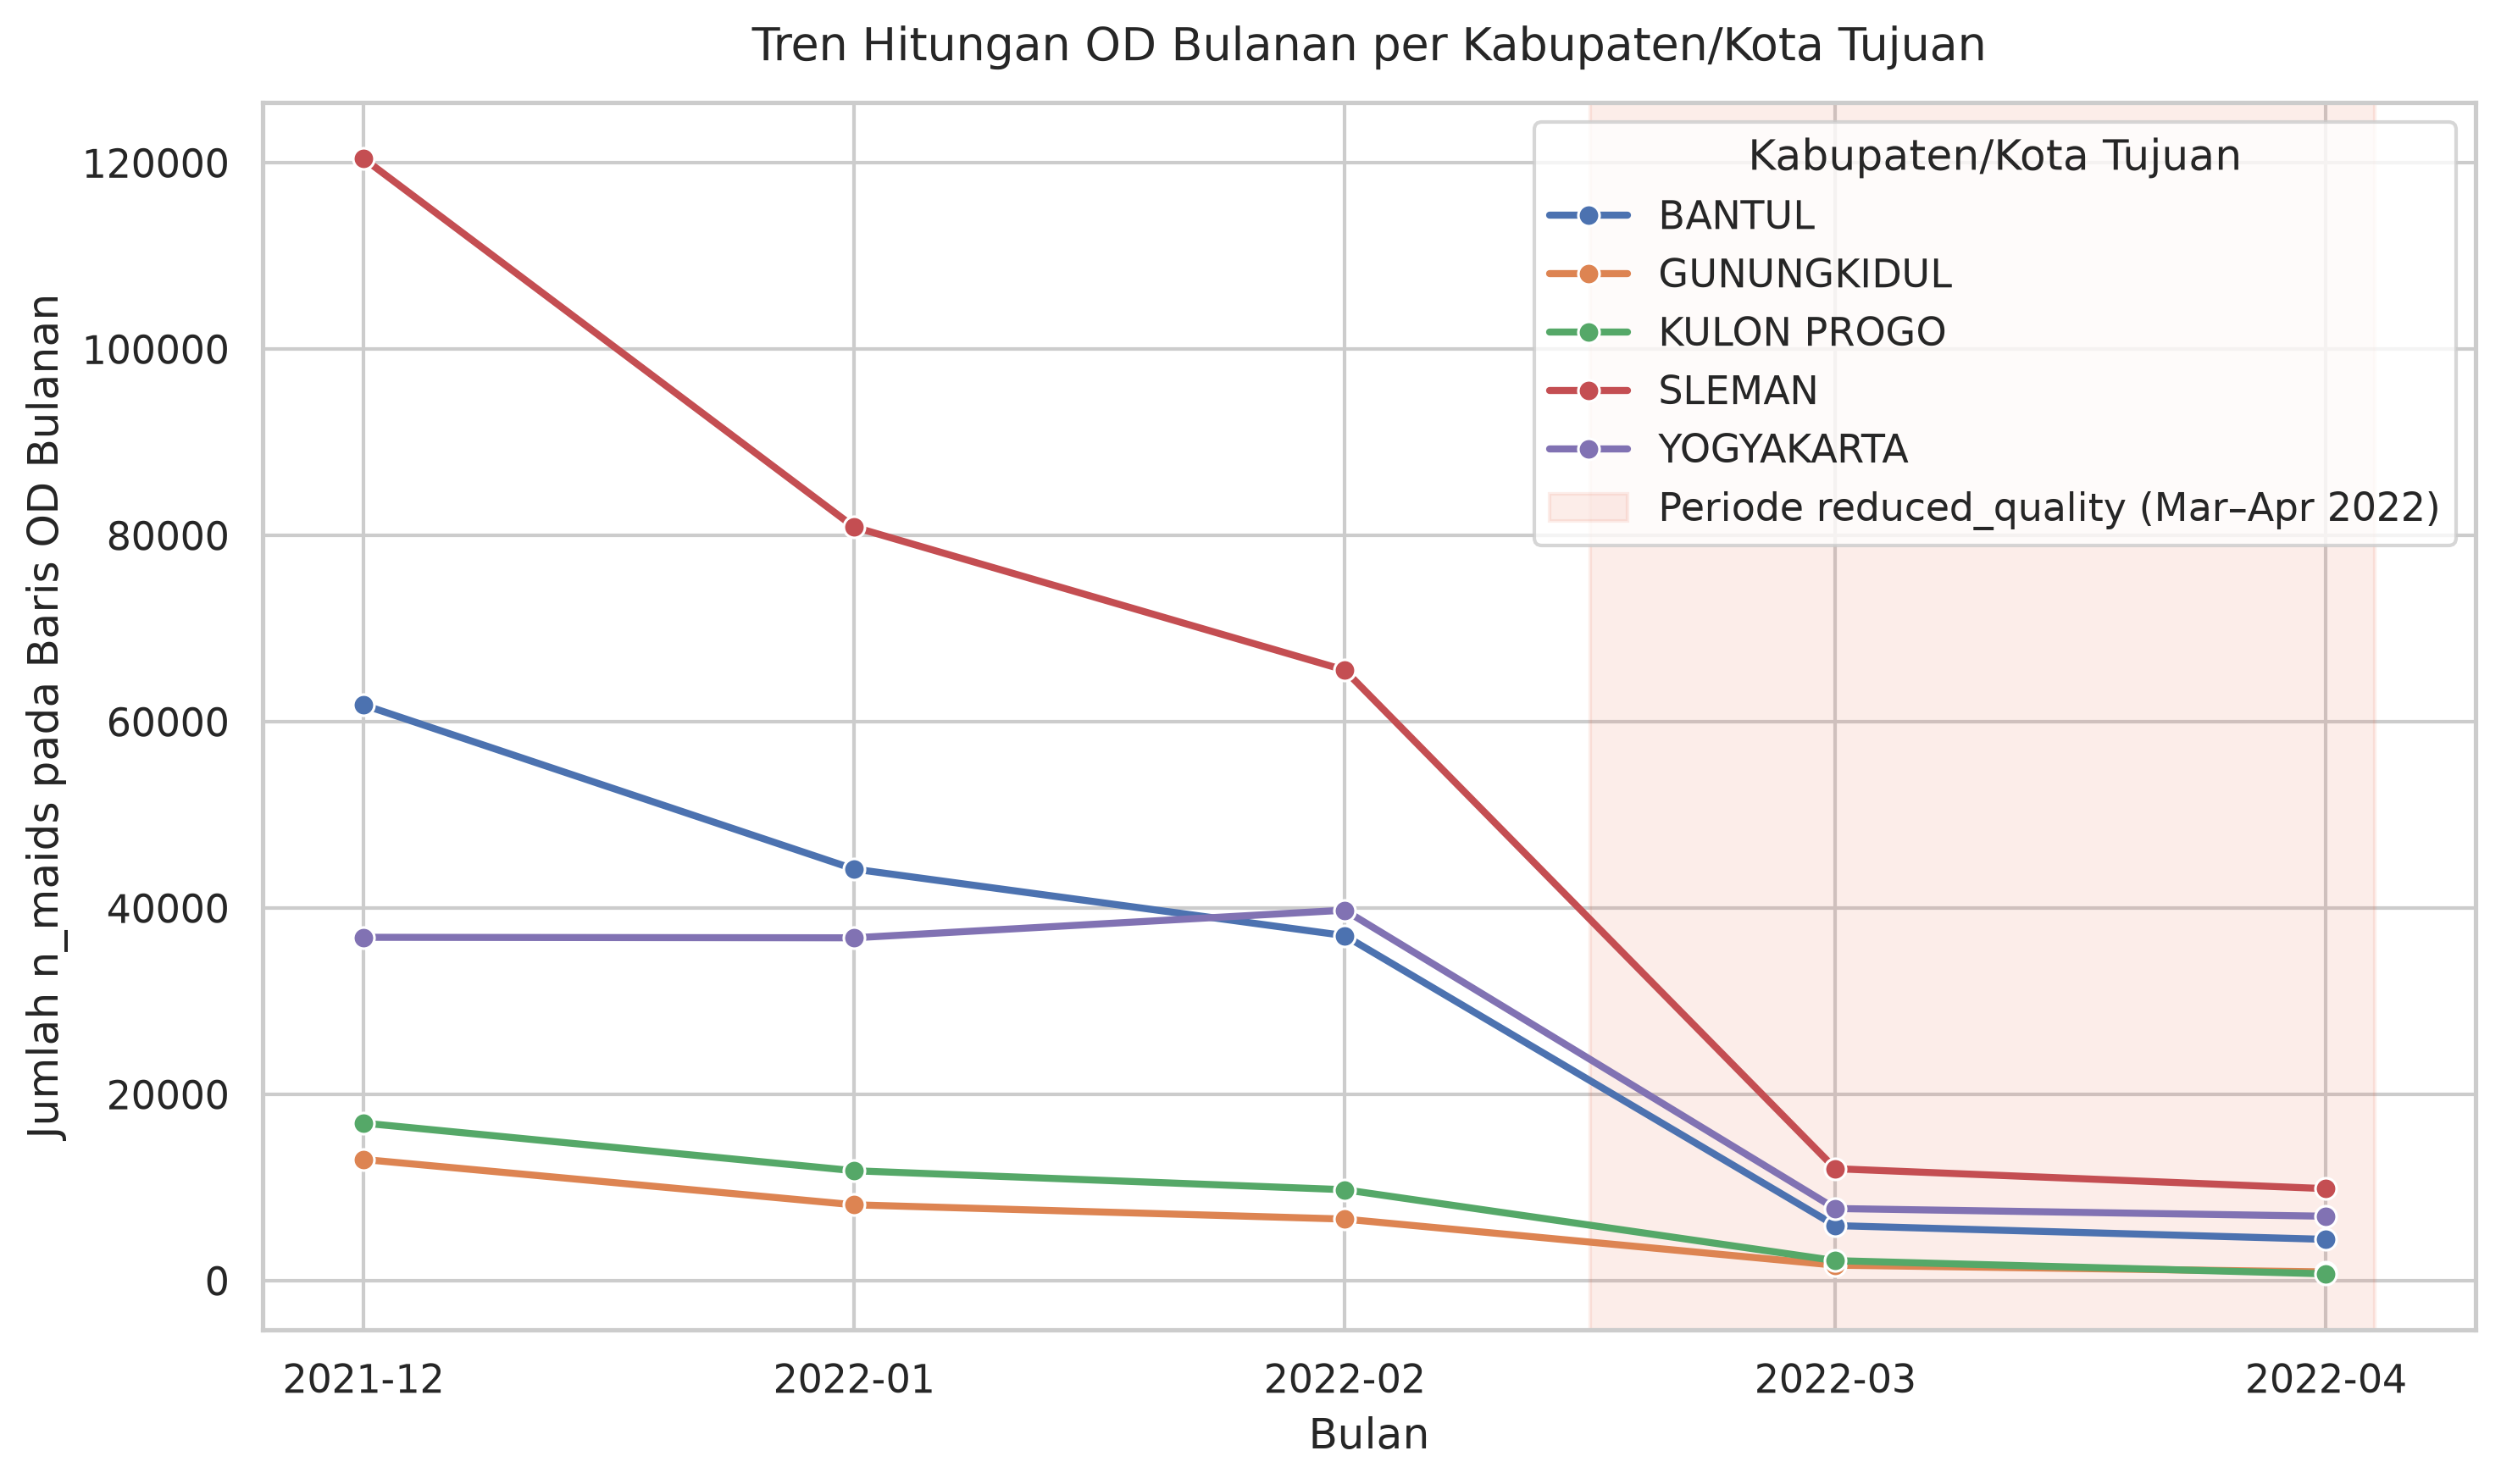

In [19]:
df_od["month"] = df_od["month"].astype(str)
monthly_dest = (
    df_od.groupby(["month", "dest_kab_kota"])["n_maids"]
    .sum()
    .reset_index()
    .sort_values("month")
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.lineplot(
    data=monthly_dest,
    x="month",
    y="n_maids",
    hue="dest_kab_kota",
    marker="o",
    linewidth=2,
    ax=ax,
)
ax.axvspan(2.5, 4.1, color="#e76f51", alpha=0.12, label="Periode reduced_quality (Mar–Apr 2022)")
ax.set_title("Tren Hitungan OD Bulanan per Kabupaten/Kota Tujuan", fontsize=13, pad=12)
ax.set_xlabel("Bulan")
ax.set_ylabel("Jumlah n_maids pada Baris OD Bulanan")
ax.legend(title="Kabupaten/Kota Tujuan", frameon=True)
plt.tight_layout()
plt.savefig("figures/08a_tren_bulanan_od_kabkota.png", dpi=300, bbox_inches="tight")
plt.show()

                  status_kualitas  pasangan_od_terpublikasi  jumlah_bulan  rata_rata_maids  pasangan_terpublikasi_per_bulan
Periode Utama (Des 2021–Feb 2022)                      7872             3        74.931021                           2624.0
   Reduced Quality (Mar–Apr 2022)                      2022             2        25.988625                           1011.0


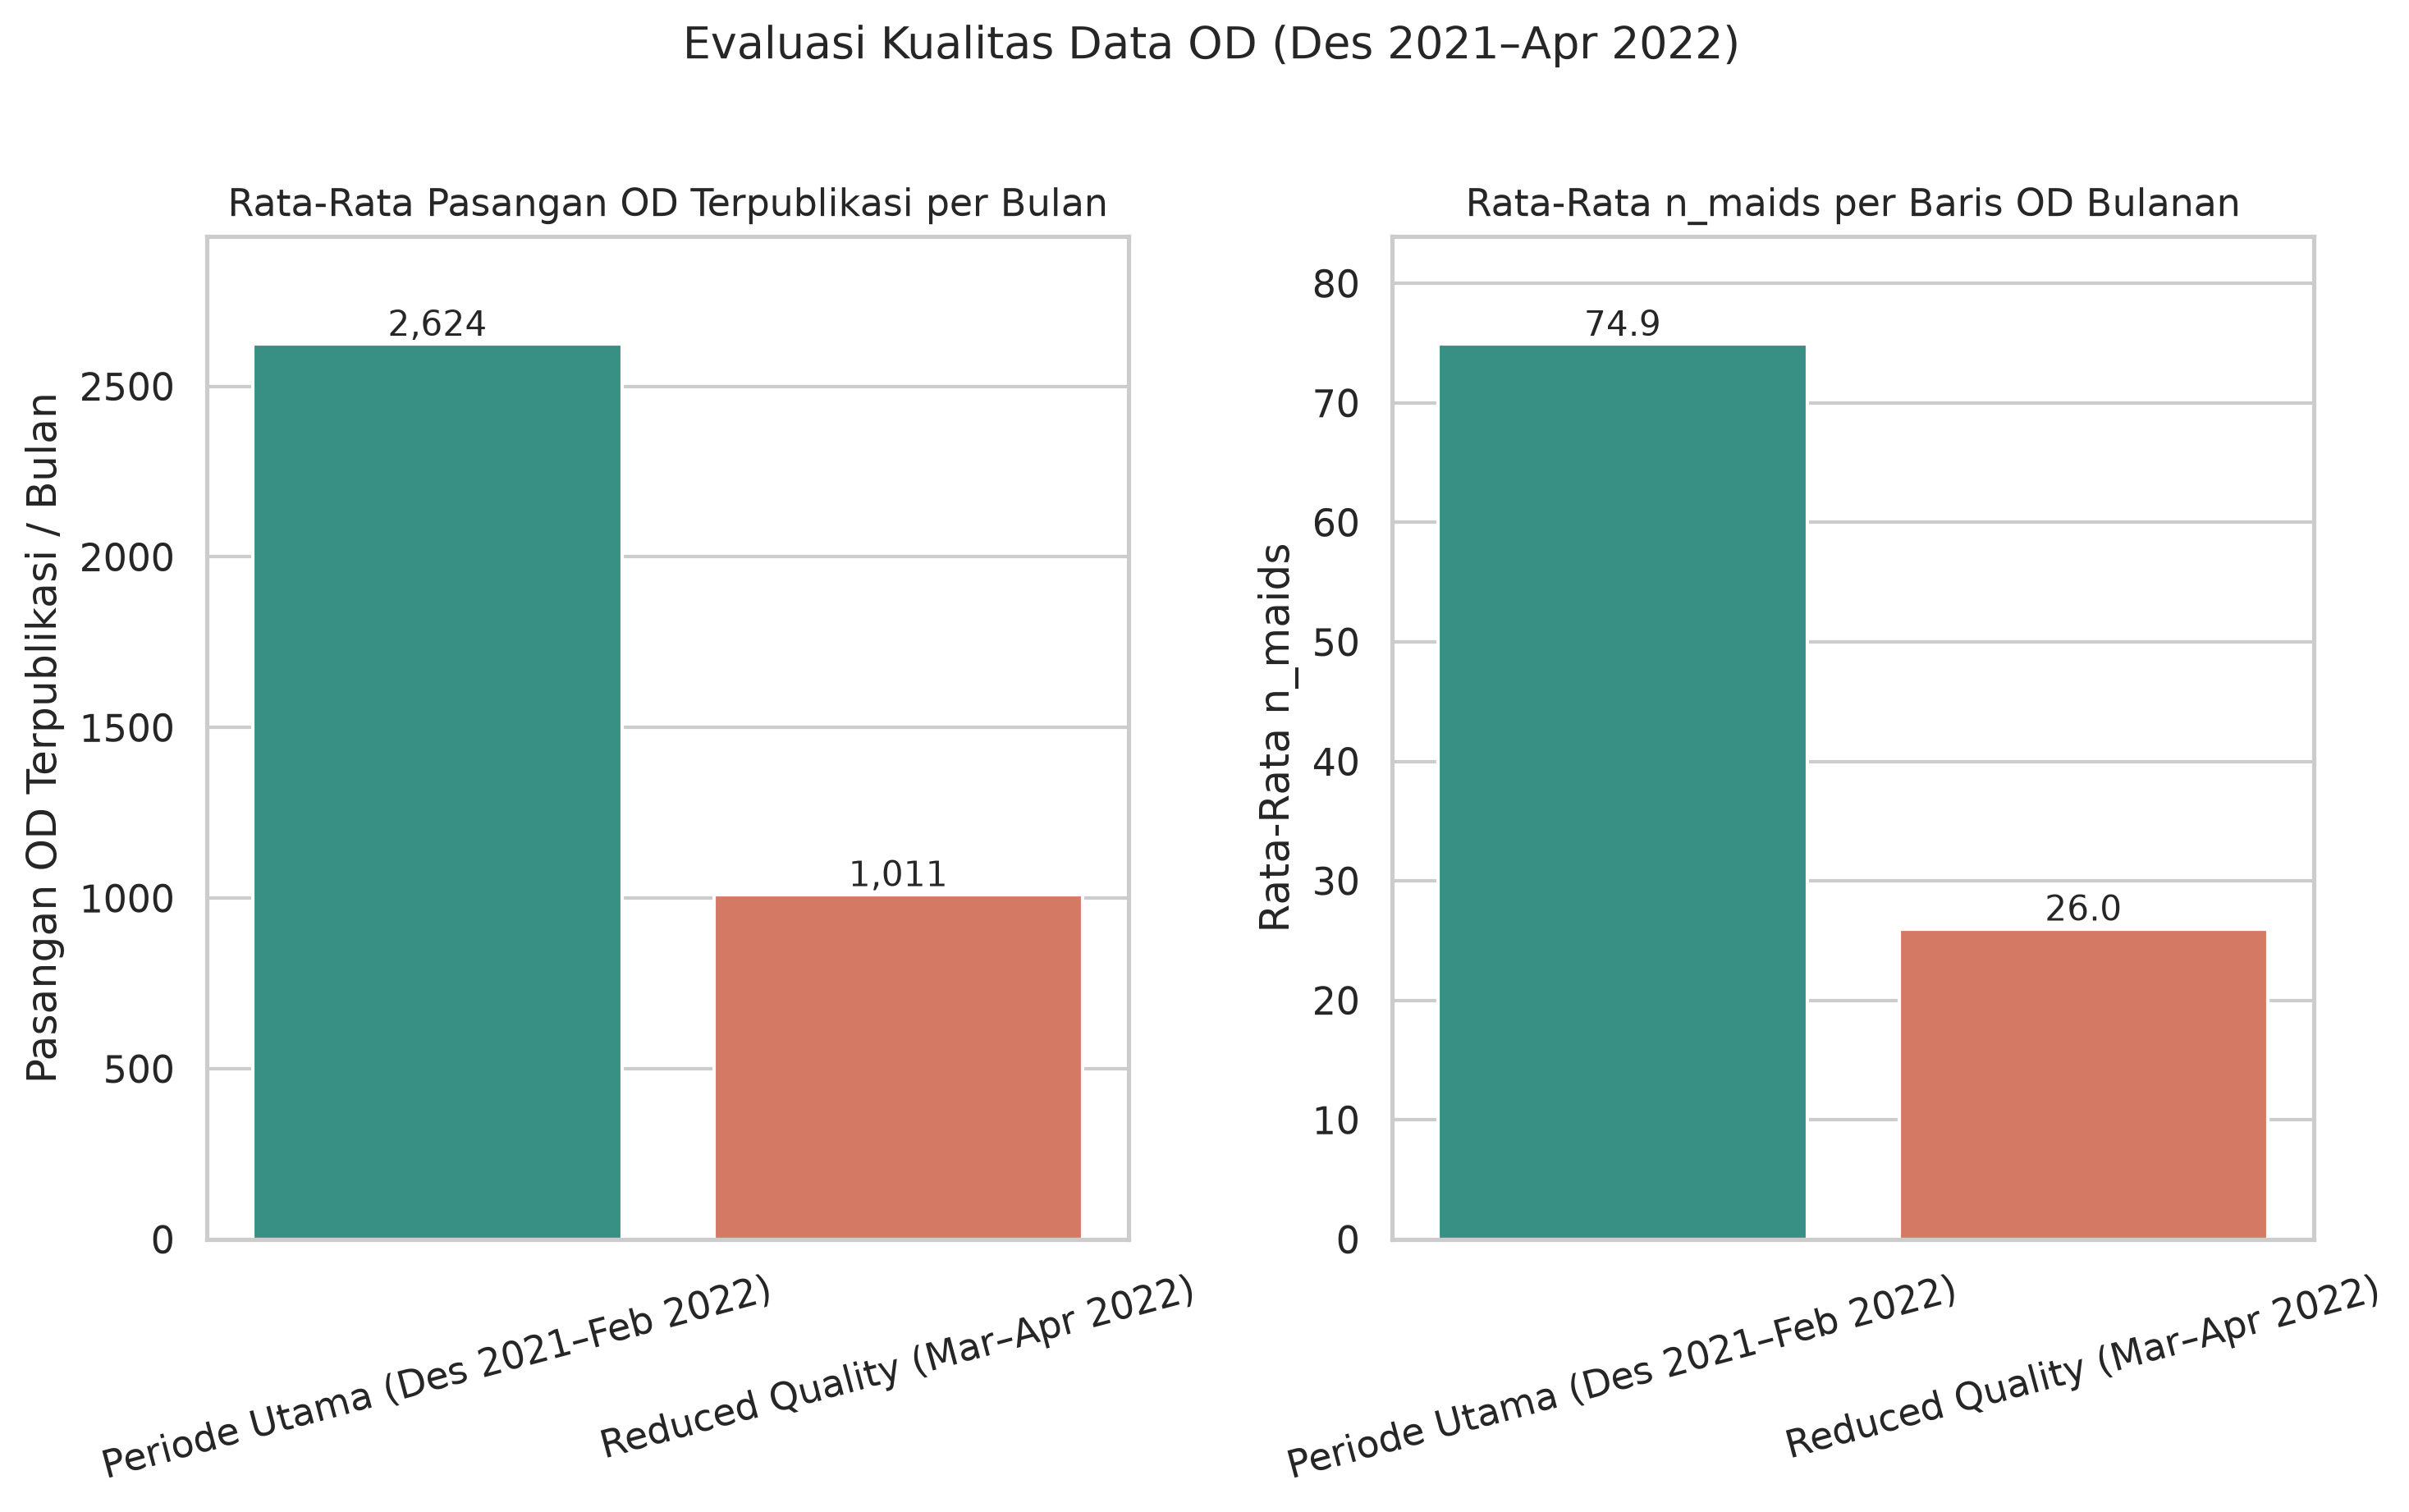

In [20]:
df_od["status_kualitas"] = np.where(
    df_od["reduced_quality"].astype(str).str.lower() == "true",
    "Reduced Quality (Mar–Apr 2022)",
    "Periode Utama (Des 2021–Feb 2022)",
)

quality_summary = (
    df_od.groupby("status_kualitas")
    .agg(
        pasangan_od_terpublikasi=("n_maids", "count"),
        jumlah_bulan=("month", "nunique"),
        rata_rata_maids=("n_maids", "mean"),
    )
    .reset_index()
)
quality_summary["pasangan_terpublikasi_per_bulan"] = (
    quality_summary["pasangan_od_terpublikasi"] / quality_summary["jumlah_bulan"]
)
print(quality_summary.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 6), dpi=300)
sns.barplot(
    data=quality_summary,
    x="status_kualitas",
    y="pasangan_terpublikasi_per_bulan",
    hue="status_kualitas",
    palette=["#2a9d8f", "#e76f51"],
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Rata-Rata Pasangan OD Terpublikasi per Bulan", fontsize=11)
axes[0].set_xlabel("")
axes[0].set_ylabel("Pasangan OD Terpublikasi / Bulan")
axes[0].set_ylim(0, quality_summary["pasangan_terpublikasi_per_bulan"].max() * 1.12)
axes[0].tick_params(axis="x", rotation=15)
for bar in axes[0].patches:
    axes[0].annotate(
        f"{bar.get_height():,.0f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
    )

sns.barplot(
    data=quality_summary,
    x="status_kualitas",
    y="rata_rata_maids",
    hue="status_kualitas",
    palette=["#2a9d8f", "#e76f51"],
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Rata-Rata n_maids per Baris OD Bulanan", fontsize=11)
axes[1].set_xlabel("")
axes[1].set_ylabel("Rata-Rata n_maids")
axes[1].set_ylim(0, quality_summary["rata_rata_maids"].max() * 1.12)
axes[1].tick_params(axis="x", rotation=15)
for bar in axes[1].patches:
    axes[1].annotate(
        f"{bar.get_height():.1f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
    )

fig.suptitle("Evaluasi Kualitas Data OD (Des 2021–Apr 2022)", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig("figures/08b_evaluasi_reduced_quality.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight Bagian 8:**
- Rata-rata jumlah pasangan OD terpublikasi turun **61,5%**, dari **2.624 pasangan/bulan** pada Desember–Februari menjadi **1.011 pasangan/bulan** pada Maret–April. Ini mengukur baris yang terpublikasi, bukan seluruh pasangan yang benar-benar aktif.
- Rata-rata `n_maids` per baris OD bulanan turun **65,3%**, dari **74,9** menjadi **26,0**. Nilai rata-rata ini juga dipengaruhi oleh pasangan mana yang lolos supresi.
- Penurunan angka mentah tidak cukup untuk menyimpulkan penurunan mobilitas masyarakat karena cakupan sampel dan supresi berubah. Februari tidak berstatus reduced_quality, tetapi cakupan perangkat mulai turun pada 16 Februari.
